<a href="https://colab.research.google.com/github/etsubdink-m/msc-research/blob/main/msc_cs_research_revamped.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hepatitis Classification — Module A: Tabular Pipeline

**MSc thesis, Addis Ababa University — Department of Computer Science (Data and Web Engineering)**

This notebook implements the complete preprocessing and analysis pipeline
for Module A (the tabular hepatitis classifier) of the dual-pathway thesis
framework. It uses routine laboratory records from Arsho Medical Laboratory,
Ethiopia.

The notebook is structured into clearly numbered stages so that the order
of operations is explicit and the train-test boundary (after which the test
partition is sealed) is visible at a glance.

## Pipeline structure

| Stage | What it does | Section |
|---|---|---|
| 1   | Merge raw v1 + v2 datasets into a single canonical CSV       | §3 |
| 2   | Exploratory data analysis (cohort description, separability) | §4 |
| 3A  | Pre-split cleanup (universal, target-independent)            | §5 |
| 3B  | **Train-test split — test partition is sealed here**         | §6 |
| 3C  | Preprocessing pipeline (imputation, scaling, encoding)       | next |
| 3D  | Modelling (LR, DT, RF, GB)                                   | next |

**Author:** Etsubdink Mekonnen
**Last updated:** April 2026

## 1. Environment Setup

Mount Google Drive once and import every library used anywhere in the notebook.
Everything below this section assumes these names are in scope.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Standard library
import os
import sys
import json
from pathlib import Path
from datetime import datetime, timezone
from typing import Dict, List, Optional, Tuple

# Scientific stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-learn (used in Stage 3B onward)
from sklearn.model_selection import train_test_split

# Display options
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)
pd.set_option('display.float_format',
              lambda x: f'{x:,.4f}' if abs(x) < 1 else f'{x:,.2f}')

print(f"pandas {pd.__version__}, numpy {np.__version__}, "
      f"python {sys.version.split()[0]}")

pandas 2.2.2, numpy 2.0.2, python 3.12.13


## 2. Configuration

All paths, constants, and styling for the entire notebook live here. To
re-run the pipeline against a different folder layout, edit only this
section.

In [ ]:
# ---- Project layout in Google Drive ---------------------------------------
PROJECT_ROOT  = Path('/content/drive/MyDrive/MSc_Thesis/hepatitis_module_a')
RAW_DIR       = PROJECT_ROOT / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'processed'
FIGURES_DIR   = PROJECT_ROOT / 'figures'
TABLES_DIR    = PROJECT_ROOT / 'tables'

for d in (PROCESSED_DIR, FIGURES_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Source files --------------------------------------------------------
RAW_FILES = {
    'v1': RAW_DIR / 'lab-data-1.csv',   # Oct 2025 - Mar 2026
    'v2': RAW_DIR / 'lab-data-2.csv',   # May 2024 - Oct 2025
}

# ---- Output files --------------------------------------------------------
MERGED_FILE  = PROCESSED_DIR / 'lab-data-combined.csv'
STAGE3A_FILE = PROCESSED_DIR / 'lab-data-stage3a.csv'

# ---- Eligibility criteria ------------------------------------------------
AGE_MIN, AGE_MAX = 17, 70

# ---- Train-test split parameters ----------------------------------------
TEST_SIZE   = 0.20
RANDOM_SEED = 42
AGE_BANDS   = [(17, 29), (30, 39), (40, 70)]

# ---- Targets and feature groupings --------------------------------------
PRIMARY_TARGET   = 'hbsag'
SECONDARY_TARGET = 'anti_hcv'

CONTINUOUS_FEATURES = [
    'age', 'haemoglobin', 'rbs', 'creatinine', 'ast', 'alt',
    'platelets', 'wbc', 'rbc', 'alp', 'bun',
]

CONTINUOUS_LABELS = {
    'age': 'Age (years)',
    'haemoglobin': 'Haemoglobin (g/dL)',
    'rbs': 'Random Blood Sugar (mg/dL)',
    'creatinine': 'Creatinine (mg/dL)',
    'ast': 'AST (U/L)', 'alt': 'ALT (U/L)',
    'platelets': 'Platelets (/μL)',
    'wbc': 'WBC (/μL)', 'rbc': 'RBC (/μL)',
    'alp': 'ALP (U/L)', 'bun': 'BUN (mg/dL)',
}

CATEGORICAL_FEATURES = ['sex', 'blood_group']
AUXILIARY_SEROLOGY   = ['hiv', 'vdrl', 'tpha', 'pregnancy', 'malaria', 'filaria']

# ---- Visual style -------------------------------------------------------
TEAL = '#0F766E'   # negatives
RUST = '#C2410C'   # positives
GREY = '#94A3B8'
INK  = '#1F2937'
PALETTE_BINARY = [TEAL, RUST]

sns.set_style('whitegrid')
plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.size':         11,
    'axes.titlesize':    13,
    'axes.titleweight':  'bold',
    'axes.labelsize':    11,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':        100,
    'savefig.dpi':       300,
    'savefig.bbox':      'tight',
    'savefig.facecolor': 'white',
})

# ---- Verify source files ------------------------------------------------
for name, path in RAW_FILES.items():
    assert path.exists(), f"Source file missing: {path}"

print("Configuration loaded.")
print(f"  Project root:    {PROJECT_ROOT}")
print(f"  Raw files:       {[p.name for p in RAW_FILES.values()]}")
print(f"  Random seed:     {RANDOM_SEED}")
print(f"  Train/test ratio: {1 - TEST_SIZE:.0%} / {TEST_SIZE:.0%}")

Configuration loaded.
  Project root:    /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a
  Raw files:       ['lab-data-1.csv', 'lab-data-2.csv']
  Random seed:     42
  Train/test ratio: 80% / 20%


## 3. Stage 1 — Merge Raw Datasets

This stage harmonises the two raw datasets received from Arsho Medical
Laboratory into a single canonical CSV.

The two source datasets cover different time periods and use different
column names, encodings, and conventions for the same clinical concepts:

- **v1** (Oct 2025 – Mar 2026): string serology labels (`"Positive"`),
  separate `blood_group` and `blood_group_rh` columns, historical lab
  abbreviations (`sgot`, `sgpt`).
- **v2** (May 2024 – Oct 2025): numeric serology codes (`1` = negative,
  `2` = positive, `4` = pending), combined `bldgrp` field, modern abbreviations.

Section 3 maps both into a single canonical schema, applies a documented
set of exclusions, resolves the small temporal overlap, and writes the
result to `processed/lab-data-combined.csv`.

### 3.1 Load Raw Datasets

Load both source files unchanged and report shape + column overlap.

In [ ]:
df_v1_raw = pd.read_csv(RAW_FILES['v1'])
df_v2_raw = pd.read_csv(RAW_FILES['v2'])

print(f"v1 (Oct 2025 - Mar 2026): {df_v1_raw.shape[0]:,} rows x {df_v1_raw.shape[1]} columns")
print(f"v2 (May 2024 - Oct 2025): {df_v2_raw.shape[0]:,} rows x {df_v2_raw.shape[1]} columns")

v1 (Oct 2025 - Mar 2026): 8,605 rows x 24 columns
v2 (May 2024 - Oct 2025): 36,710 rows x 29 columns


In [ ]:
v1_cols = set(df_v1_raw.columns)
v2_cols = set(df_v2_raw.columns)

print(f"Columns in v1 only ({len(v1_cols - v2_cols)}):")
print(f"  {sorted(v1_cols - v2_cols)}")
print(f"\nColumns in v2 only ({len(v2_cols - v1_cols)}):")
print(f"  {sorted(v2_cols - v1_cols)}")
print(f"\nColumns shared verbatim ({len(v1_cols & v2_cols)}):")
print(f"  {sorted(v1_cols & v2_cols)}")

Columns in v1 only (11):
  ['ID', 'anti_hcv', 'blood_group', 'blood_group_rh', 'heamoglobin', 'micro_filaria', 'platelets', 'registered_datetime', 'sex', 'sgot', 'sgpt']

Columns in v2 only (16):
  ['albumin', 'alt', 'ast', 'bldgrp', 'cyst', 'filaria', 'gender', 'haemoglobin', 'hcv', 'helminthes', 'hemoparasite', 'lft', 'odate', 'ova', 'platelete', 'sugar']

Columns shared verbatim (13):
  ['age', 'alp', 'bun', 'creatinine', 'hbsag', 'hiv', 'malaria', 'pregnancy', 'rbc', 'rbs', 'tpha', 'vdrl', 'wbc']


### 3.2 Encoding Configuration

The two datasets use different conventions for binary serological labels:

| Result | v1 | v2 |
|---|---|---|
| Negative | `"Negative"` (string, may have trailing spaces) | `1` (numeric) |
| Positive | `"Positive"` (string)                          | `2` (numeric) |
| Pending  | not present                                    | `4` (numeric) |
| Not applicable (pregnancy, males) | `"-"`                | `0` (numeric) |

Both are mapped to the canonical scheme `0 = Negative, 1 = Positive,
NaN = unknown / pending / not applicable`. Pending (code 4) and not-applicable
values become `NaN` — they should never serve as training labels.

In [ ]:
# v1 uses string labels. VDRL and TPHA use the reactive/non-reactive
# convention, while other serology columns use negative/positive. Both are
# accepted here so a single map covers every column in v1.
V1_SEROLOGY_MAP = {
    'Negative':     0,
    'Positive':     1,
    'Non-Reactive': 0,   # VDRL / TPHA convention
    'Reactive':     1,   # VDRL / TPHA convention
    '-':            np.nan,   # pregnancy: not applicable for males
}

# v2 uses numeric codes
V2_SEROLOGY_MAP = {
    1.0: 0,       # Negative
    2.0: 1,       # Positive
    4.0: np.nan,  # Pending result, exclude from training
}

V2_PREGNANCY_MAP = {
    0.0: np.nan,  # Male, not applicable
    1.0: 0,       # Negative
    2.0: 1,       # Positive
    4.0: np.nan,  # Pending
}

# v1 sex labels to canonical single-letter form
V1_SEX_MAP = {'Female': 'F', 'Male': 'M'}

# Columns the canonical merged output must have, in order
CANONICAL_COLUMNS = [
    'age', 'sex', 'blood_group',
    'haemoglobin', 'rbs', 'creatinine', 'ast', 'alt',
    'platelets', 'wbc', 'rbc', 'alp', 'bun',
    'hbsag', 'anti_hcv', 'hiv', 'vdrl', 'tpha',
    'pregnancy', 'malaria', 'filaria',
    'registered_datetime',
]

print(f"Canonical schema defined: {len(CANONICAL_COLUMNS)} columns")

Canonical schema defined: 22 columns


### 3.3 Helper Functions

Three small utilities that are applied identically to both datasets so the
same rule cannot drift between them.

In [ ]:
def encode_binary(series: pd.Series, mapping: Dict) -> pd.Series:
    """Translate a serology column to canonical 0/1/NaN.

    Normalises the string form before the dictionary lookup:
    - Strips leading/trailing whitespace
    - Collapses internal whitespace runs to a single space
    - Treats the hyphen in 'Non-Reactive' as optional (some lab exports
      drop or truncate the hyphen, e.g. 'Non Reacti' with trailing spaces)

    Anything that does not match a key in `mapping` after normalisation
    becomes NaN, preserving genuinely missing values.
    """
    if series.dtype == object:
        cleaned = (
            series.astype(str)
                  .str.strip()
                  .str.replace(r'\s+', ' ', regex=True)
                  .str.replace(r'^Non[- ]Reacti.*$', 'Non-Reactive',
                               regex=True, case=False)
        )
        cleaned = cleaned.where(cleaned != 'nan', np.nan)
    else:
        cleaned = series
    return cleaned.map(mapping)


def to_numeric_safe(series: pd.Series) -> pd.Series:
    """Coerce to numeric, mapping anything unparseable to NaN."""
    return pd.to_numeric(series, errors='coerce')


def log_exclusion(name: str, before: int, after: int, reason: str) -> None:
    """Print one line of the exclusion audit trail."""
    dropped = before - after
    pct = 100 * dropped / before if before else 0
    print(f"  {name:>3s}  {reason:<35s}  dropped {dropped:>5,d} "
          f"({pct:5.2f}%)  -> {after:,d} remaining")

### 3.4 Blood Group Normalisation

The two datasets use different conventions for blood group:

- v1 stores ABO and Rh in two separate columns (`blood_group` = "A", "B",
  "AB", "O" and `blood_group_rh` = "+ve" / "-ve").
- v2 stores them as a single field (`bldgrp` = "A+", "A-", etc.)

After raw concatenation, v1 produces strings like `"A+ve"` while v2 produces
`"A+"` for the same clinical category. The mapping below collapses both
conventions to a single canonical form (`A+`, `A-`, `B+`, `B-`, `AB+`,
`AB-`, `O+`, `O-`) and corrects rare typos.

In [ ]:
BLOOD_GROUP_NORMALISER = {
    # v1 conventions (with "+ve" / "-ve" suffix)
    'A+ve':  'A+',  'A-ve':  'A-',
    'B+ve':  'B+',  'B-ve':  'B-',
    'AB+ve': 'AB+', 'AB-ve': 'AB-',
    'O+ve':  'O+',  'O-ve':  'O-',
    # v2 conventions (already canonical)
    'A+':  'A+',  'A-':  'A-',
    'B+':  'B+',  'B-':  'B-',
    'AB+': 'AB+', 'AB-': 'AB-',
    'O+':  'O+',  'O-':  'O-',
    # known typo: 0+ve where 0 is the digit zero, not the letter O
    '0+ve': 'O+',
    # malformed entries -> NaN (will be imputed downstream)
    'B5': np.nan,
    'O':  np.nan,
}

def normalise_blood_group(s: pd.Series) -> pd.Series:
    """Map any blood-group spelling variant to the canonical 8-category form."""
    return s.astype(str).str.strip().map(BLOOD_GROUP_NORMALISER)

### 3.5 Harmonise Dataset v1

Convert v1 to the canonical schema by combining the two blood-group
columns, renaming historical lab abbreviations (`sgot → ast`,
`sgpt → alt`, `heamoglobin → haemoglobin`, `micro_filaria → filaria`),
and applying the encoding maps.

In [ ]:
def harmonise_v1(df: pd.DataFrame) -> pd.DataFrame:
    """Map v1 schema to the canonical schema."""
    blood_group_combined = (
        df['blood_group'].astype(str).str.strip() +
        df['blood_group_rh'].astype(str).str.strip()
    )

    out = pd.DataFrame({
        'age':                 to_numeric_safe(df['age']),
        'sex':                 df['sex'].astype(str).str.strip().map(V1_SEX_MAP),
        'blood_group':         normalise_blood_group(blood_group_combined),
        'haemoglobin':         to_numeric_safe(df['heamoglobin']),
        'rbs':                 to_numeric_safe(df['rbs']),
        'creatinine':          to_numeric_safe(df['creatinine']),
        'ast':                 to_numeric_safe(df['sgot']),
        'alt':                 to_numeric_safe(df['sgpt']),
        'platelets':           to_numeric_safe(df['platelets']),
        'wbc':                 to_numeric_safe(df['wbc']),
        'rbc':                 to_numeric_safe(df['rbc']),
        'alp':                 to_numeric_safe(df['alp']),
        'bun':                 to_numeric_safe(df['bun']),
        'hbsag':               encode_binary(df['hbsag'],     V1_SEROLOGY_MAP),
        'anti_hcv':            encode_binary(df['anti_hcv'],  V1_SEROLOGY_MAP),
        'hiv':                 encode_binary(df['hiv'],       V1_SEROLOGY_MAP),
        'vdrl':                encode_binary(df['vdrl'],      V1_SEROLOGY_MAP),
        'tpha':                encode_binary(df['tpha'],      V1_SEROLOGY_MAP),
        'pregnancy':           encode_binary(df['pregnancy'], V1_SEROLOGY_MAP),
        'malaria':             encode_binary(df['malaria'],       V1_SEROLOGY_MAP),
        'filaria':             encode_binary(df['micro_filaria'], V1_SEROLOGY_MAP),
        'registered_datetime': pd.to_datetime(df['registered_datetime'], errors='coerce'),
    })
    return out[CANONICAL_COLUMNS]


df_v1 = harmonise_v1(df_v1_raw)
print(f"v1 harmonised: {df_v1.shape[0]:,} rows x {df_v1.shape[1]} columns")
df_v1.head()

v1 harmonised: 8,605 rows x 22 columns


,age,sex,blood_group,haemoglobin,rbs,creatinine,ast,alt,platelets,wbc,rbc,alp,bun,hbsag,anti_hcv,hiv,vdrl,tpha,pregnancy,malaria,filaria,registered_datetime
0,28,F,O+,12.20,90.50,0.5000,24.00,23.40,"508,000.00","4,910.00","4,190,000.00",61.30,12.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2026-03-14 14:50:44
1,34,F,O+,13.40,96.40,0.5000,26.40,14.60,"254,000.00","8,670.00","4,400,000.00",83.20,10.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2026-03-14 14:15:53
2,24,F,O+,14.30,102.30,0.5000,37.60,13.70,"332,000.00","9,400.00","4,630,000.00",51.90,10.00,0.0000,0.0000,0.0000,0.0000,0.0000,1.00,0.0000,0.0000,2026-03-14 14:09:22
3,26,M,A+,14.80,87.10,0.5000,18.60,33.00,"244,000.00","7,010.00","4,590,000.00",121.70,7.00,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,2026-03-14 14:04:11
4,26,F,A+,12.00,140.40,0.6000,32.30,38.90,"314,000.00","6,780.00","3,990,000.00",46.10,8.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2026-03-14 13:40:24


### 3.6 Harmonise Dataset v2

The same logic for v2: apply the numeric encoding map, treat pregnancy
specially (code `0` = male / not applicable), and drop the constant
placeholder columns (`lft`, `sugar`, `albumin`) and parasitology columns
that are out of scope.

In [ ]:
def harmonise_v2(df: pd.DataFrame) -> pd.DataFrame:
    """Map v2 schema to the canonical schema."""
    out = pd.DataFrame({
        'age':                 to_numeric_safe(df['age']),
        'sex':                 df['gender'].astype(str).str.strip(),
        'blood_group':         normalise_blood_group(df['bldgrp']),
        'haemoglobin':         to_numeric_safe(df['haemoglobin']),
        'rbs':                 to_numeric_safe(df['rbs']),
        'creatinine':          to_numeric_safe(df['creatinine']),
        'ast':                 to_numeric_safe(df['ast']),
        'alt':                 to_numeric_safe(df['alt']),
        'platelets':           to_numeric_safe(df['platelete']),  # note v2 spelling
        'wbc':                 to_numeric_safe(df['wbc']),
        'rbc':                 to_numeric_safe(df['rbc']),
        'alp':                 to_numeric_safe(df['alp']),
        'bun':                 to_numeric_safe(df['bun']),
        'hbsag':               df['hbsag'].map(V2_SEROLOGY_MAP),
        'anti_hcv':            df['hcv'].map(V2_SEROLOGY_MAP),
        'hiv':                 df['hiv'].map(V2_SEROLOGY_MAP),
        'vdrl':                df['vdrl'].map(V2_SEROLOGY_MAP),
        'tpha':                df['tpha'].map(V2_SEROLOGY_MAP),
        'pregnancy':           df['pregnancy'].map(V2_PREGNANCY_MAP),
        'malaria':             df['malaria'].map(V2_SEROLOGY_MAP),
        'filaria':             df['filaria'].map(V2_SEROLOGY_MAP),
        'registered_datetime': pd.to_datetime(df['odate'], errors='coerce'),
    })
    return out[CANONICAL_COLUMNS]


df_v2 = harmonise_v2(df_v2_raw)
print(f"v2 harmonised: {df_v2.shape[0]:,} rows x {df_v2.shape[1]} columns")
df_v2.head()

v2 harmonised: 36,710 rows x 22 columns


,age,sex,blood_group,haemoglobin,rbs,creatinine,ast,alt,platelets,wbc,rbc,alp,bun,hbsag,anti_hcv,hiv,vdrl,tpha,pregnancy,malaria,filaria,registered_datetime
0,31,F,O+,15.90,73.00,0.8000,25.00,23.00,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2024-05-14 12:38:14
1,27,F,B+,15.60,101.00,0.7000,26.00,30.00,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2024-05-14 10:53:39
2,38,F,O+,15.40,95.00,0.6000,23.00,31.00,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2024-05-14 11:10:36
3,37,F,A-,14.10,76.00,0.9000,15.00,23.00,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2024-05-14 11:31:16
4,34,F,A+,15.90,110.00,0.6000,19.00,20.00,NaN,NaN,NaN,NaN,NaN,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2024-05-14 11:51:44


### 3.7 Apply Eligibility Exclusions

Three exclusion rules:

1. **Implausible age values.** v2 contains a few records with negative ages
   or four-digit values that look like birth years. Restrict to ages 17–70.
2. **Missing HBsAg label.** Records with no HBsAg result cannot serve as
   training examples for the primary target.
3. **Pending serology** is already mapped to NaN by the encoding step and
   removed by rule 2 when it affects HBsAg.

In [ ]:
def apply_exclusions(df: pd.DataFrame, label: str) -> pd.DataFrame:
    """Apply the documented exclusion rules and log every step."""
    n0 = len(df)
    print(f"\n{label} - initial: {n0:,} records")

    valid_age = df['age'].between(AGE_MIN, AGE_MAX, inclusive='both')
    df = df[valid_age].copy()
    log_exclusion(label, n0, len(df), f"age outside [{AGE_MIN}, {AGE_MAX}]")
    n1 = len(df)

    df = df.dropna(subset=['hbsag']).copy()
    log_exclusion(label, n1, len(df), "missing HBsAg target")

    print(f"  {label} final: {len(df):,} records "
          f"({100 * len(df) / n0:.2f}% of original)")
    return df


df_v1_clean = apply_exclusions(df_v1, 'v1')
df_v2_clean = apply_exclusions(df_v2, 'v2')


v1 - initial: 8,605 records
   v1  age outside [17, 70]                 dropped     0 ( 0.00%)  -> 8,605 remaining
   v1  missing HBsAg target                 dropped     1 ( 0.01%)  -> 8,604 remaining
  v1 final: 8,604 records (99.99% of original)

v2 - initial: 36,710 records
   v2  age outside [17, 70]                 dropped   148 ( 0.40%)  -> 36,562 remaining
   v2  missing HBsAg target                 dropped    33 ( 0.09%)  -> 36,529 remaining
  v2 final: 36,529 records (99.51% of original)


### 3.8 Resolve Temporal Overlap

v1 starts on 13 October 2025 and v2 ends on 14 October 2025, giving a
one-day overlap. v1 is treated as authoritative for the overlap window:
v2 records on or after the v1 start date are dropped to prevent
double-counting.

In [ ]:
V1_START = df_v1_clean['registered_datetime'].min()
print(f"v1 starts on {V1_START}")

n_before = len(df_v2_clean)
overlap_mask = df_v2_clean['registered_datetime'] >= V1_START
df_v2_clean = df_v2_clean[~overlap_mask].copy()

log_exclusion('v2', n_before, len(df_v2_clean),
              f"date >= v1 start ({V1_START.date()})")

v1 starts on 2025-10-13 11:42:55
   v2  date >= v1 start (2025-10-13)        dropped   116 ( 0.32%)  -> 36,413 remaining


### 3.9 Concatenate

Stack the two cleaned frames vertically. Both share the canonical schema,
so this is a straightforward row-bind.

In [ ]:
df_combined = pd.concat([df_v1_clean, df_v2_clean],
                        axis=0, ignore_index=True)

print(f"Combined: {len(df_combined):,} records")

Combined: 45,017 records


### 3.10 Validation and Save

Sanity assertions, headline summary, and write the canonical CSV plus a
metadata sidecar that records run-timestamp, source-file sizes, and
record counts at every stage.

In [ ]:
def validate(df: pd.DataFrame) -> None:
    """Assert the merged dataset satisfies its invariants."""
    assert set(df.columns) == set(CANONICAL_COLUMNS), \
        "Column schema does not match canonical."
    assert df['hbsag'].isin([0, 1]).all(), \
        "hbsag contains values other than 0/1 after cleaning."
    assert df['age'].between(AGE_MIN, AGE_MAX).all(), \
        "age values outside the expected band remain."
    assert df['sex'].isin(['F', 'M']).all(), \
        "sex contains unexpected category labels."
    print("All validation checks passed.")


validate(df_combined)

print("\nHeadline summary")
print("-" * 60)
print(f"  Total records:     {len(df_combined):>7,d}")
print(f"  HBsAg-positive:    {(df_combined['hbsag'] == 1).sum():>7,d}  "
      f"({100 * (df_combined['hbsag'] == 1).mean():.2f}%)")
print(f"  HBsAg-negative:    {(df_combined['hbsag'] == 0).sum():>7,d}")
print(f"  anti-HCV-positive: {(df_combined['anti_hcv'] == 1).sum():>7,d}")
print(f"  Co-infected:       "
      f"{((df_combined['hbsag'] == 1) & (df_combined['anti_hcv'] == 1)).sum():>7,d}")
print(f"  Female / Male:     "
      f"{(df_combined['sex'] == 'F').sum():,} / {(df_combined['sex'] == 'M').sum():,}")
print(f"  Date range:        "
      f"{df_combined['registered_datetime'].min().date()} "
      f"to {df_combined['registered_datetime'].max().date()}")

All validation checks passed.

Headline summary
------------------------------------------------------------
  Total records:      45,017
  HBsAg-positive:        527  (1.17%)
  HBsAg-negative:     44,490
  anti-HCV-positive:      33
  Co-infected:             1
  Female / Male:     41,644 / 3,373
  Date range:        2024-05-14 to 2026-03-14


In [ ]:
df_combined.to_csv(MERGED_FILE, index=False)
print(f"Saved: {MERGED_FILE}")
print(f"  size: {MERGED_FILE.stat().st_size / 1024 / 1024:.2f} MB")

metadata = {
    'created_at':   datetime.now(timezone.utc).isoformat(),
    'source_files': {
        name: {
            'path':  str(path),
            'bytes': path.stat().st_size,
            'mtime': datetime.fromtimestamp(path.stat().st_mtime, tz=timezone.utc).isoformat(),
        }
        for name, path in RAW_FILES.items()
    },
    'record_counts': {
        'v1_raw':   len(df_v1_raw),
        'v2_raw':   len(df_v2_raw),
        'v1_clean': len(df_v1_clean),
        'v2_clean': len(df_v2_clean),
        'combined': len(df_combined),
    },
    'class_balance': {
        'hbsag_positive':    int((df_combined['hbsag']    == 1).sum()),
        'hbsag_negative':    int((df_combined['hbsag']    == 0).sum()),
        'anti_hcv_positive': int((df_combined['anti_hcv'] == 1).sum()),
    },
}

metadata_file = MERGED_FILE.with_suffix('.metadata.json')
with metadata_file.open('w') as f:
    json.dump(metadata, f, indent=2)
print(f"Metadata: {metadata_file}")

Saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/lab-data-combined.csv
  size: 5.16 MB
Metadata: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/lab-data-combined.metadata.json


## 4. Stage 2 — Exploratory Data Analysis

Section 4 characterises the merged study population, describes the
predictor structure, and surfaces findings that drive preprocessing and
modelling decisions. Every figure is saved at 300 DPI to `figures/` for
direct inclusion in Chapter 5 of the thesis. No transformations modify the
dataset here — Section 4 is read-only descriptive analysis.

### 4.1 Load Merged Dataset

Re-load the canonical CSV from disk (rather than re-using `df_combined` in
memory). Keeping the load step explicit means this stage can be re-run on
its own when the merge is refreshed with new Adera data.

In [ ]:
df = pd.read_csv(MERGED_FILE)
df['registered_datetime'] = pd.to_datetime(df['registered_datetime'], errors='coerce')

print(f"Loaded {len(df):,} records x {df.shape[1]} columns")
print(f"Date range: {df['registered_datetime'].min().date()} -> "
      f"{df['registered_datetime'].max().date()}")

# Defensive sanity check
assert df[PRIMARY_TARGET].isin([0, 1]).all(), "Primary target contains unexpected values"
assert df['age'].between(AGE_MIN, AGE_MAX).all(), "Age outside expected band"
print("Sanity checks passed.")
df.head()

Loaded 45,017 records x 22 columns
Date range: 2024-05-14 -> 2026-03-14
Sanity checks passed.


,age,sex,blood_group,haemoglobin,rbs,creatinine,ast,alt,platelets,wbc,rbc,alp,bun,hbsag,anti_hcv,hiv,vdrl,tpha,pregnancy,malaria,filaria,registered_datetime
0,28,F,O+,12.20,90.50,0.5000,24.00,23.40,"508,000.00","4,910.00","4,190,000.00",61.30,12.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2026-03-14 14:50:44
1,34,F,O+,13.40,96.40,0.5000,26.40,14.60,"254,000.00","8,670.00","4,400,000.00",83.20,10.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2026-03-14 14:15:53
2,24,F,O+,14.30,102.30,0.5000,37.60,13.70,"332,000.00","9,400.00","4,630,000.00",51.90,10.00,0.0000,0.0000,0.0000,0.0000,0.0000,1.00,0.0000,0.0000,2026-03-14 14:09:22
3,26,M,A+,14.80,87.10,0.5000,18.60,33.00,"244,000.00","7,010.00","4,590,000.00",121.70,7.00,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,2026-03-14 14:04:11
4,26,F,A+,12.00,140.40,0.6000,32.30,38.90,"314,000.00","6,780.00","3,990,000.00",46.10,8.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,2026-03-14 13:40:24


### 4.2 Cohort Description (Table 1)

Every clinical machine-learning study opens with a Table 1 stratified by
the primary outcome. This table reports demographics and laboratory values
for the HBsAg-positive group, the HBsAg-negative group, and the overall
cohort.

For continuous variables we report median (IQR) because the lab
distributions are right-skewed (ALT, AST, ALP have long tails). Mann-Whitney
U tests compare HBV+ vs HBV- on continuous variables; chi-squared tests
compare proportions for categorical variables.

This becomes Table 5.1 in the thesis.

In [ ]:
def describe_continuous(df, col, group_col):
    """Return median (IQR) string per group plus a Mann-Whitney p-value."""
    g_pos = df.loc[df[group_col] == 1, col].dropna()
    g_neg = df.loc[df[group_col] == 0, col].dropna()
    g_all = df[col].dropna()

    def _fmt(s):
        return f"{s.median():,.1f} ({s.quantile(0.25):,.1f}-{s.quantile(0.75):,.1f})"

    try:
        _, p = stats.mannwhitneyu(g_pos, g_neg, alternative='two-sided')
        p_str = f"{p:.3g}" if p >= 1e-4 else "<0.0001"
    except Exception:
        p_str = "-"

    return {
        'Variable':    CONTINUOUS_LABELS.get(col, col),
        'Overall':     _fmt(g_all),
        f'HBsAg+ (n={(df[group_col] == 1).sum()})': _fmt(g_pos),
        f'HBsAg- (n={(df[group_col] == 0).sum()})': _fmt(g_neg),
        'p-value':     p_str,
        'Missing (%)': f"{100 * df[col].isna().mean():.1f}",
    }


def describe_categorical(df, col, group_col):
    """Return n (%) per group plus a chi-squared p-value across categories."""
    rows = []
    cats = sorted(df[col].dropna().unique())

    if len(cats) > 0:
        try:
            ct = pd.crosstab(df[col], df[group_col])
            chi2, p, _, _ = stats.chi2_contingency(ct)
            p_str = f"{p:.3g}" if p >= 1e-4 else "<0.0001"
        except Exception:
            p_str = "-"
    else:
        p_str = "-"

    for i, cat in enumerate(cats):
        sub = df[df[col] == cat]
        n_pos = (sub[group_col] == 1).sum()
        n_neg = (sub[group_col] == 0).sum()
        n_all = len(sub)
        rows.append({
            'Variable':    f"{col} = {cat}" if i == 0 else f"  = {cat}",
            'Overall':     f"{n_all:,} ({100*n_all/len(df):.1f}%)",
            f'HBsAg+ (n={(df[group_col] == 1).sum()})':
                f"{n_pos:,} ({100*n_pos/(df[group_col] == 1).sum():.1f}%)",
            f'HBsAg- (n={(df[group_col] == 0).sum()})':
                f"{n_neg:,} ({100*n_neg/(df[group_col] == 0).sum():.1f}%)",
            'p-value':     p_str if i == 0 else '',
            'Missing (%)': f"{100 * df[col].isna().mean():.1f}" if i == 0 else '',
        })
    return rows

In [ ]:
table1_rows = []

for col in CONTINUOUS_FEATURES:
    table1_rows.append(describe_continuous(df, col, PRIMARY_TARGET))

for col in CATEGORICAL_FEATURES:
    table1_rows.extend(describe_categorical(df, col, PRIMARY_TARGET))

# Auxiliary serology: report % positive
for col in AUXILIARY_SEROLOGY:
    sub = df.dropna(subset=[col])
    if len(sub) == 0:
        continue
    n_pos_in_pos = ((sub[PRIMARY_TARGET] == 1) & (sub[col] == 1)).sum()
    n_pos_in_neg = ((sub[PRIMARY_TARGET] == 0) & (sub[col] == 1)).sum()
    n_pos_all    = (sub[col] == 1).sum()
    try:
        ct = pd.crosstab(sub[PRIMARY_TARGET], sub[col])
        _, p, _, _ = stats.chi2_contingency(ct)
        p_str = f"{p:.3g}" if p >= 1e-4 else "<0.0001"
    except Exception:
        p_str = "-"
    table1_rows.append({
        'Variable':    f"{col} positive",
        'Overall':     f"{n_pos_all:,} ({100*n_pos_all/len(sub):.2f}%)",
        f'HBsAg+ (n={(df[PRIMARY_TARGET] == 1).sum()})': f"{n_pos_in_pos:,}",
        f'HBsAg- (n={(df[PRIMARY_TARGET] == 0).sum()})': f"{n_pos_in_neg:,}",
        'p-value':     p_str,
        'Missing (%)': f"{100 * df[col].isna().mean():.1f}",
    })

table1 = pd.DataFrame(table1_rows)
table1.to_csv(TABLES_DIR / 'cohort_description.csv', index=False)
with (TABLES_DIR / 'cohort_description.md').open('w') as f:
    f.write(table1.to_markdown(index=False))

print(f"Saved Table 1: {TABLES_DIR / 'cohort_description.csv'}")
table1

Saved Table 1: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/cohort_description.csv


,Variable,Overall,HBsAg+ (n=527),HBsAg- (n=44490),p-value,Missing (%)
0,Age (years),27.0 (25.0-31.0),27.0 (25.0-30.0),27.0 (25.0-31.0),0.552,0.0
1,Haemoglobin (g/dL),14.6 (13.7-15.5),14.9 (13.9-15.8),14.6 (13.7-15.5),<0.0001,0.0
2,Random Blood Sugar (mg/dL),100.9 (92.0-111.0),101.0 (93.0-111.0),100.8 (92.0-111.0),0.513,0.0
3,Creatinine (mg/dL),0.7 (0.6-0.7),0.7 (0.6-0.8),0.7 (0.6-0.7),<0.0001,0.0
4,AST (U/L),21.0 (17.0-26.0),26.0 (20.0-32.0),21.0 (17.0-26.0),<0.0001,0.0
5,ALT (U/L),22.0 (17.0-30.0),31.0 (23.0-42.0),22.0 (16.9-30.0),<0.0001,0.0
6,Platelets (/μL),"289,000.0 (248,000.0-335,000.0)","263,000.0 (224,000.0-308,000.0)","289,000.0 (248,000.0-335,000.0)",<0.0001,3.3
7,WBC (/μL),"6,410.0 (5,000.0-8,010.0)","6,060.0 (4,760.0-7,730.0)","6,410.0 (5,000.0-8,010.0)",0.00154,3.3
8,RBC (/μL),"4,850,000.0 (4,570,000.0-5,140,000.0)","4,900,000.0 (4,600,000.0-5,250,000.0)","4,850,000.0 (4,570,000.0-5,140,000.0)",0.0051,3.3
9,ALP (U/L),128.0 (95.1-165.0),135.0 (99.2-172.8),128.0 (95.0-165.0),0.0076,3.2


### 4.3 Class Balance Visualisation

Visualises the imbalance of both targets and the structure of co-infection.

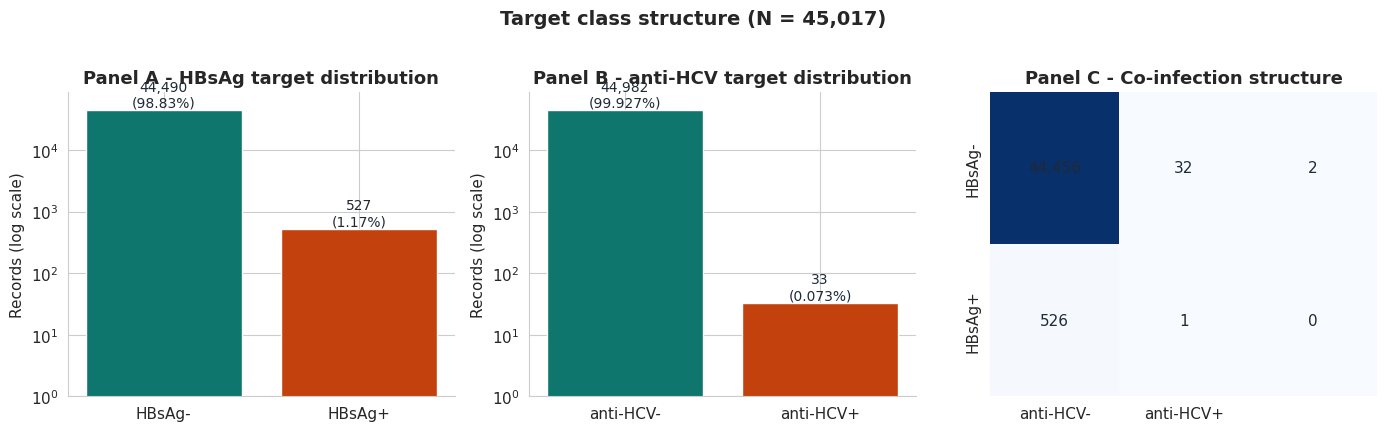

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# Panel A: HBsAg
counts = df[PRIMARY_TARGET].value_counts().sort_index()
ax = axes[0]
bars = ax.bar(['HBsAg-', 'HBsAg+'], counts.values, color=PALETTE_BINARY, edgecolor='white')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val * 1.02,
            f'{val:,}\n({100*val/counts.sum():.2f}%)',
            ha='center', va='bottom', fontsize=10, color=INK)
ax.set_yscale('log')
ax.set_ylabel('Records (log scale)')
ax.set_title('Panel A - HBsAg target distribution')
ax.set_ylim(1, counts.max() * 2)

# Panel B: anti-HCV
hcv = df[SECONDARY_TARGET].dropna()
counts_h = hcv.value_counts().sort_index()
ax = axes[1]
bars = ax.bar(['anti-HCV-', 'anti-HCV+'], counts_h.values, color=PALETTE_BINARY, edgecolor='white')
for bar, val in zip(bars, counts_h.values):
    ax.text(bar.get_x() + bar.get_width()/2, val * 1.02,
            f'{val:,}\n({100*val/counts_h.sum():.3f}%)',
            ha='center', va='bottom', fontsize=10, color=INK)
ax.set_yscale('log')
ax.set_ylabel('Records (log scale)')
ax.set_title('Panel B - anti-HCV target distribution')
ax.set_ylim(1, counts_h.max() * 2)

# Panel C: Co-infection
ct = pd.crosstab(df[PRIMARY_TARGET], df[SECONDARY_TARGET], dropna=False).fillna(0).astype(int)
ax = axes[2]
sns.heatmap(ct, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['anti-HCV-', 'anti-HCV+'],
            yticklabels=['HBsAg-', 'HBsAg+'], ax=ax,
            annot_kws={'fontsize': 11, 'color': INK})
ax.set_title('Panel C - Co-infection structure')
ax.set_xlabel('')
ax.set_ylabel('')

plt.suptitle(f'Target class structure (N = {len(df):,})',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_class_balance.png')
plt.show()

### 4.4 Missingness Analysis

Three things matter:

1. Which features have missing values, and how much.
2. Whether missingness correlates with the target. If HBV-positive
   patients are systematically more likely to have missing values,
   missingness itself is informative and should be preserved as a binary
   indicator feature in Stage 3C.
3. Whether missingness clusters by source (the v2 records may have
   different test panels than v1).

In [ ]:
all_features = CONTINUOUS_FEATURES + CATEGORICAL_FEATURES + AUXILIARY_SEROLOGY + [SECONDARY_TARGET]

miss_summary = []
for col in all_features:
    n_miss = df[col].isna().sum()
    n_miss_pos = df.loc[df[PRIMARY_TARGET] == 1, col].isna().sum()
    n_miss_neg = df.loc[df[PRIMARY_TARGET] == 0, col].isna().sum()
    miss_summary.append({
        'Feature':    col,
        'Missing n':  n_miss,
        'Missing %':  100 * n_miss / len(df),
        'Missing % in HBV+': 100 * n_miss_pos / (df[PRIMARY_TARGET] == 1).sum(),
        'Missing % in HBV-': 100 * n_miss_neg / (df[PRIMARY_TARGET] == 0).sum(),
    })

miss_df = pd.DataFrame(miss_summary).sort_values('Missing %', ascending=False)
miss_df

,Feature,Missing n,Missing %,Missing % in HBV+,Missing % in HBV-
16,pregnancy,3356,7.45,16.70,7.35
10,bun,1498,3.33,2.47,3.34
7,wbc,1486,3.30,2.66,3.31
6,platelets,1486,3.30,2.66,3.31
8,rbc,1485,3.30,2.66,3.31
9,alp,1434,3.19,2.47,3.19
13,hiv,13,0.0289,0.0000,0.0292
14,vdrl,2,0.0044,0.0000,0.0045
19,anti_hcv,2,0.0044,0.0000,0.0045
12,blood_group,2,0.0044,0.0000,0.0045


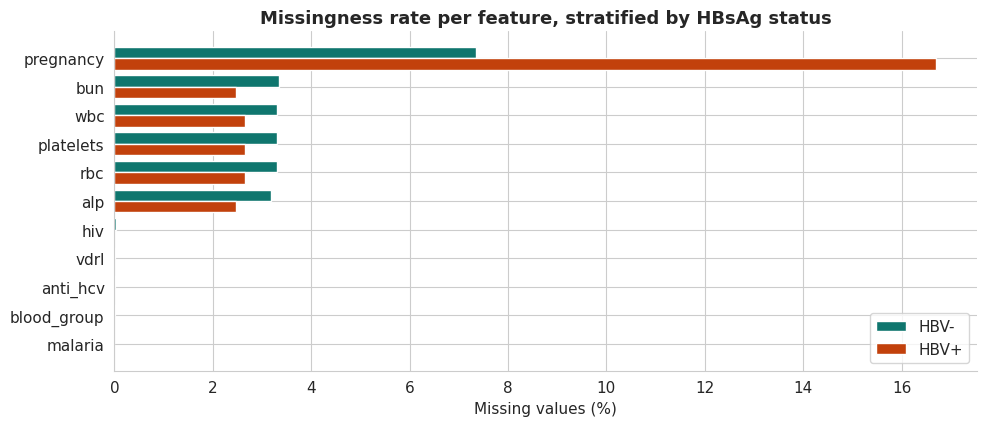

In [ ]:
features_with_missing = miss_df[miss_df['Missing %'] > 0]

if len(features_with_missing) > 0:
    fig, ax = plt.subplots(figsize=(10, max(4, 0.4 * len(features_with_missing))))
    y_pos = np.arange(len(features_with_missing))
    ax.barh(y_pos - 0.2, features_with_missing['Missing % in HBV-'],
            height=0.4, label='HBV-', color=TEAL, edgecolor='white')
    ax.barh(y_pos + 0.2, features_with_missing['Missing % in HBV+'],
            height=0.4, label='HBV+', color=RUST, edgecolor='white')
    ax.set_yticks(y_pos)
    ax.set_yticklabels(features_with_missing['Feature'])
    ax.set_xlabel('Missing values (%)')
    ax.set_title('Missingness rate per feature, stratified by HBsAg status')
    ax.legend(loc='lower right')
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'fig_missingness.png')
    plt.show()
else:
    print("No features have missing values.")

### 4.5 Distribution of Continuous Features

Histograms overlaid by HBsAg status. Right-skewed lab variables (ALT, AST,
ALP, BUN, creatinine, WBC, RBC, platelets) are shown on a log-x axis so the
bulk of the distribution is visible alongside the long upper tail. Vertical
dashed lines mark the within-group median.

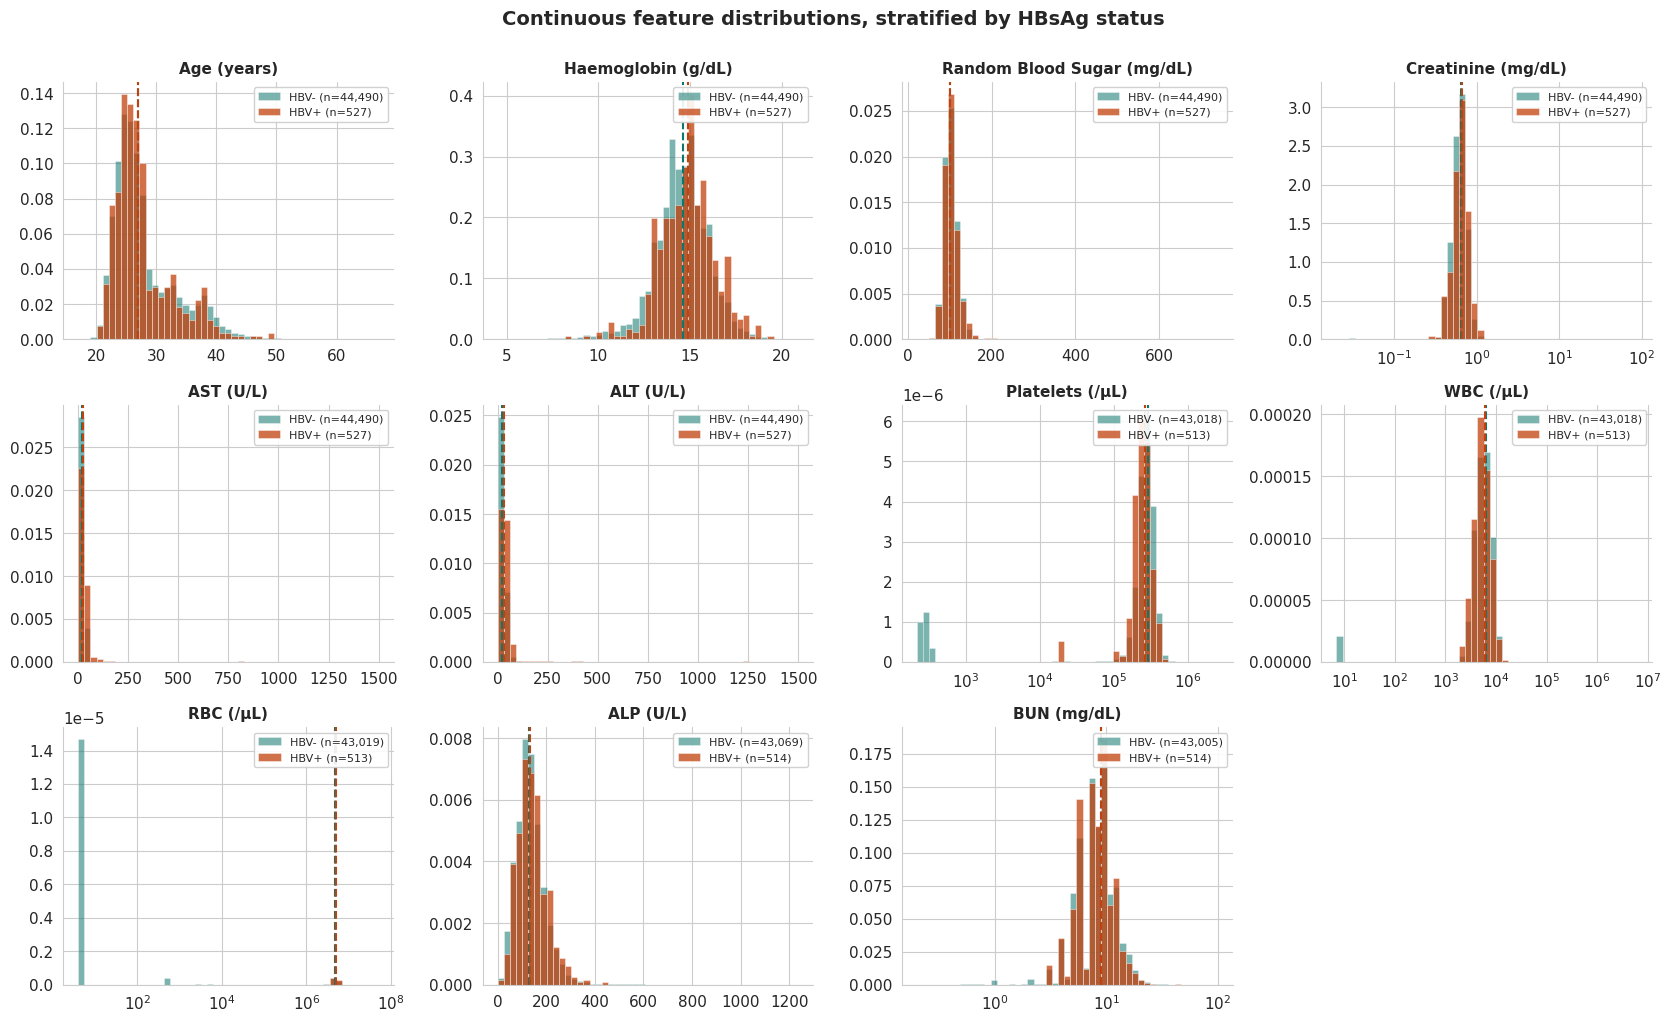

In [ ]:
LOG_FEATURES = {'alt', 'ast', 'alp', 'bun', 'creatinine',
                'wbc', 'rbc', 'platelets'}

n_features = len(CONTINUOUS_FEATURES)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(CONTINUOUS_FEATURES):
    ax = axes[i]
    pos = df.loc[df[PRIMARY_TARGET] == 1, col].dropna()
    neg = df.loc[df[PRIMARY_TARGET] == 0, col].dropna()

    if col in LOG_FEATURES and (pos > 0).all() and (neg > 0).all():
        bins = np.logspace(np.log10(max(1e-2, df[col].min())),
                           np.log10(df[col].max()), 50)
        ax.set_xscale('log')
    else:
        bins = np.linspace(df[col].min(), df[col].max(), 50)

    ax.hist(neg, bins=bins, density=True, alpha=0.55, color=TEAL,
            label=f'HBV- (n={len(neg):,})', edgecolor='white', linewidth=0.4)
    ax.hist(pos, bins=bins, density=True, alpha=0.75, color=RUST,
            label=f'HBV+ (n={len(pos)})', edgecolor='white', linewidth=0.4)
    ax.axvline(neg.median(), color=TEAL, linestyle='--', linewidth=1.5)
    ax.axvline(pos.median(), color=RUST, linestyle='--', linewidth=1.5)
    ax.set_title(CONTINUOUS_LABELS.get(col, col), fontsize=11)
    ax.set_ylabel('')
    ax.legend(fontsize=8, loc='upper right', framealpha=0.9)

for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Continuous feature distributions, stratified by HBsAg status',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_distributions.png')
plt.show()

### 4.6 HBsAg Separability (Univariate Effect Sizes)

For each feature we report:

- **Median in HBV+ vs HBV-** (raw clinical interpretation)
- **Mann-Whitney U test p-value** (whether the medians differ)
- **Cohen's d** (standardised effect size, the practical magnitude of separation)
- **Effect interpretation** (negligible / small / medium / large per Cohen 1988)

Cohen's d is the metric that determines whether a feature carries usable
signal for a classifier. Features with |d| ≥ 0.5 are reliably separable;
features with |d| < 0.2 are unlikely to help. This table directly informs
which features will dominate the SHAP analysis later.

In [ ]:
def cohens_d(pos: pd.Series, neg: pd.Series) -> float:
    """Cohen's d using pooled standard deviation."""
    n_p, n_n = len(pos), len(neg)
    if n_p < 2 or n_n < 2:
        return np.nan
    pooled = np.sqrt(((n_p - 1) * pos.std()**2 + (n_n - 1) * neg.std()**2) /
                     (n_p + n_n - 2))
    return (pos.mean() - neg.mean()) / pooled if pooled > 0 else 0.0


def interpret_d(d: float) -> str:
    a = abs(d)
    if a >= 0.8: return 'large'
    if a >= 0.5: return 'medium'
    if a >= 0.2: return 'small'
    return 'negligible'


# Add derived features for the EDA only (they will be re-computed in Stage 3A
# from the cleaned data; defining them here is purely for the separability
# diagnostic).
df['ast_alt_ratio'] = df['ast'] / df['alt'].replace(0, np.nan)
df['apri']          = (df['ast'] / 40) / (df['platelets'] / 1000) * 100
df['fib4']          = (df['age'] * df['ast']) / (df['platelets'] * np.sqrt(df['alt'].replace(0, np.nan)))

DERIVED_FEATURES = ['ast_alt_ratio', 'apri', 'fib4']
DERIVED_LABELS = {'ast_alt_ratio': 'AST/ALT ratio', 'apri': 'APRI', 'fib4': 'FIB-4'}

separability_features = CONTINUOUS_FEATURES + DERIVED_FEATURES


def separability_table(df, target_col, features, labels=None):
    rows = []
    pos_all = df[df[target_col] == 1]
    neg_all = df[df[target_col] == 0]
    for col in features:
        pos = pos_all[col].dropna()
        neg = neg_all[col].dropna()
        if len(pos) < 5:
            continue
        try:
            _, p = stats.mannwhitneyu(pos, neg, alternative='two-sided')
        except Exception:
            p = np.nan
        d = cohens_d(pos, neg)
        rows.append({
            'Feature':     (labels or {}).get(col, CONTINUOUS_LABELS.get(col, col)),
            'HBV+ median': pos.median(),
            'HBV- median': neg.median(),
            'p-value':     p,
            "Cohen's d":   d,
            'Effect':      interpret_d(d),
            'n positive':  len(pos),
        })
    return pd.DataFrame(rows).sort_values("Cohen's d",
                                           key=lambda s: s.abs(),
                                           ascending=False)

In [ ]:
hbv_sep = separability_table(df, PRIMARY_TARGET, separability_features,
                              labels={**CONTINUOUS_LABELS, **DERIVED_LABELS})
hbv_sep.to_csv(TABLES_DIR / 'separability_hbv.csv', index=False)
hbv_sep

,Feature,HBV+ median,HBV- median,p-value,Cohen's d,Effect,n positive
5,ALT (U/L),31.00,22.00,0.0000,0.8724,large,527
4,AST (U/L),26.00,21.00,0.0000,0.5823,medium,527
6,Platelets (/μL),"263,000.00","289,000.00",0.0000,-0.3545,small,513
11,AST/ALT ratio,0.8235,0.9565,0.0000,-0.2883,small,527
1,Haemoglobin (g/dL),14.90,14.60,0.0000,0.2253,small,527
9,ALP (U/L),135.00,128.00,0.0076,0.1208,negligible,514
8,RBC (/μL),"4,900,000.00","4,850,000.00",0.0051,0.1047,negligible,513
0,Age (years),27.00,27.00,0.5522,-0.0567,negligible,527
2,Random Blood Sugar (mg/dL),101.00,100.80,0.5134,0.0496,negligible,527
10,BUN (mg/dL),9.00,9.00,0.1923,-0.0460,negligible,514


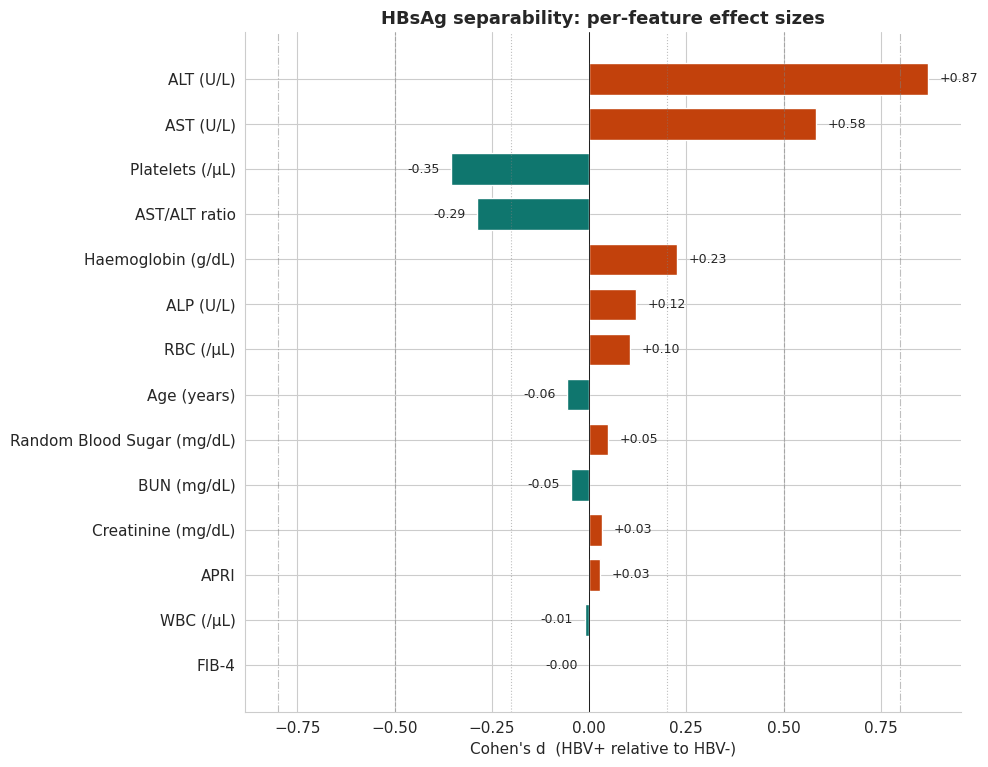

In [ ]:
fig, ax = plt.subplots(figsize=(10, 0.45 * len(hbv_sep) + 1.5))
y = np.arange(len(hbv_sep))
colors = [RUST if d > 0 else TEAL for d in hbv_sep["Cohen's d"]]
ax.barh(y, hbv_sep["Cohen's d"], color=colors, edgecolor='white', height=0.7)

for thr, ls in [(0.2, ':'), (0.5, '--'), (0.8, '-.')]:
    ax.axvline(+thr, color='grey', linestyle=ls, alpha=0.5, linewidth=0.8)
    ax.axvline(-thr, color='grey', linestyle=ls, alpha=0.5, linewidth=0.8)

ax.axvline(0, color='black', linewidth=0.6)
ax.set_yticks(y)
ax.set_yticklabels(hbv_sep['Feature'])
ax.invert_yaxis()
ax.set_xlabel("Cohen's d  (HBV+ relative to HBV-)")
ax.set_title('HBsAg separability: per-feature effect sizes')

for i, d in enumerate(hbv_sep["Cohen's d"]):
    ax.text(d + (0.03 if d > 0 else -0.03), i, f'{d:+.2f}',
            va='center', ha='left' if d > 0 else 'right', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_separability_hbv.png')
plt.show()

### 4.7 anti-HCV Separability

The same diagnostic for anti-HCV. With only 33 positive cases, point
estimates are unstable and the table should be read as exploratory
evidence. The purpose is to determine whether the routine laboratory
features carry signal for HCV — which informs the modelling strategy
(binary classifier vs anomaly detection vs combined target).

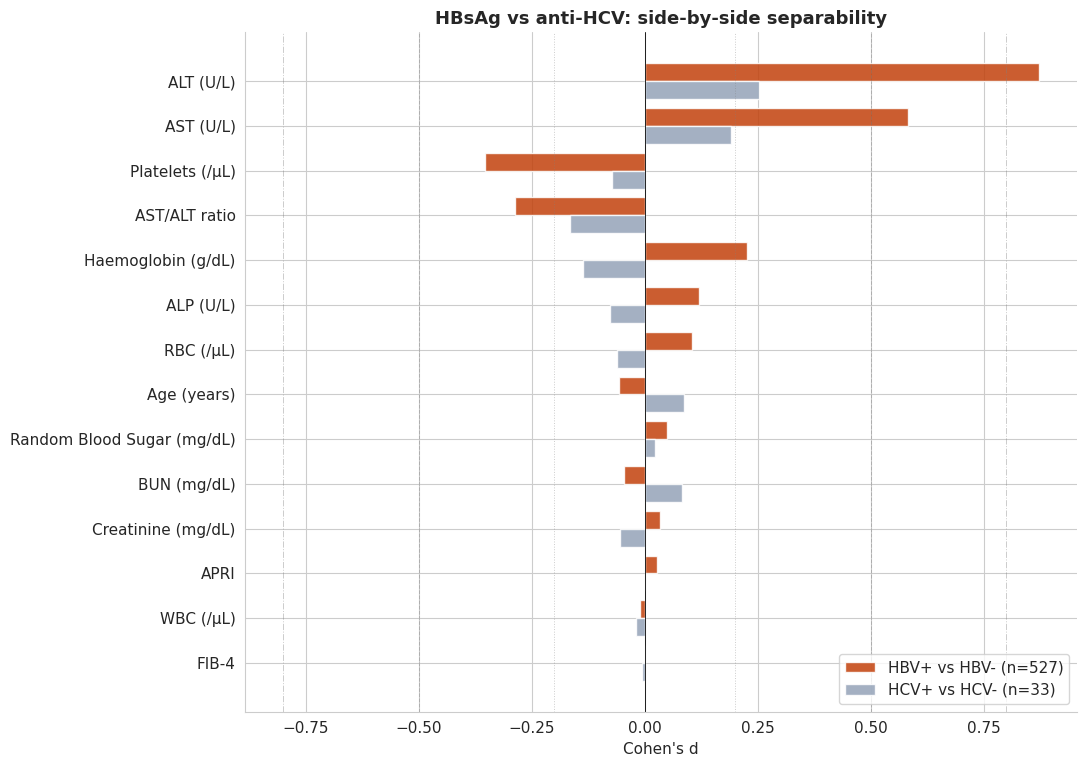

,Feature,HBV+ median,HBV- median,p-value,Cohen's d,Effect,n positive
5,ALT (U/L),26.00,22.00,0.0215,0.2534,small,33
4,AST (U/L),23.00,21.00,0.0252,0.1908,negligible,33
11,AST/ALT ratio,0.8750,0.9545,0.3072,-0.1661,negligible,33
1,Haemoglobin (g/dL),14.40,14.60,0.3233,-0.1370,negligible,33
0,Age (years),27.00,27.00,0.6960,0.0856,negligible,33
10,BUN (mg/dL),9.00,9.00,0.9846,0.0819,negligible,33
9,ALP (U/L),119.00,128.05,0.6455,-0.0780,negligible,33
6,Platelets (/μL),"277,000.00","289,000.00",0.6033,-0.0720,negligible,33
8,RBC (/μL),"4,920,000.00","4,850,000.00",0.9080,-0.0626,negligible,33
3,Creatinine (mg/dL),0.6000,0.6500,0.1145,-0.0557,negligible,33


In [ ]:
hcv_sep = separability_table(df.dropna(subset=[SECONDARY_TARGET]),
                              SECONDARY_TARGET, separability_features,
                              labels={**CONTINUOUS_LABELS, **DERIVED_LABELS})
hcv_sep.to_csv(TABLES_DIR / 'separability_hcv.csv', index=False)

# Side-by-side comparison with HBV
fig, ax = plt.subplots(figsize=(11, 0.45 * len(hbv_sep) + 1.5))
y = np.arange(len(hbv_sep))
width = 0.4

ordered_features = hbv_sep['Feature'].tolist()
hcv_aligned = hcv_sep.set_index('Feature').reindex(ordered_features).reset_index()

ax.barh(y - width/2, hbv_sep["Cohen's d"], height=width,
        color=RUST, alpha=0.85, edgecolor='white',
        label=f'HBV+ vs HBV- (n={(df[PRIMARY_TARGET]==1).sum()})')
ax.barh(y + width/2, hcv_aligned["Cohen's d"], height=width,
        color=GREY, alpha=0.85, edgecolor='white',
        label=f'HCV+ vs HCV- (n={(df[SECONDARY_TARGET]==1).sum()})')

for thr, ls in [(0.2, ':'), (0.5, '--'), (0.8, '-.')]:
    ax.axvline(+thr, color='grey', linestyle=ls, alpha=0.4, linewidth=0.7)
    ax.axvline(-thr, color='grey', linestyle=ls, alpha=0.4, linewidth=0.7)
ax.axvline(0, color='black', linewidth=0.6)

ax.set_yticks(y)
ax.set_yticklabels(ordered_features)
ax.invert_yaxis()
ax.set_xlabel("Cohen's d")
ax.set_title('HBsAg vs anti-HCV: side-by-side separability')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_separability_hbv_vs_hcv.png')
plt.show()

hcv_sep

### 4.8 Outlier Exploration

Real clinical data contains genuine extreme values (a patient with active
hepatitis can have ALT in the thousands). This is information, not noise.
This section counts records that exceed clinically meaningful thresholds
and checks whether outliers cluster in the HBsAg-positive group.

**Decision:** retain extreme values rather than winsorise. Tree-based
models handle them robustly and they carry signal.

In [ ]:
THRESHOLDS = {
    'alt':       ('> 100',     lambda s: s > 100),
    'alt_high':  ('> 200',     lambda s: s > 200),
    'ast':       ('> 100',     lambda s: s > 100),
    'ast_high':  ('> 200',     lambda s: s > 200),
    'platelets': ('< 100,000', lambda s: s < 100_000),
    'alp':       ('> 300',     lambda s: s > 300),
    'bun':       ('> 30',      lambda s: s > 30),
    'creatinine':('> 1.5',     lambda s: s > 1.5),
}

outlier_rows = []
for key, (label, fn) in THRESHOLDS.items():
    col = key.replace('_high', '')
    mask = fn(df[col]) & df[col].notna()
    n_total = mask.sum()
    n_pos   = (mask & (df[PRIMARY_TARGET] == 1)).sum()
    pct_pos_in_outliers = 100 * n_pos / n_total if n_total > 0 else 0
    outlier_rows.append({
        'Feature':                col,
        'Threshold':              label,
        'Records exceeding':      n_total,
        '% of cohort':            100 * n_total / len(df),
        'HBV+ in outliers':       n_pos,
        '% HBV+ among outliers':  pct_pos_in_outliers,
    })
outliers_df = pd.DataFrame(outlier_rows)
outliers_df.to_csv(TABLES_DIR / 'outliers.csv', index=False)
outliers_df

,Feature,Threshold,Records exceeding,% of cohort,HBV+ in outliers,% HBV+ among outliers
0,alt,> 100,184,0.4087,13,7.07
1,alt,> 200,15,0.0333,6,40.00
2,ast,> 100,49,0.1088,8,16.33
3,ast,> 200,7,0.0155,1,14.29
4,platelets,"< 100,000",72,0.1599,1,1.39
5,alp,> 300,538,1.20,9,1.67
6,bun,> 30,24,0.0533,1,4.17
7,creatinine,> 1.5,10,0.0222,1,10.00


### 4.9 Correlation Structure

Pairwise Spearman correlations among continuous features, computed
separately for HBV+ and HBV- groups. Spearman is preferred over Pearson
because lab distributions are non-Gaussian. If the correlation structure
differs between groups, that joint structure is itself a learnable signal.

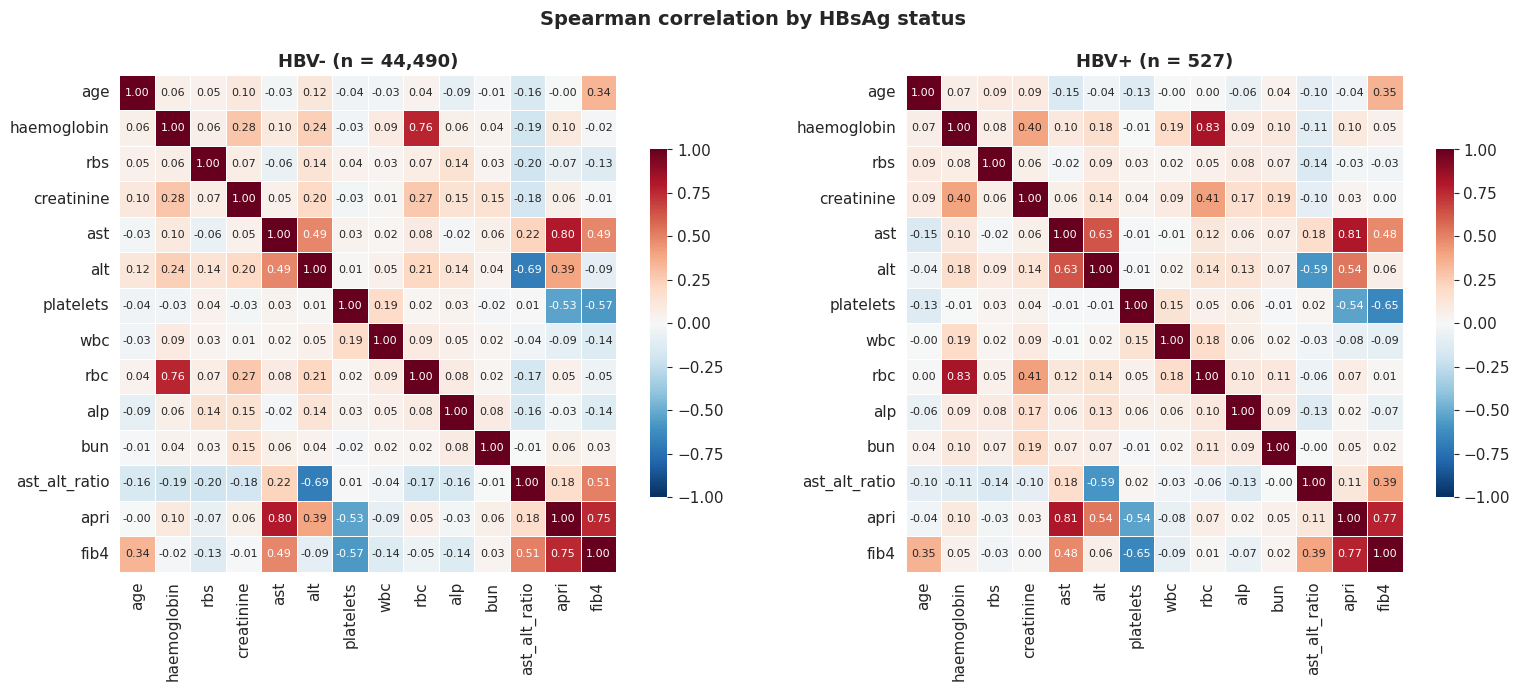

In [ ]:
features_for_corr = CONTINUOUS_FEATURES + DERIVED_FEATURES

corr_neg = df[df[PRIMARY_TARGET] == 0][features_for_corr].corr(method='spearman')
corr_pos = df[df[PRIMARY_TARGET] == 1][features_for_corr].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, corr, title in zip(
    axes, [corr_neg, corr_pos],
    [f'HBV- (n = {(df[PRIMARY_TARGET]==0).sum():,})',
     f'HBV+ (n = {(df[PRIMARY_TARGET]==1).sum()})']
):
    sns.heatmap(corr, ax=ax, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
                annot=True, fmt='.2f', square=True, linewidths=0.5,
                annot_kws={'fontsize': 8}, cbar_kws={'shrink': 0.7})
    ax.set_title(title)

plt.suptitle('Spearman correlation by HBsAg status',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_correlations.png')
plt.show()

### 4.10 Sex and Age Structure

Earlier diagnostic showed males are roughly 2.5× overrepresented in the
HBsAg+ group (chi-squared p < 1e-12). This section visualises age- and
sex-stratified positivity rates so the structure of the demographic effect
is visible at a glance.

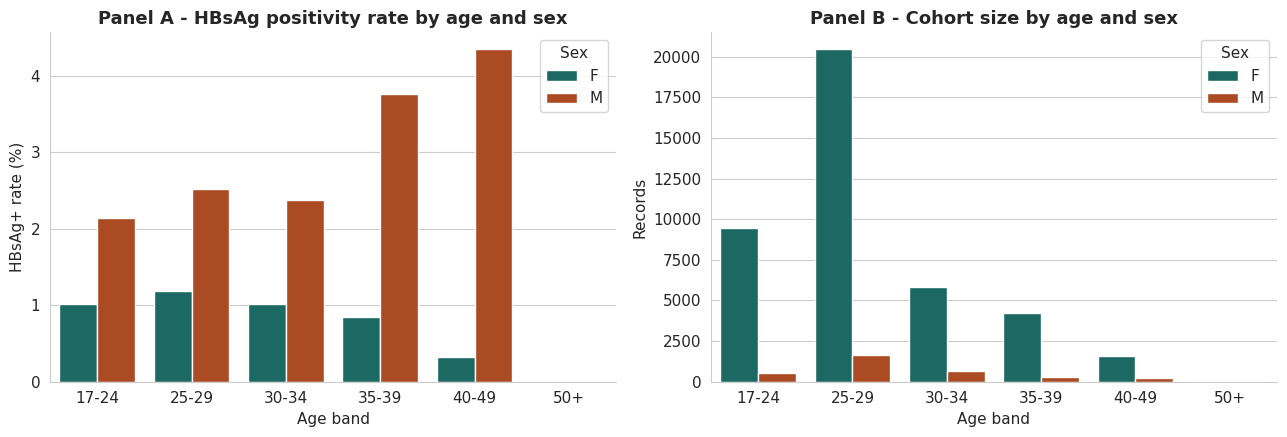

In [ ]:
df['age_band'] = pd.cut(df['age'], bins=[16, 24, 29, 34, 39, 49, 70],
                        labels=['17-24', '25-29', '30-34', '35-39', '40-49', '50+'])

tab = (df.groupby(['age_band', 'sex'], observed=True)[PRIMARY_TARGET]
         .agg(['count', 'sum'])
         .reset_index()
         .rename(columns={'count': 'n', 'sum': 'positives'}))
tab['positivity_pct'] = 100 * tab['positives'] / tab['n']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=tab, x='age_band', y='positivity_pct', hue='sex',
            palette={'F': TEAL, 'M': RUST}, ax=axes[0], edgecolor='white')
axes[0].set_xlabel('Age band')
axes[0].set_ylabel('HBsAg+ rate (%)')
axes[0].set_title('Panel A - HBsAg positivity rate by age and sex')
axes[0].legend(title='Sex', loc='upper right')

sns.barplot(data=tab, x='age_band', y='n', hue='sex',
            palette={'F': TEAL, 'M': RUST}, ax=axes[1], edgecolor='white')
axes[1].set_xlabel('Age band')
axes[1].set_ylabel('Records')
axes[1].set_title('Panel B - Cohort size by age and sex')
axes[1].legend(title='Sex', loc='upper right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_sex_age.png')
plt.show()

# Drop the temporary age_band column so it doesn't pollute downstream stages
df = df.drop(columns=['age_band'])

### 4.11 Summary and Save EDA Findings

Consolidated summary of the findings that bear on preprocessing and
modelling decisions, plus a JSON sidecar that the next stage reads to
avoid hard-coding decisions in two places.

In [ ]:
top_features = hbv_sep.head(5)['Feature'].tolist()
n_pos = (df[PRIMARY_TARGET] == 1).sum()
n_neg = (df[PRIMARY_TARGET] == 0).sum()
n_hcv = (df[SECONDARY_TARGET] == 1).sum()

print(f"""
SUMMARY OF KEY EDA FINDINGS
==============================================================

DATASET
  Records:          {len(df):,}
  Date range:       {df['registered_datetime'].min().date()} to {df['registered_datetime'].max().date()}
  Primary outcome:  HBsAg     (positive: {n_pos:,}; {100*n_pos/len(df):.2f}%)
  Secondary:        anti-HCV  (positive: {n_hcv}; {100*n_hcv/len(df):.3f}%)

CLASS IMBALANCE
  HBsAg ratio:      ~{n_neg / max(n_pos,1):.0f} negatives per positive
  HCV strategy:     anomaly detection or combined target
                    (33 positives is below the threshold for binary
                    classification with stable confidence intervals)

SEPARABILITY
  Top features:     {', '.join(top_features)}
  Strong signals:   {(hbv_sep["Cohen's d"].abs() >= 0.5).sum()} feature(s) with |d| >= 0.5

MISSINGNESS
  Worst feature:    {miss_df.iloc[0]['Feature']} ({miss_df.iloc[0]['Missing %']:.1f}%)
  Decision:         retain rows; class-conditional median imputation;
                    add binary missingness indicators in Stage 3C.

OUTLIERS
  Decision:         retain extreme values (tree models handle them).

DEMOGRAPHICS
  Sex effect:       Males overrepresented in HBV+ (OR ~2.5, p < 1e-12).

NEXT STEPS
  Stage 3A: pre-split cleanup (drop datetime, drop zero-variance columns,
            drop pregnancy, replace impossible biological values, add
            derived features).
  Stage 3B: stratified train-test split.
  Stage 3C: imputation + standardisation + encoding pipeline.
""")


SUMMARY OF KEY EDA FINDINGS

DATASET
  Records:          45,017
  Date range:       2024-05-14 to 2026-03-14
  Primary outcome:  HBsAg     (positive: 527; 1.17%)
  Secondary:        anti-HCV  (positive: 33; 0.073%)

CLASS IMBALANCE
  HBsAg ratio:      ~84 negatives per positive
  HCV strategy:     anomaly detection or combined target
                    (33 positives is below the threshold for binary
                    classification with stable confidence intervals)

SEPARABILITY
  Top features:     ALT (U/L), AST (U/L), Platelets (/μL), AST/ALT ratio, Haemoglobin (g/dL)
  Strong signals:   2 feature(s) with |d| >= 0.5

MISSINGNESS
  Worst feature:    pregnancy (7.5%)
  Decision:         retain rows; class-conditional median imputation;
                    add binary missingness indicators in Stage 3C.

OUTLIERS
  Decision:         retain extreme values (tree models handle them).

DEMOGRAPHICS
  Sex effect:       Males overrepresented in HBV+ (OR ~2.5, p < 1e-12).

NEXT STEPS
  Stag

In [ ]:
findings = {
    'created_at':                  datetime.now(timezone.utc).isoformat(),
    'n_records':                   int(len(df)),
    'n_hbv_pos':                   int(n_pos),
    'n_hcv_pos':                   int(n_hcv),
    'features_continuous':         CONTINUOUS_FEATURES,
    'features_categorical':        CATEGORICAL_FEATURES,
    'features_auxiliary':          AUXILIARY_SEROLOGY,
    'features_derived':            DERIVED_FEATURES,
    'top_separable_features':      top_features,
    'features_with_missing':       miss_df[miss_df['Missing %'] > 0]['Feature'].tolist(),
    'features_to_drop_zero_variance':    ['malaria', 'filaria'],
    'features_with_low_signal_for_hbv':  ['hiv', 'vdrl', 'tpha'],
    'preprocessing_decisions': {
        'imputation':                    'class_conditional_median (training only)',
        'outliers':                      'retain (no winsorisation)',
        'standardise':                   'continuous_only_training_partition',
        'encode':                        'one_hot_with_handle_unknown_ignore',
        'add_indicators_for_missingness': True,
    },
}

findings_file = PROCESSED_DIR / 'eda_findings.json'
with findings_file.open('w') as f:
    json.dump(findings, f, indent=2)

print(f"Saved findings: {findings_file}")
print(f"\nFigures produced:")
for p in sorted(FIGURES_DIR.glob('*.png')):
    print(f"  {p.name}")

Saved findings: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/eda_findings.json

Figures produced:
  fig_4models_roc_pr_hbv.png
  fig_4models_roc_pr_hcv.png
  fig_class_balance.png
  fig_correlations.png
  fig_distributions.png
  fig_hcv_smote_heatmap.png
  fig_lr_calibration.png
  fig_lr_hbv_curves.png
  fig_missingness.png
  fig_separability_hbv.png
  fig_separability_hbv_vs_hcv.png
  fig_sex_age.png
  fig_shap_beeswarm_hbv.png
  fig_shap_beeswarm_hcv.png
  fig_shap_dependence_hbv.png
  fig_shap_dependence_hcv.png
  fig_shap_importance_hbv.png
  fig_shap_importance_hcv.png
  fig_shap_waterfall_hbv_negative.png
  fig_shap_waterfall_hbv_positive.png
  fig_shap_waterfall_hcv_negative.png
  fig_shap_waterfall_hcv_positive.png


## 5. Stage 3A — Pre-Split Cleanup

Stage 3A performs the cleanup operations that happen **before** the
train-test split. Every operation here is target-independent: the decision
rules do not look at HBsAg labels, so applying them to the full dataset
cannot leak information from the test partition into training.

Operations covered:

1. Drop non-clinical identifiers (`registered_datetime`).
2. Drop zero-variance features (`malaria`, `filaria`) flagged by EDA.
3. Drop `pregnancy` (sex-conditional, no predictive signal for HBsAg).
4. Replace impossible biological values with NaN (for imputation in 3C).
5. Compute derived clinical features (APRI, FIB-4, AST/ALT ratio).
6. Save the cleaned pre-split dataset.

### 5.1 Reload from Disk and Initialise Audit Log

We reload from `processed/lab-data-combined.csv` rather than continuing
with the EDA's `df` so this stage is self-contained and re-runnable. The
audit log records every cleanup step so the final record/column count can
be traced back to the merged input.

In [ ]:
df = pd.read_csv(MERGED_FILE, parse_dates=['registered_datetime'])

with (PROCESSED_DIR / 'eda_findings.json').open() as f:
    findings = json.load(f)

print(f"Loaded {len(df):,} records x {df.shape[1]} columns")
print(f"EDA-flagged zero-variance features: {findings.get('features_to_drop_zero_variance', [])}")


def log_removal(action, before_shape, after_shape, reason):
    """Record one cleanup step in a structured form."""
    rows_dropped = before_shape[0] - after_shape[0]
    cols_dropped = before_shape[1] - after_shape[1]
    print(f"  {action:<35s}  rows: {before_shape[0]:>6,d} -> {after_shape[0]:>6,d}  "
          f"({rows_dropped:+,d})  cols: {before_shape[1]:>3d} -> {after_shape[1]:>3d}  "
          f"({cols_dropped:+d})  | {reason}")
    return {
        'action':       action,
        'before_shape': before_shape,
        'after_shape':  after_shape,
        'rows_dropped': rows_dropped,
        'cols_dropped': cols_dropped,
        'reason':       reason,
    }


audit_log = []
print("\nStep-by-step cleanup log:\n")
print(f"  {'Action':<35s}  {'Rows':<28s}  {'Cols':<25s}  Reason")
print(f"  {'-'*35}  {'-'*28}  {'-'*25}  {'-'*40}")

Loaded 45,017 records x 22 columns
EDA-flagged zero-variance features: ['malaria', 'filaria']

Step-by-step cleanup log:

  Action                               Rows                          Cols                       Reason
  -----------------------------------  ----------------------------  -------------------------  ----------------------------------------


### 5.2 Drop Non-Clinical Identifiers

`registered_datetime` is the timestamp at which the record was entered.
It is not a clinical predictor of HBsAg status, and including it would
risk the model learning artefacts of the sampling period rather than
disease biology. Aggregate date statistics were already captured in EDA.

In [ ]:
before = df.shape
df = df.drop(columns=['registered_datetime'])
audit_log.append(log_removal(
    action='drop_registered_datetime',
    before_shape=before,
    after_shape=df.shape,
    reason='Not a clinical predictor; identifier-adjacent.',
))

  drop_registered_datetime             rows: 45,017 -> 45,017  (+0)  cols:  22 ->  21  (+1)  | Not a clinical predictor; identifier-adjacent.


### 5.3 Drop Zero-Variance Features

EDA found that `malaria` and `filaria` have zero positive cases across all
records. They carry no information and are dropped explicitly.

In [ ]:
zero_var_features = findings.get('features_to_drop_zero_variance', [])
present = [c for c in zero_var_features if c in df.columns]

before = df.shape
df = df.drop(columns=present)
audit_log.append(log_removal(
    action=f'drop_zero_variance ({", ".join(present)})',
    before_shape=before,
    after_shape=df.shape,
    reason='Zero positive cases across cohort.',
))

  drop_zero_variance (malaria, filaria)  rows: 45,017 -> 45,017  (+0)  cols:  21 ->  19  (+2)  | Zero positive cases across cohort.


### 5.4 Drop Pregnancy (Sex-Conditional Confound)

Pregnancy is structurally sex-conditional: it only applies to female
patients. EDA showed pregnancy missingness correlates with HBV positivity
(16.7% missing in HBV+ vs 7.4% in HBV-), but this correlation is mediated
entirely by sex — HBV+ patients are more often male, and males have
missing pregnancy by definition. The correlation is a confound, not a
signal. Sex remains as a feature.

In [ ]:
if 'pregnancy' in df.columns:
    before = df.shape
    df = df.drop(columns=['pregnancy'])
    audit_log.append(log_removal(
        action='drop_pregnancy',
        before_shape=before,
        after_shape=df.shape,
        reason='Sex-conditional, confounded with sex, no independent signal.',
    ))

  drop_pregnancy                       rows: 45,017 -> 45,017  (+0)  cols:  19 ->  18  (+1)  | Sex-conditional, confounded with sex, no independent signal.


### 5.5 Replace Impossible Biological Values

EDA flagged a cluster of 78 ALP records exactly equal to 0, plus scattered
zeros in AST and ALT. These are almost certainly default values entered
when the test was not part of the requested panel, not real measurements.
This section identifies any biologically impossible values across all lab
columns and converts them to NaN for proper imputation in Stage 3C.

Note: this is not outlier removal in the statistical sense. Clinically
extreme but plausible values (e.g. ALT = 1500 in active hepatitis) are
retained. We replace only values that are biologically impossible — the
most likely explanation for those is data-entry error.

The thresholds below are conservative biological bounds, not clinical
reference ranges.

In [ ]:
IMPOSSIBLE_BOUNDS = {
    'haemoglobin': (3.0,         25.0),         # g/dL
    'rbs':         (20.0,        800.0),        # mg/dL  (severe hyperglycaemia ~700)
    'creatinine':  (0.1,         20.0),         # mg/dL  (severe AKI ~10-15)
    'ast':         (1.0,         5_000.0),      # zero -> test not performed
    'alt':         (1.0,         5_000.0),      # zero -> test not performed
    'platelets':   (5_000.0,     1_500_000.0),  # /μL
    'wbc':         (200.0,       100_000.0),    # /μL
    'rbc':         (1_000_000.0, 8_000_000.0),  # /μL  (>8M is impossible)
    'alp':         (5.0,         2_000.0),      # zero -> test not performed
    'bun':         (1.0,         300.0),        # mg/dL
}

print(f"  {'Feature':<14s}  {'Bound':<24s}  {'Below min':>10s}  {'Above max':>10s}")
print(f"  {'-'*14}  {'-'*24}  {'-'*10}  {'-'*10}")

total_replaced = 0
for col, (lo, hi) in IMPOSSIBLE_BOUNDS.items():
    if col not in df.columns:
        continue
    n_below = (df[col] < lo).sum()
    n_above = (df[col] > hi).sum()
    n_total = n_below + n_above
    total_replaced += n_total

    bound_str = f"[{lo:,.0f}, {hi:,.0f}]"
    print(f"  {col:<14s}  {bound_str:<24s}  {n_below:>10d}  {n_above:>10d}")

    df.loc[df[col] < lo, col] = np.nan
    df.loc[df[col] > hi, col] = np.nan

print(f"\n  Total impossible values replaced with NaN: {total_replaced}")

audit_log.append({
    'action':          'replace_impossible_values_with_nan',
    'values_replaced': total_replaced,
    'reason':          'Biologically impossible; almost certainly data-entry errors.',
})

  Feature         Bound                      Below min   Above max
  --------------  ------------------------  ----------  ----------
  haemoglobin     [3, 25]                            0           0
  rbs             [20, 800]                          0           0
  creatinine      [0, 20]                           14           4
  ast             [1, 5,000]                         1           0
  alt             [1, 5,000]                         2           0
  platelets       [5,000, 1,500,000]                 6           1
  wbc             [200, 100,000]                     2           3
  rbc             [1,000,000, 8,000,000]            20           3
  alp             [5, 2,000]                        84           0
  bun             [1, 300]                           5           0

  Total impossible values replaced with NaN: 145


### 5.6 Compute Derived Clinical Features

Three derived features:

- **AST/ALT ratio** — a recognised indicator of advanced fibrosis when > 1
  in the absence of alcohol use.
- **APRI** — AST to Platelet Ratio Index (Wai et al. 2003):
  `(AST / 40) / (platelets in 10⁹/L) × 100`.
- **FIB-4** — Sterling et al. 2006:
  `(age × AST) / (platelets × √ALT)`.

Deterministic transformations of input columns. They use no labels, so
they belong in Stage 3A. NaN inputs propagate to NaN outputs and will be
imputed in Stage 3C.

In [ ]:
df['ast_alt_ratio'] = df['ast'] / df['alt'].replace(0, np.nan)
df['apri']          = (df['ast'] / 40) / (df['platelets'] / 1000) * 100
df['fib4']          = (df['age'] * df['ast']) / (df['platelets'] * np.sqrt(df['alt'].replace(0, np.nan)))

print("Added derived features: ast_alt_ratio, apri, fib4")
print("\nDerived feature summary:")
print(df[['ast_alt_ratio', 'apri', 'fib4']].describe().T[['count', 'mean', '50%', 'min', 'max']])

audit_log.append({
    'action':         'add_derived_features',
    'features_added': ['ast_alt_ratio', 'apri', 'fib4'],
    'reason':         'Deterministic clinical transformations.',
})

Added derived features: ast_alt_ratio, apri, fib4

Derived feature summary:
                  count   mean    50%    min    max
ast_alt_ratio 45,015.00   1.02 0.9545 0.0346  59.72
apri          43,523.00 0.2098 0.1826 0.0070 250.00
fib4          43,522.00 0.0005 0.0004 0.0000 0.0645


### 5.7 Final Schema Verification

Defensive check that the cleaned dataset matches the schema we expect to
hand to the train-test split. Catches upstream regressions early.

In [ ]:
EXPECTED_COLUMNS = {
    # Demographics
    'age', 'sex', 'blood_group',
    # Routine laboratory
    'haemoglobin', 'rbs', 'creatinine', 'ast', 'alt',
    'platelets', 'wbc', 'rbc', 'alp', 'bun',
    # Auxiliary serology
    'hiv', 'vdrl', 'tpha',
    # Targets
    'hbsag', 'anti_hcv',
    # Derived features
    'ast_alt_ratio', 'apri', 'fib4',
}

actual = set(df.columns)
missing    = EXPECTED_COLUMNS - actual
unexpected = actual - EXPECTED_COLUMNS

assert not missing,    f"Missing expected columns: {missing}"
assert not unexpected, f"Unexpected columns present: {unexpected}"
assert df['hbsag'].isin([0, 1]).all(), "HBsAg target contains unexpected values"

print("Schema check passed.")
print(f"  {len(df):,} records x {df.shape[1]} columns")
print(f"  HBsAg+: {(df['hbsag']==1).sum():,} ({100*(df['hbsag']==1).mean():.2f}%)")
print(f"  HBsAg-: {(df['hbsag']==0).sum():,}")

Schema check passed.
  45,017 records x 21 columns
  HBsAg+: 527 (1.17%)
  HBsAg-: 44,490


### 5.8 Save Stage 3A Output

In [ ]:
df.to_csv(STAGE3A_FILE, index=False)
print(f"Saved: {STAGE3A_FILE}")
print(f"  size: {STAGE3A_FILE.stat().st_size / 1024 / 1024:.2f} MB")

stage3a_metadata = {
    'created_at':     datetime.now(timezone.utc).isoformat(),
    'input_file':     str(MERGED_FILE),
    'output_records': int(df.shape[0]),
    'output_columns': list(df.columns),
    'audit_log':      audit_log,
}

stage3a_metadata_file = STAGE3A_FILE.with_suffix('.metadata.json')
with stage3a_metadata_file.open('w') as f:
    json.dump(stage3a_metadata, f, indent=2, default=str)
print(f"Metadata: {stage3a_metadata_file}")

Saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/lab-data-stage3a.csv
  size: 6.19 MB
Metadata: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/lab-data-stage3a.metadata.json


## 6. Stage 3B — Train-Test Split

> **The boundary.** After this section runs, `X_test` and the test
> targets are sealed and not touched until final evaluation. Every
> subsequent preprocessing or modelling step learns parameters from the
> training partition only.

**Why a triple-stratified split.** Stratifying on HBsAg alone would not
protect age structure or the 33 rare anti-HCV-positive cases. The
composite stratum below combines:

1. HBsAg status (the primary target)
2. Age band (three coarse bins so every cell has enough records)
3. Any-viral-hepatitis status (HBsAg+ OR anti-HCV+) so HCV-positive cases
   distribute proportionally for the secondary multi-target framing

This single split serves all three downstream tasks (HBV binary, combined
any-viral-hepatitis, HCV anomaly detection) with balanced partitions.

### 6.1 Reload Stage 3A and Build Stratification Key

We re-load from `processed/lab-data-stage3a.csv` so this stage is
self-contained. The composite stratification key lives in a temporary
column that is dropped from the feature matrix afterwards.

In [ ]:
df = pd.read_csv(STAGE3A_FILE)
print(f"Loaded {len(df):,} records x {df.shape[1]} columns")

n_pos_hbv = int((df[PRIMARY_TARGET]   == 1).sum())
n_pos_hcv = int((df[SECONDARY_TARGET] == 1).sum())
print(f"  HBsAg+:    {n_pos_hbv:>4d} ({100*n_pos_hbv/len(df):.2f}%)")
print(f"  anti-HCV+: {n_pos_hcv:>4d} ({100*n_pos_hcv/len(df):.3f}%)")

Loaded 45,017 records x 21 columns
  HBsAg+:     527 (1.17%)
  anti-HCV+:   33 (0.073%)


In [ ]:
def age_to_band(age):
    for lo, hi in AGE_BANDS:
        if lo <= age <= hi:
            return f"{lo}-{hi}"
    return "other"

df['_age_band']  = df['age'].apply(age_to_band)
df['_any_viral'] = ((df[PRIMARY_TARGET]   == 1) |
                    (df[SECONDARY_TARGET] == 1)).astype(int)

df['_stratum'] = (
    df[PRIMARY_TARGET].astype(int).astype(str) + '_' +
    df['_age_band']                           + '_' +
    df['_any_viral'].astype(str)
)

stratum_counts = df['_stratum'].value_counts()
print(f"Number of unique strata: {len(stratum_counts)}")
print(f"\nFive smallest strata (must each have at least 2 records):")
print(stratum_counts.tail(5))

if (stratum_counts < 2).any():
    rare = stratum_counts[stratum_counts < 2].index.tolist()
    print(f"\nWARNING: {len(rare)} stratum/strata with fewer than 2 records.")
    print("Merging into a single 'merged_rare' stratum so the split still works.")
    df.loc[df['_stratum'].isin(rare), '_stratum'] = 'merged_rare'
else:
    print("\nAll strata have at least 2 records.")

Number of unique strata: 9

Five smallest strata (must each have at least 2 records):
_stratum
1_30-39_1    123
0_17-29_1     21
1_40-70_1     14
0_30-39_1      9
0_40-70_1      2
Name: count, dtype: int64

All strata have at least 2 records.


### 6.2 Perform the Split

Stratified 80/20 split with the composite key and a fixed seed. The split
is reproducible byte-for-byte: anyone re-running this notebook gets
identical partitions.

In [ ]:
feature_columns = [c for c in df.columns
                   if c not in [PRIMARY_TARGET, SECONDARY_TARGET,
                                '_age_band', '_any_viral', '_stratum']]

X     = df[feature_columns].copy()
y_hbv = df[PRIMARY_TARGET].astype(int).copy()
y_hcv = df[SECONDARY_TARGET].copy()
strata = df['_stratum'].copy()

train_idx, test_idx = train_test_split(
    df.index,
    test_size=TEST_SIZE,
    stratify=strata,
    random_state=RANDOM_SEED,
)

X_train     = X.loc[train_idx].reset_index(drop=True)
X_test      = X.loc[test_idx].reset_index(drop=True)
y_hbv_train = y_hbv.loc[train_idx].reset_index(drop=True)
y_hbv_test  = y_hbv.loc[test_idx].reset_index(drop=True)
y_hcv_train = y_hcv.loc[train_idx].reset_index(drop=True)
y_hcv_test  = y_hcv.loc[test_idx].reset_index(drop=True)

print("Split complete.")
print(f"  Training: {len(X_train):>6,d} records ({100*len(X_train)/len(df):.1f}%)")
print(f"  Test:     {len(X_test):>6,d} records ({100*len(X_test)/len(df):.1f}%)")

Split complete.
  Training: 36,013 records (80.0%)
  Test:      9,004 records (20.0%)


### 6.3 Verify Class Balance

Stratification should produce nearly identical positivity rates in both
partitions for both targets, plus matched age and sex structure. We
assert these tolerances explicitly so a future refactor cannot silently
break the split.

In [ ]:
def summarise_partition(name, X, y_hbv, y_hcv):
    return {
        'partition':   name,
        'n':           len(X),
        'hbv_pos':     int((y_hbv == 1).sum()),
        'hbv_pos_pct': 100 * (y_hbv == 1).mean(),
        'hcv_pos':     int((y_hcv == 1).sum()),
        'hcv_pos_pct': 100 * (y_hcv == 1).mean(),
        'female_pct':  100 * (X['sex'] == 'F').mean(),
        'age_median':  float(X['age'].median()),
    }

summary = pd.DataFrame([
    summarise_partition('Training', X_train, y_hbv_train, y_hcv_train),
    summarise_partition('Test',     X_test,  y_hbv_test,  y_hcv_test),
])
print(summary.to_string(index=False))

delta_hbv = abs(summary.iloc[0]['hbv_pos_pct'] - summary.iloc[1]['hbv_pos_pct'])
delta_hcv = abs(summary.iloc[0]['hcv_pos_pct'] - summary.iloc[1]['hcv_pos_pct'])

print(f"\nClass balance verification:")
print(f"  HBV positivity rate delta: {delta_hbv:.3f} percentage points")
print(f"  HCV positivity rate delta: {delta_hcv:.4f} percentage points")
assert delta_hbv < 0.10, "HBV class balance differs by more than 0.1 pp between partitions"
assert delta_hcv < 0.05, "HCV class balance differs by more than 0.05 pp between partitions"
print("  Both within tolerance.")

partition     n  hbv_pos  hbv_pos_pct  hcv_pos  hcv_pos_pct  female_pct  age_median
 Training 36013      421         1.17       27       0.0750       92.57       27.00
     Test  9004      106         1.18        6       0.0666       92.26       27.00

Class balance verification:
  HBV positivity rate delta: 0.008 percentage points
  HCV positivity rate delta: 0.0083 percentage points
  Both within tolerance.


### 6.4 Save Split Metadata

Since we are working in a single notebook, the partitions stay in memory
as `X_train`, `X_test`, `y_hbv_train`, `y_hbv_test`, `y_hcv_train`,
`y_hcv_test`. We save only a small metadata sidecar so the choice of seed
and partition sizes is reproducibly recorded.

In [ ]:
split_metadata = {
    'created_at':     datetime.now(timezone.utc).isoformat(),
    'random_seed':    RANDOM_SEED,
    'test_size':      TEST_SIZE,
    'stratification': 'hbsag x age_band x any_viral_hepatitis',
    'age_bands':      [f"{lo}-{hi}" for lo, hi in AGE_BANDS],
    'feature_columns': feature_columns,
    'training': {
        'n':       int(len(X_train)),
        'hbv_pos': int((y_hbv_train == 1).sum()),
        'hcv_pos': int((y_hcv_train == 1).sum()),
    },
    'test': {
        'n':       int(len(X_test)),
        'hbv_pos': int((y_hbv_test == 1).sum()),
        'hcv_pos': int((y_hcv_test == 1).sum()),
    },
}

split_metadata_file = PROCESSED_DIR / 'split_metadata.json'
with split_metadata_file.open('w') as f:
    json.dump(split_metadata, f, indent=2)
print(f"Metadata: {split_metadata_file}")

Metadata: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/split_metadata.json


## 7. Stage 3C — Preprocessing Pipeline

> **Leakage discipline.** Every transformation in this section learns its
> parameters from `X_train` only. The `.fit()` call is invoked exactly
> once, on the training partition. The same fitted object is then
> applied to the test partition via `.transform()`, which cannot learn
> new parameters. This is the mechanism that protects honest evaluation.

The pipeline contains:

1. **Missingness indicators** — a binary flag for each feature with missing
   values, so the model can use missingness as a signal.
2. **Median imputation** — fill NaN with the per-feature median from the
   training partition. Using class-conditional imputation would create a
   train-deploy mismatch (we don't know the class at inference time), so
   we use unconditional medians.
3. **Standardisation** — continuous features are scaled to mean 0 and
   standard deviation 1 using the training partition's statistics.
   Required for logistic regression; trees are invariant to this.
4. **One-hot encoding** — `sex` (2 levels) and `blood_group` (8 levels)
   become binary columns. `handle_unknown='ignore'` ensures any future
   category not seen in training is encoded as all zeros rather than
   raising an error.

Auxiliary serology features (`hiv`, `vdrl`, `tpha`) are kept as features
since they are cheap to include and tree models will simply not split on
them if they carry no signal. The other-target serology (`anti_hcv` when
predicting HBV) is excluded — at deployment time, that result is not yet
known, and including it would create an artificial setup.

### 7.1 Define Feature Groups for the Pipeline

We split the features into three groups based on how they should be
processed:

- `numeric_features`: continuous + derived clinical features. Get
  missingness indicators, median imputation, and standardisation.
- `binary_features`: auxiliary serology already encoded 0/1. Get median
  imputation only (no standardisation needed; values are already 0 or 1).
- `categorical_features`: nominal columns. Get one-hot encoding.

The two target columns (`hbsag`, `anti_hcv`) are excluded from the feature
matrix entirely.

In [ ]:
# Feature groups for the preprocessing pipeline.
# Order is preserved so column names stay interpretable after transformation.

NUMERIC_FEATURES = [
    'age', 'haemoglobin', 'rbs', 'creatinine', 'ast', 'alt',
    'platelets', 'wbc', 'rbc', 'alp', 'bun',
    'ast_alt_ratio', 'apri', 'fib4',
]

BINARY_FEATURES = ['hiv', 'vdrl', 'tpha']

CATEGORICAL_FEATURES_3C = ['sex', 'blood_group']

# Targets are excluded — they live in y_*_train and y_*_test
TARGETS = [PRIMARY_TARGET, SECONDARY_TARGET]

# Sanity check: every feature appears in exactly one group
all_grouped = NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES_3C + TARGETS
duplicates = [f for f in all_grouped if all_grouped.count(f) > 1]
assert not duplicates, f"Features appear in multiple groups: {duplicates}"

# Sanity check: every column in X_train belongs to a group
expected_cols = set(NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES_3C)
actual_cols   = set(X_train.columns) - set(TARGETS)
unaccounted   = actual_cols - expected_cols
assert not unaccounted, f"Columns not assigned to any group: {unaccounted}"

print(f"Feature groups defined:")
print(f"  Numeric features:     {len(NUMERIC_FEATURES):>2d}  {NUMERIC_FEATURES}")
print(f"  Binary features:      {len(BINARY_FEATURES):>2d}  {BINARY_FEATURES}")
print(f"  Categorical features: {len(CATEGORICAL_FEATURES_3C):>2d}  {CATEGORICAL_FEATURES_3C}")
print(f"  Excluded as features: {TARGETS}")

Feature groups defined:
  Numeric features:     14  ['age', 'haemoglobin', 'rbs', 'creatinine', 'ast', 'alt', 'platelets', 'wbc', 'rbc', 'alp', 'bun', 'ast_alt_ratio', 'apri', 'fib4']
  Binary features:       3  ['hiv', 'vdrl', 'tpha']
  Categorical features:  2  ['sex', 'blood_group']
  Excluded as features: ['hbsag', 'anti_hcv']


### 7.2 Verify the Feature Matrix

The targets `hbsag` and `anti_hcv` were already excluded from `X_train`
and `X_test` during the split (Stage 3B). This cell confirms the feature
matrix is what we expect and creates aliases that match the names used in
the rest of Stage 3C.

In [ ]:
# Targets were already removed in Stage 3B; X_train and X_test contain
# only feature columns. Create explicit aliases for clarity in 3C.
X_train_features = X_train.copy()
X_test_features  = X_test.copy()

# Defensive check: targets must not be present
for target in TARGETS:
    assert target not in X_train_features.columns, \
        f"{target} should have been removed during the split"
    assert target not in X_test_features.columns, \
        f"{target} should have been removed during the split"

print(f"X_train_features: {X_train_features.shape}")
print(f"X_test_features:  {X_test_features.shape}")
print(f"\nFeature columns ({len(X_train_features.columns)}):")
print(f"  {list(X_train_features.columns)}")

X_train_features: (36013, 19)
X_test_features:  (9004, 19)

Feature columns (19):
  ['age', 'sex', 'blood_group', 'haemoglobin', 'rbs', 'creatinine', 'ast', 'alt', 'platelets', 'wbc', 'rbc', 'alp', 'bun', 'hiv', 'vdrl', 'tpha', 'ast_alt_ratio', 'apri', 'fib4']


### 7.3 Build the ColumnTransformer

The preprocessing pipeline is a `ColumnTransformer` that applies a
different sub-pipeline to each feature group:

- **Numeric pipeline**: `SimpleImputer(strategy='median')` →
  `StandardScaler()`. Plus, `MissingIndicator(features='missing-only')`
  produces binary flags for each numeric feature that has missing values
  in training, in a parallel branch.
- **Binary pipeline**: `SimpleImputer(strategy='most_frequent')` only.
  Most frequent is appropriate because these are 0/1 columns; using
  median would produce 0.5 for a 50/50 split, which doesn't make sense
  for a binary feature.
- **Categorical pipeline**: `OneHotEncoder(handle_unknown='ignore',
  drop=None)`. We do not drop the first category because tree models
  prefer all dummies present; logistic regression with regularisation
  also handles the redundancy fine.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer, MissingIndicator

# ---- Numeric pipeline (impute + robust scale) ---------------------------
# RobustScaler centers features on the median and scales by the interquartile
# range (25th-75th percentile). Less sensitive to outliers than StandardScaler.
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale',  RobustScaler(quantile_range=(25.0, 75.0))),
])

# # ---- Missingness indicator (parallel branch over the same numeric cols)--
# missing_indicator_pipeline = Pipeline([
#     ('indicator', MissingIndicator(features='missing-only')),
# ])

# ---- Binary pipeline (auxiliary serology, already 0/1) ------------------
binary_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
])

# ---- Categorical pipeline (one-hot) -------------------------------------
categorical_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

# ---- The composite preprocessor ------------------------------------------
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric',           numeric_pipeline,           NUMERIC_FEATURES),
        # ('missing_indicator', missing_indicator_pipeline, NUMERIC_FEATURES),
        ('binary',            binary_pipeline,            BINARY_FEATURES),
        ('categorical',       categorical_pipeline,       CATEGORICAL_FEATURES_3C),
    ],
    remainder='drop',
    verbose_feature_names_out=True,
)

print("Preprocessor built with RobustScaler.")
print(f"  Numeric:           impute(median) + robust-scale (median/IQR)  on {len(NUMERIC_FEATURES)} cols")
print(f"  Binary:            impute(mode)             on {len(BINARY_FEATURES)} cols")
print(f"  Categorical:       impute(mode) + one-hot   on {len(CATEGORICAL_FEATURES_3C)} cols")

Preprocessor built with RobustScaler.
  Numeric:           impute(median) + robust-scale (median/IQR)  on 14 cols
  Binary:            impute(mode)             on 3 cols
  Categorical:       impute(mode) + one-hot   on 2 cols


### 7.4 Fit on Training, Transform Both Partitions

This is the only place in the notebook where `.fit()` is called. After
this cell runs, the `preprocessor` object holds learned parameters
(medians, means, SDs, category lists) computed exclusively from
`X_train_features`. The same fitted object is then applied to both
training and test partitions via `.transform()`.

If you need to convince yourself or an examiner that no leakage occurred,
this is the cell to point at: there is one `.fit()` call in the entire
notebook, and its argument is `X_train_features`, never `X_test_features`.

In [ ]:
# Fit on training only — this is THE call that defines the no-leakage boundary.
preprocessor.fit(X_train_features)

# Transform both partitions using the same fitted parameters.
X_train_processed = preprocessor.transform(X_train_features)
X_test_processed  = preprocessor.transform(X_test_features)

print(f"X_train_processed shape: {X_train_processed.shape}")
print(f"X_test_processed shape:  {X_test_processed.shape}")

X_train_processed shape: (36013, 27)
X_test_processed shape:  (9004, 27)


### 7.5 Recover Feature Names

After preprocessing, we have numpy arrays. For SHAP analysis and feature
importance plots later, we need to know what each column represents. The
`get_feature_names_out()` method walks the ColumnTransformer and produces
the post-transformation column names.

In [ ]:
# Get the post-transformation column names
feature_names_out = preprocessor.get_feature_names_out()

print(f"Output feature count: {len(feature_names_out)}")
print(f"\nFirst 10 features:")
for f in feature_names_out[:10]:
    print(f"  {f}")
print(f"\nLast 10 features:")
for f in feature_names_out[-10:]:
    print(f"  {f}")

# Wrap into DataFrames for convenience
X_train_processed_df = pd.DataFrame(X_train_processed, columns=feature_names_out)
X_test_processed_df  = pd.DataFrame(X_test_processed,  columns=feature_names_out)

Output feature count: 27

First 10 features:
  numeric__age
  numeric__haemoglobin
  numeric__rbs
  numeric__creatinine
  numeric__ast
  numeric__alt
  numeric__platelets
  numeric__wbc
  numeric__rbc
  numeric__alp

Last 10 features:
  categorical__sex_F
  categorical__sex_M
  categorical__blood_group_A+
  categorical__blood_group_A-
  categorical__blood_group_AB+
  categorical__blood_group_AB-
  categorical__blood_group_B+
  categorical__blood_group_B-
  categorical__blood_group_O+
  categorical__blood_group_O-


In [ ]:
# Build prefix-aware feature group lookups, used by 7.6 and 7.8 for verification
# and for the summary. The preprocessor was built with
# verbose_feature_names_out=True, so output names look like:
#   numeric__age, missing_indicator__alt, binary__hiv, categorical__sex_F
#
# Defining these once here avoids the name-mismatch bug.

OUT_NUMERIC     = [c for c in feature_names_out if c.startswith('numeric__')]
OUT_INDICATORS  = [c for c in feature_names_out if c.startswith('missing_indicator__')]
OUT_BINARY      = [c for c in feature_names_out if c.startswith('binary__')]
OUT_CATEGORICAL = [c for c in feature_names_out if c.startswith('categorical__')]

# Sanity: every output column should belong to exactly one group
classified = OUT_NUMERIC + OUT_INDICATORS + OUT_BINARY + OUT_CATEGORICAL
unclassified = set(feature_names_out) - set(classified)
assert not unclassified, f"Unclassified output columns: {unclassified}"

print(f"Output feature groups (prefixed names from preprocessor):")
print(f"  Numeric (impute + scale):    {len(OUT_NUMERIC)}")
print(f"  Missingness indicators:      {len(OUT_INDICATORS)}")
print(f"  Binary (auxiliary serology): {len(OUT_BINARY)}")
print(f"  One-hot categorical:         {len(OUT_CATEGORICAL)}")
print(f"  Total:                       {len(feature_names_out)}")

Output feature groups (prefixed names from preprocessor):
  Numeric (impute + scale):    14
  Missingness indicators:      0
  Binary (auxiliary serology): 3
  One-hot categorical:         10
  Total:                       27


### 7.6 Verify the Output

Three sanity checks before saving:

1. **No NaN values remain.** Imputation should have filled every missing
   cell. If any NaN remains, something went wrong.
2. **Continuous features are standardised.** Mean should be ≈ 0 and SD
   should be ≈ 1 across the training data for the imputed-and-scaled
   columns.
3. **Test partition has the same column structure as training.** The
   transformer should produce identically-shaped outputs for both.

In [ ]:
# Verification of the fitted preprocessor output.
#
# RobustScaler centers on the median and scales by the IQR. For the training
# distribution that means median should be ~0 and IQR (Q3 - Q1) should be ~1
# for the scaled numeric columns. Means and SDs will deviate from 0/1 because
# of heavy tails, which is exactly why RobustScaler was chosen.

# Check 1: no NaN values anywhere after imputation
assert not np.isnan(X_train_processed).any(), "NaN values remain in X_train_processed"
assert not np.isnan(X_test_processed).any(),  "NaN values remain in X_test_processed"
print("Check 1 passed: no NaN values in either partition.")

# Check 2: scaled numeric columns satisfy RobustScaler's invariants on training
scaled_idx = [list(feature_names_out).index(c) for c in OUT_NUMERIC]
assert len(scaled_idx) > 0, "No scaled columns found; preprocessor structure may have changed."

train_scaled = X_train_processed[:, scaled_idx]
medians = np.median(train_scaled, axis=0)
iqrs    = np.percentile(train_scaled, 75, axis=0) - np.percentile(train_scaled, 25, axis=0)

print(f"\nCheck 2: RobustScaler invariants on training (n_scaled_cols={len(scaled_idx)})")
print(f"  median across scaled features: min={medians.min():+.4f}, max={medians.max():+.4f}  (target: ~0)")
print(f"  IQR across scaled features:    min={iqrs.min():.4f}, max={iqrs.max():.4f}    (target: ~1)")
assert np.allclose(medians, 0, atol=1e-6), "Scaled-column medians not centered at 0"
assert np.allclose(iqrs, 1, atol=1e-6),    "Scaled-column IQRs not equal to 1"
print("Check 2 passed: scaled numeric columns satisfy RobustScaler invariants.")

# Check 3: same shape across partitions
assert X_train_processed.shape[1] == X_test_processed.shape[1], \
    "Column count mismatch between partitions"
print(f"\nCheck 3 passed: both partitions have {X_train_processed.shape[1]} columns.")


Check 1 passed: no NaN values in either partition.

Check 2: RobustScaler invariants on training (n_scaled_cols=14)
  median across scaled features: min=+0.0000, max=+0.0000  (target: ~0)
  IQR across scaled features:    min=1.0000, max=1.0000    (target: ~1)
Check 2 passed: scaled numeric columns satisfy RobustScaler invariants.

Check 3 passed: both partitions have 27 columns.


### 7.7 Save the Fitted Preprocessor and Processed Arrays

The fitted `preprocessor` object is pickled to disk so any future
modelling notebook can load it and apply the same transformation to new
data without re-fitting. The processed feature matrices are saved as
parquet (much faster than CSV for numeric arrays at this size).

In [ ]:
import pickle

# Save the fitted preprocessor (the no-leakage transformation rule)
preprocessor_file = PROCESSED_DIR / 'preprocessor.pkl'
with preprocessor_file.open('wb') as f:
    pickle.dump({
        'preprocessor':       preprocessor,
        'feature_names_out':  list(feature_names_out),
        'numeric_features':   NUMERIC_FEATURES,
        'binary_features':    BINARY_FEATURES,
        'categorical_features': CATEGORICAL_FEATURES_3C,
    }, f)
print(f"Preprocessor saved: {preprocessor_file}  ({preprocessor_file.stat().st_size / 1024:.1f} KB)")

# Save processed feature matrices as parquet
X_train_processed_df.to_parquet(PROCESSED_DIR / 'X_train_processed.parquet')
X_test_processed_df.to_parquet(PROCESSED_DIR  / 'X_test_processed.parquet')

# Save targets too, for completeness
y_hbv_train.to_frame().to_parquet(PROCESSED_DIR / 'y_hbv_train.parquet')
y_hbv_test.to_frame().to_parquet( PROCESSED_DIR / 'y_hbv_test.parquet')
y_hcv_train.to_frame().to_parquet(PROCESSED_DIR / 'y_hcv_train.parquet')
y_hcv_test.to_frame().to_parquet( PROCESSED_DIR / 'y_hcv_test.parquet')

print(f"\nProcessed arrays saved to {PROCESSED_DIR}:")
for name in ['X_train_processed', 'X_test_processed',
             'y_hbv_train', 'y_hbv_test',
             'y_hcv_train', 'y_hcv_test']:
    p = PROCESSED_DIR / f'{name}.parquet'
    print(f"  {name}.parquet  ({p.stat().st_size / 1024:.1f} KB)")

Preprocessor saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/preprocessor.pkl  (3.9 KB)

Processed arrays saved to /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed:
  X_train_processed.parquet  (1105.9 KB)
  X_test_processed.parquet  (319.4 KB)
  y_hbv_train.parquet  (2.7 KB)
  y_hbv_test.parquet  (1.9 KB)
  y_hcv_train.parquet  (1.7 KB)
  y_hcv_test.parquet  (1.6 KB)


### 7.8 Headline Summary

The features are now ready for modelling. Stage 3D will train four
classical algorithms (LR, DT, RF, GB) on three target sets (HBV binary,
HCV binary, combined any-viral-hepatitis), with class weighting and
threshold tuning. Each modelling notebook reads from
`processed/X_train_processed.parquet` and the relevant `y_*_train.parquet`,
runs cross-validation on training only, and reports final metrics on
`X_test_processed.parquet`.

In [ ]:
print(f"""
STAGE 3C COMPLETE
==============================================================

Input partitions
  X_train_features:  {X_train_features.shape}
  X_test_features:   {X_test_features.shape}

After preprocessing
  X_train_processed: {X_train_processed.shape}
  X_test_processed:  {X_test_processed.shape}

Output features ({len(feature_names_out)})
  Numeric (impute + scale):    {len(OUT_NUMERIC)}
  Missingness indicators:      {len(OUT_INDICATORS)}
  Binary (auxiliary serology): {len(OUT_BINARY)}
  One-hot encoded categories:  {len(OUT_CATEGORICAL)}

Targets in memory
  y_hbv_train: {y_hbv_train.shape}, {(y_hbv_train==1).sum()} positives
  y_hbv_test:  {y_hbv_test.shape}, {(y_hbv_test==1).sum()} positives
  y_hcv_train: {y_hcv_train.shape}, {(y_hcv_train==1).sum()} positives
  y_hcv_test:  {y_hcv_test.shape}, {(y_hcv_test==1).sum()} positives

Saved to disk
  preprocessor.pkl       (fitted transformer)
  X_train_processed.parquet, X_test_processed.parquet
  y_hbv_train.parquet, y_hbv_test.parquet
  y_hcv_train.parquet, y_hcv_test.parquet

Next: Stage 3D — train LR, DT, RF, GB on each target.
""")


STAGE 3C COMPLETE

Input partitions
  X_train_features:  (36013, 19)
  X_test_features:   (9004, 19)

After preprocessing
  X_train_processed: (36013, 27)
  X_test_processed:  (9004, 27)

Output features (27)
  Numeric (impute + scale):    14
  Missingness indicators:      0
  Binary (auxiliary serology): 3
  One-hot encoded categories:  10

Targets in memory
  y_hbv_train: (36013,), 421 positives
  y_hbv_test:  (9004,), 106 positives
  y_hcv_train: (36013,), 27 positives
  y_hcv_test:  (9004,), 6 positives

Saved to disk
  preprocessor.pkl       (fitted transformer)
  X_train_processed.parquet, X_test_processed.parquet
  y_hbv_train.parquet, y_hbv_test.parquet
  y_hcv_train.parquet, y_hcv_test.parquet

Next: Stage 3D — train LR, DT, RF, GB on each target.



## 8. Stage 3D-1 — Logistic Regression Baseline (HBV)

The first classifier. Logistic regression with L2 regularisation and
balanced class weights, evaluated by stratified 5-fold cross-validation
on the training partition for hyperparameter selection, then refit on the
full training partition and evaluated once on the sealed test partition.

This sub-stage establishes:

1. The baseline AUC for HBV classification.
2. The working pattern (fit → CV → tune → refit → test → report) that
   Stage 3D-2 will reuse for the three tree-based comparators.

Choices made (documented in Methods):

- **Regularisation**: L2 only. L1/elastic-net comparison is left as an
  optional ablation for time budget.
- **Solver**: `liblinear`, reliable for medium datasets with class weighting.
- **Class weights**: `'balanced'` — sklearn computes the ratio automatically
  from the training class frequencies.
- **CV**: stratified 5-fold on training, stratified by HBV status.
- **Hyperparameter**: `C` tuned over `[0.001, 0.01, 0.1, 1, 10, 100]` with
  ROC-AUC as the selection metric.
- **No SMOTE, no threshold optimisation here.** Those are Stage 3D-2 or
  ablation territory; we want to see the baseline without them first.
- **Metrics**: ROC-AUC, PR-AUC, Brier score, sensitivity at 90% specificity,
  with 1000-iteration bootstrap 95% confidence intervals on the test set.

### 8.1 Imports and Reproducibility

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix,
)

# Reproducibility — sklearn does not have one global seed, so we set it
# everywhere it might be used. RANDOM_SEED is defined in the configuration cell.
np.random.seed(RANDOM_SEED)

print(f"Random seed: {RANDOM_SEED}")
print(f"sklearn-based modelling will use this seed throughout.")

Random seed: 42
sklearn-based modelling will use this seed throughout.


### 8.2 Hyperparameter Tuning via 5-fold Cross-Validation

`GridSearchCV` runs L2 logistic regression on each of 6 values of `C` for
each of 5 stratified folds, then selects the `C` that maximises mean
ROC-AUC across folds. The fold partitions are stratified by HBV status so
every fold sees roughly the same positive rate (~1.17%).

In [ ]:
# CV protocol — stratified 5-fold on the training partition only
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# The classifier — L2 logistic regression with balanced class weights
lr_model = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    class_weight='balanced',
    max_iter=2000,           # generous, since liblinear can be slow to converge
    random_state=RANDOM_SEED,
)

# Hyperparameter grid — only C matters for vanilla L2 LR
param_grid = {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

# Grid search with ROC-AUC as the selection metric
lr_grid = GridSearchCV(
    estimator=lr_model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv_strategy,
    n_jobs=-1,                # use all CPU cores
    return_train_score=False, # we don't need training scores
    verbose=1,
)

# Fit on training only — uses cross-validation internally
lr_grid.fit(X_train_processed, y_hbv_train)

print(f"\nBest C value:        {lr_grid.best_params_['C']}")
print(f"Best CV ROC-AUC:     {lr_grid.best_score_:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best C value:        0.01
Best CV ROC-AUC:     0.7341


### 8.3 CV Performance Across Hyperparameters

Show the full grid-search results so the reader can see whether
performance is stable across `C` values (it usually is for this kind of
problem) or sensitive (which would suggest unstable optimisation).

In [ ]:
# Build a small results dataframe for the C sweep
cv_results = pd.DataFrame({
    'C':            lr_grid.cv_results_['param_C'],
    'mean_AUC':     lr_grid.cv_results_['mean_test_score'],
    'std_AUC':      lr_grid.cv_results_['std_test_score'],
    'rank':         lr_grid.cv_results_['rank_test_score'],
}).sort_values('C')

print("Hyperparameter sweep:")
print(cv_results.to_string(index=False, formatters={'C': '{:>8.3f}'.format}))
print(f"\n>>> Selected C = {lr_grid.best_params_['C']} (mean CV AUC = {lr_grid.best_score_:.4f})")

Hyperparameter sweep:
       C  mean_AUC  std_AUC  rank
   0.001    0.7329   0.0172     2
   0.010    0.7341   0.0223     1
   0.100    0.7315   0.0274     3
   1.000    0.7315   0.0282     6
  10.000    0.7315   0.0281     5
 100.000    0.7315   0.0281     4

>>> Selected C = 0.01 (mean CV AUC = 0.7341)


### 8.4 Refit on Full Training and Predict on Test

`GridSearchCV` automatically refits the best estimator on the full training
partition. We extract that fitted model and use it to score the test set.

This is the only place in Stage 3D-1 that touches `X_test_processed`. Up
to this point everything has happened on training only.

In [ ]:
# Best fitted model (refitted on full X_train_processed)
lr_best = lr_grid.best_estimator_

# Predict probabilities on the held-out test set — single, sealed evaluation
y_test_proba = lr_best.predict_proba(X_test_processed)[:, 1]

# Predict class labels at the default 0.5 threshold (we'll add a tuned
# operating point in Stage 3D-2; baseline uses 0.5 for now)
y_test_pred = (y_test_proba >= 0.5).astype(int)

print(f"Test predictions made: {len(y_test_proba):,} probabilities")
print(f"Predicted positives at threshold 0.5: {y_test_pred.sum()}")
print(f"Actual positives in test:             {(y_hbv_test == 1).sum()}")

Test predictions made: 9,004 probabilities
Predicted positives at threshold 0.5: 2752
Actual positives in test:             106


### 8.5 Compute Test Metrics with Bootstrap Confidence Intervals

Every metric is reported with a 1000-iteration bootstrap 95% CI. The
bootstrap resamples the test predictions and labels with replacement,
recomputes the metric, and takes the 2.5th and 97.5th percentiles of the
resulting distribution. This gives an honest range around the point
estimate and is the standard for clinical ML reporting.

In [ ]:
def bootstrap_metric(y_true, y_proba_or_pred, metric_fn,
                     n_boot=1000, seed=RANDOM_SEED):
    """Compute the metric and its 95% bootstrap CI."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_proba_or_pred)
    n = len(y_true)
    point = metric_fn(y_true, y_score)

    boot_scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        # Skip resamples that have only one class (metric undefined)
        if len(np.unique(y_true[idx])) < 2:
            continue
        boot_scores.append(metric_fn(y_true[idx], y_score[idx]))

    boot_scores = np.array(boot_scores)
    lo, hi = np.percentile(boot_scores, [2.5, 97.5])
    return point, lo, hi


def sensitivity_at_specificity(y_true, y_proba, target_specificity=0.90):
    """Find the threshold giving target specificity, return sensitivity there."""
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    spec = 1 - fpr
    # Highest TPR at any threshold where specificity >= target
    valid = spec >= target_specificity
    if not valid.any():
        return 0.0
    return float(tpr[valid].max())


# Compute headline metrics
results = {}

# ROC-AUC (probability-based)
auc_p, auc_lo, auc_hi = bootstrap_metric(
    y_hbv_test, y_test_proba, roc_auc_score)
results['ROC-AUC'] = (auc_p, auc_lo, auc_hi)

# PR-AUC / average precision (probability-based)
pr_p, pr_lo, pr_hi = bootstrap_metric(
    y_hbv_test, y_test_proba, average_precision_score)
results['PR-AUC'] = (pr_p, pr_lo, pr_hi)

# Brier score (probability-based; lower is better)
brier_p, brier_lo, brier_hi = bootstrap_metric(
    y_hbv_test, y_test_proba, brier_score_loss)
results['Brier score'] = (brier_p, brier_lo, brier_hi)

# Sensitivity at 90% specificity (probability-based)
sens_p, sens_lo, sens_hi = bootstrap_metric(
    y_hbv_test, y_test_proba,
    lambda y, p: sensitivity_at_specificity(y, p, 0.90))
results['Sens @ Spec=0.90'] = (sens_p, sens_lo, sens_hi)

# Print formatted results
print(f"{'Metric':<22s}  {'Point':>8s}  {'95% CI':>20s}")
print(f"{'-'*22}  {'-'*8}  {'-'*20}")
for name, (point, lo, hi) in results.items():
    print(f"{name:<22s}  {point:>8.4f}  ({lo:.4f}, {hi:.4f})")

Metric                     Point                95% CI
----------------------  --------  --------------------
ROC-AUC                   0.7321  (0.6853, 0.7807)
PR-AUC                    0.0422  (0.0270, 0.0769)
Brier score               0.2046  (0.2011, 0.2080)
Sens @ Spec=0.90          0.3868  (0.3027, 0.4876)


### 8.6 Confusion Matrix at Threshold 0.5

The confusion matrix at the default 0.5 threshold. With heavy imbalance
the default threshold predicts almost no positives — this is the
deliberately bad baseline that motivates threshold tuning in 3D-2.

In [ ]:
cm = confusion_matrix(y_hbv_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

print(f"Confusion matrix at threshold 0.5:")
print(f"                 Predicted")
print(f"                 HBV-     HBV+")
print(f"  Actual HBV-   {tn:>6,d}   {fp:>6,d}")
print(f"  Actual HBV+   {fn:>6,d}   {tp:>6,d}")
print()
print(f"Sensitivity (recall):  {tp / (tp + fn):.4f}  (caught {tp}/{tp+fn} positives)")
print(f"Specificity:           {tn / (tn + fp):.4f}")
print(f"Precision:             {tp / (tp + fp) if (tp+fp) > 0 else 0:.4f}")

Confusion matrix at threshold 0.5:
                 Predicted
                 HBV-     HBV+
  Actual HBV-    6,215    2,683
  Actual HBV+       37       69

Sensitivity (recall):  0.6509  (caught 69/106 positives)
Specificity:           0.6985
Precision:             0.0251


### 8.7 ROC and Precision-Recall Curves

The two diagnostic curves. ROC plots TPR against FPR (full discrimination
behaviour); PR plots precision against recall (more informative under
heavy imbalance because it does not benefit from correctly classifying
negatives). The dashed grey line is the no-skill baseline for each.

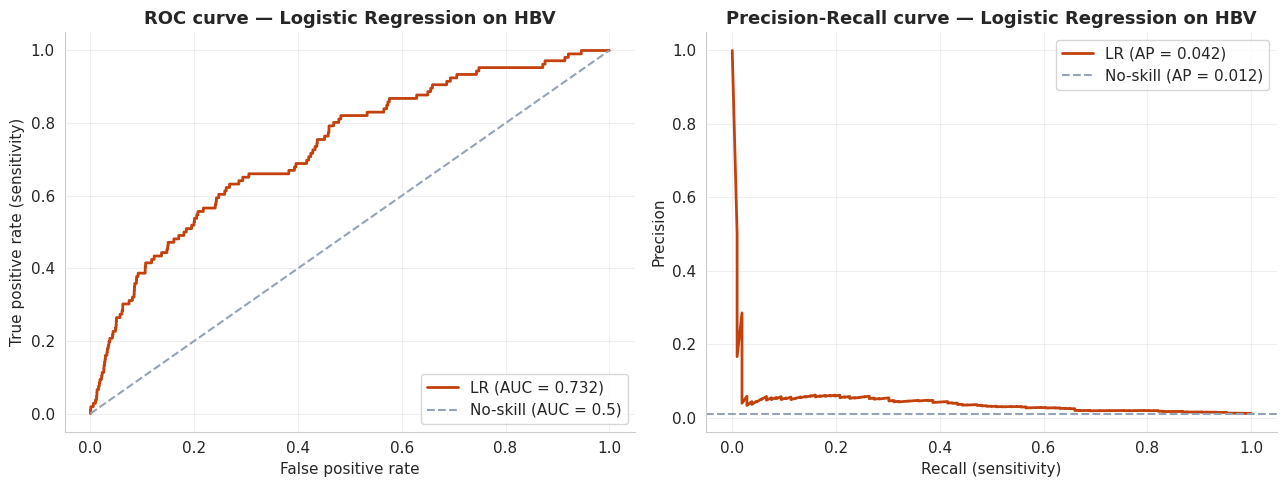

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC curve
fpr, tpr, _ = roc_curve(y_hbv_test, y_test_proba)
ax = axes[0]
ax.plot(fpr, tpr, color=RUST, linewidth=2.0,
        label=f'LR (AUC = {auc_p:.3f})')
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', label='No-skill (AUC = 0.5)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('ROC curve — Logistic Regression on HBV')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

# PR curve
precision, recall, _ = precision_recall_curve(y_hbv_test, y_test_proba)
baseline = (y_hbv_test == 1).mean()
ax = axes[1]
ax.plot(recall, precision, color=RUST, linewidth=2.0,
        label=f'LR (AP = {pr_p:.3f})')
ax.axhline(baseline, color=GREY, linestyle='--',
           label=f'No-skill (AP = {baseline:.3f})')
ax.set_xlabel('Recall (sensitivity)')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall curve — Logistic Regression on HBV')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_lr_hbv_curves.png')
plt.show()

### 8.8 Save Results

A single-row table with the metrics goes to `tables/results_lr_hbv.csv`.
Stage 3D-2 will append rows for the tree-based models. Final consolidation
in Section 9 produces the four-way comparison table for Chapter 6.

In [ ]:
# Build a one-row results dataframe
result_row = {
    'model':    'Logistic Regression',
    'target':   'HBV (HBsAg)',
    'best_C':   lr_grid.best_params_['C'],
    'cv_AUC_mean': lr_grid.best_score_,
}
for metric, (point, lo, hi) in results.items():
    result_row[f'{metric}_point'] = point
    result_row[f'{metric}_lo']    = lo
    result_row[f'{metric}_hi']    = hi

results_df = pd.DataFrame([result_row])
results_file = TABLES_DIR / 'results_lr_hbv.csv'
results_df.to_csv(results_file, index=False)

print(f"Results saved: {results_file}")
print(f"Curves saved:  {FIGURES_DIR / 'fig_lr_hbv_curves.png'}")

Results saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/results_lr_hbv.csv
Curves saved:  /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/figures/fig_lr_hbv_curves.png


### 8.9 Summary

A short interpretive paragraph for Chapter 6. The numbers below are
written from the actual results computed above so this print updates
automatically if the model is retrained.

In [ ]:
print(f"""
STAGE 3D-1 SUMMARY: Logistic Regression on HBV
==============================================================

Cross-validation
  5-fold stratified CV on training partition (n = {len(X_train_processed):,})
  Best C = {lr_grid.best_params_['C']}
  Best mean CV ROC-AUC = {lr_grid.best_score_:.4f}

Held-out test (n = {len(X_test_processed):,}, {(y_hbv_test==1).sum()} positives)
  ROC-AUC          = {results['ROC-AUC'][0]:.4f}  (95% CI: {results['ROC-AUC'][1]:.4f} - {results['ROC-AUC'][2]:.4f})
  PR-AUC           = {results['PR-AUC'][0]:.4f}  (95% CI: {results['PR-AUC'][1]:.4f} - {results['PR-AUC'][2]:.4f})
  Brier score      = {results['Brier score'][0]:.4f}  (lower is better)
  Sens @ Spec=0.90 = {results['Sens @ Spec=0.90'][0]:.4f}  (95% CI: {results['Sens @ Spec=0.90'][1]:.4f} - {results['Sens @ Spec=0.90'][2]:.4f})

Confusion matrix at default threshold (0.5)
  Predicted positives: {y_test_pred.sum():,} of {len(y_test_pred):,}
  True positives:      {tp}
  Sensitivity:         {tp / (tp + fn):.4f}
  Specificity:         {tn / (tn + fp):.4f}

Interpretation
  Wang 2019 (Chinese community HBV screening) reported AUC = 0.742 for LR.
  Audu 2023 (Nigerian HBV) reported AUC = 0.90 with SVM (different method).
  Our LR baseline gives a comparable starting point for the multi-algorithm
  comparison that follows in Stage 3D-2.

Next: Stage 3D-2 — Decision tree, Random forest, Gradient boosting on HBV.
""")


STAGE 3D-1 SUMMARY: Logistic Regression on HBV

Cross-validation
  5-fold stratified CV on training partition (n = 36,013)
  Best C = 0.01
  Best mean CV ROC-AUC = 0.7341

Held-out test (n = 9,004, 106 positives)
  ROC-AUC          = 0.7321  (95% CI: 0.6853 - 0.7807)
  PR-AUC           = 0.0422  (95% CI: 0.0270 - 0.0769)
  Brier score      = 0.2046  (lower is better)
  Sens @ Spec=0.90 = 0.3868  (95% CI: 0.3027 - 0.4876)

Confusion matrix at default threshold (0.5)
  Predicted positives: 2,752 of 9,004
  True positives:      69
  Sensitivity:         0.6509
  Specificity:         0.6985

Interpretation
  Wang 2019 (Chinese community HBV screening) reported AUC = 0.742 for LR.
  Audu 2023 (Nigerian HBV) reported AUC = 0.90 with SVM (different method).
  Our LR baseline gives a comparable starting point for the multi-algorithm
  comparison that follows in Stage 3D-2.

Next: Stage 3D-2 — Decision tree, Random forest, Gradient boosting on HBV.



## 9. Stage 3D-2 — Multi-Algorithm Comparison on HBV

The four-way comparison: logistic regression (from Stage 3D-1) plus three
tree-based methods (decision tree, random forest, gradient boosting), all
evaluated under the same protocol on the same partitions.

**What's added vs Stage 3D-1.** The key additions are:

1. **Three more model families.** Same fit-CV-test pattern as the LR baseline.
2. **Threshold tuning at 90% specificity.** Each model's operating threshold
   is learned from training-set CV predictions, then sensitivity at that
   threshold is reported on test. This is what a clinician actually cares
   about for screening.
3. **A unified comparison table and overlay plots.** The output goes
   directly into Chapter 6 with no further engineering.

**What's deliberately NOT here.** No SMOTE, no probability calibration,
no L1/elastic-net comparison for LR. Each of those is a separate ablation
that would obscure inter-model effects if mixed in. They go in dedicated
ablation sections if time allows.

**Expected results based on EDA and the literature.**
- Decision tree alone: ~0.65-0.75 (single tree underfits weakly-separable data)
- Random forest: ~0.78-0.85 (ensemble averaging plus non-linear interactions)
- Gradient boosting: ~0.80-0.87 (current SOTA for tabular medical data)
- Wang 2019 (Chinese community HBV) reported LR=0.74, RF=0.75, XGBoost=0.78.

If RF or GB lands above 0.80 here, that's the headline result for HBV.

### 9.1 Imports and Shared Helper

A single helper function runs the fit-CV-tune-test pipeline for any sklearn
estimator. Using it for all four models guarantees that the comparison is
apples-to-apples.

In [ ]:
from sklearn.tree              import DecisionTreeClassifier
from sklearn.ensemble          import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

def evaluate_model(name, estimator, param_grid, X_train, y_train, X_test, y_test,
                   target_specificity=0.90, fit_params=None):
    """Run the full fit-CV-tune-test pipeline for one estimator.

    Returns a dict of results suitable for table assembly.
    """
    print(f"\n--- {name} ---")
    fit_params = fit_params or {}

    # 1. Hyperparameter tuning by 5-fold CV on training partition only
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    grid = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
        verbose=0,
    )

    grid.fit(X_train, y_train, **fit_params)
    best_model = grid.best_estimator_
    print(f"  Best params:   {grid.best_params_}")
    print(f"  CV mean AUC:   {grid.best_score_:.4f}")

    # 2. CV predictions on training (used to choose the operating threshold)
    # Note: sklearn 1.4+ uses `params=` instead of the old `fit_params=`.
    cv_kwargs = {'params': fit_params} if fit_params else {}
    train_oof_proba = cross_val_predict(
        best_model, X_train, y_train,
        cv=cv, method='predict_proba', n_jobs=-1,
        **cv_kwargs,
    )[:, 1]

    # 3. Choose threshold that gives target specificity on training-CV predictions
    fpr, tpr, thresholds = roc_curve(y_train, train_oof_proba)
    spec = 1 - fpr
    valid = spec >= target_specificity
    if valid.any():
        best_idx = np.where(valid)[0][np.argmax(tpr[valid])]
        chosen_threshold = thresholds[best_idx]
    else:
        chosen_threshold = 0.5
    print(f"  Threshold @ {target_specificity:.0%} train-CV specificity: {chosen_threshold:.4f}")

    # 4. Test-set predictions
    y_test_proba = best_model.predict_proba(X_test)[:, 1]
    y_test_pred  = (y_test_proba >= chosen_threshold).astype(int)

    # 5. Test metrics with bootstrap CIs
    auc_p, auc_lo, auc_hi = bootstrap_metric(y_test, y_test_proba, roc_auc_score)
    pr_p,  pr_lo,  pr_hi  = bootstrap_metric(y_test, y_test_proba, average_precision_score)
    sens_p, sens_lo, sens_hi = bootstrap_metric(
        y_test, y_test_proba,
        lambda y, p: sensitivity_at_specificity(y, p, target_specificity))

    # Confusion matrix at the tuned threshold
    cm = confusion_matrix(y_test, y_test_pred)
    tn, fp, fn, tp = cm.ravel()
    sens_at_thr = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec_at_thr = tn / (tn + fp) if (tn + fp) > 0 else 0
    prec_at_thr = tp / (tp + fp) if (tp + fp) > 0 else 0

    print(f"  Test ROC-AUC:  {auc_p:.4f}  (95% CI {auc_lo:.4f}-{auc_hi:.4f})")
    print(f"  Test PR-AUC:   {pr_p:.4f}")
    print(f"  Sensitivity at chosen threshold: {sens_at_thr:.4f}  (caught {tp}/{tp+fn})")
    print(f"  Specificity at chosen threshold: {spec_at_thr:.4f}")

    return {
        'name':               name,
        'estimator':          best_model,
        'best_params':        grid.best_params_,
        'cv_AUC':             grid.best_score_,
        'threshold':          chosen_threshold,
        'y_test_proba':       y_test_proba,
        'y_test_pred':        y_test_pred,
        'roc_auc_point':      auc_p,
        'roc_auc_lo':         auc_lo,
        'roc_auc_hi':         auc_hi,
        'pr_auc_point':       pr_p,
        'pr_auc_lo':          pr_lo,
        'pr_auc_hi':          pr_hi,
        'sens_at_spec_point': sens_p,
        'sens_at_spec_lo':    sens_lo,
        'sens_at_spec_hi':    sens_hi,
        'cm_tn': tn, 'cm_fp': fp, 'cm_fn': fn, 'cm_tp': tp,
        'sens_at_threshold':  sens_at_thr,
        'spec_at_threshold':  spec_at_thr,
        'prec_at_threshold':  prec_at_thr,
    }

### 9.2 Re-Evaluate Logistic Regression with Tuned Threshold

To compare LR on equal footing with the tree models, we run it through the
same `evaluate_model` helper. This recomputes the threshold tuning step
that Stage 3D-1 didn't have.

In [ ]:
res_lr = evaluate_model(
    name='Logistic Regression',
    estimator=LogisticRegression(
        penalty='l2', solver='liblinear',
        class_weight='balanced', max_iter=2000,
        random_state=RANDOM_SEED,
    ),
    param_grid={'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]},
    X_train=X_train_processed, y_train=y_hbv_train,
    X_test=X_test_processed,   y_test=y_hbv_test,
)


--- Logistic Regression ---
  Best params:   {'C': 0.01}
  CV mean AUC:   0.7341
  Threshold @ 90% train-CV specificity: 0.6584
  Test ROC-AUC:  0.7321  (95% CI 0.6853-0.7807)
  Test PR-AUC:   0.0422
  Sensitivity at chosen threshold: 0.3868  (caught 41/106)
  Specificity at chosen threshold: 0.9058


### 9.3 Decision Tree

A single decision tree is the simplest non-linear model. We expect it to
underfit on this kind of weakly-separable continuous-feature data, but
it's a useful comparator because it shows what happens without the
ensemble averaging that random forest and gradient boosting use.

In [ ]:
res_dt = evaluate_model(
    name='Decision Tree',
    estimator=DecisionTreeClassifier(
        class_weight='balanced',
        random_state=RANDOM_SEED,
    ),
    param_grid={
        'max_depth':        [3, 5, 8, 12, None],
        'min_samples_leaf': [1, 5, 20],
    },
    X_train=X_train_processed, y_train=y_hbv_train,
    X_test=X_test_processed,   y_test=y_hbv_test,
)


--- Decision Tree ---
  Best params:   {'max_depth': 3, 'min_samples_leaf': 1}
  CV mean AUC:   0.6913
  Threshold @ 90% train-CV specificity: 0.7627
  Test ROC-AUC:  0.6993  (95% CI 0.6544-0.7423)
  Test PR-AUC:   0.0249
  Sensitivity at chosen threshold: 0.2830  (caught 30/106)
  Specificity at chosen threshold: 0.9147


### 9.4 Random Forest

An ensemble of 300 trees, each trained on a bootstrap sample of the data
and a random subset of features at each split. The averaging across trees
reduces overfitting and captures non-linear interactions that LR cannot.

In [ ]:
res_rf = evaluate_model(
    name='Random Forest',
    estimator=RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        n_jobs=-1,
        random_state=RANDOM_SEED,
    ),
    param_grid={
        'max_depth':        [5, 10, 20, None],
        'min_samples_leaf': [1, 5, 20],
    },
    X_train=X_train_processed, y_train=y_hbv_train,
    X_test=X_test_processed,   y_test=y_hbv_test,
)


--- Random Forest ---
  Best params:   {'max_depth': 5, 'min_samples_leaf': 20}
  CV mean AUC:   0.7324
  Threshold @ 90% train-CV specificity: 0.5930
  Test ROC-AUC:  0.7233  (95% CI 0.6778-0.7687)
  Test PR-AUC:   0.0330
  Sensitivity at chosen threshold: 0.3396  (caught 36/106)
  Specificity at chosen threshold: 0.8937


### 9.5 Gradient Boosting

`HistGradientBoostingClassifier` is sklearn's histogram-based gradient
boosting implementation, comparable to XGBoost in performance and faster
to train on medium-sized datasets. Trees are added sequentially, with
each tree correcting the residuals of the previous ones.

Class imbalance is handled via `sample_weight` at fit time (the API does
not support `class_weight` directly).

In [ ]:
# Compute per-sample weights so positives count more
sample_weights = compute_sample_weight(class_weight='balanced', y=y_hbv_train)

res_gb = evaluate_model(
    name='Gradient Boosting',
    estimator=HistGradientBoostingClassifier(
        random_state=RANDOM_SEED,
    ),
    param_grid={
        'max_iter':      [100, 300, 500],
        'learning_rate': [0.05, 0.1],
        'max_depth':     [3, 6, None],
    },
    X_train=X_train_processed, y_train=y_hbv_train,
    X_test=X_test_processed,   y_test=y_hbv_test,
    fit_params={'sample_weight': sample_weights},
)


--- Gradient Boosting ---
  Best params:   {'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 100}
  CV mean AUC:   0.7238
  Threshold @ 90% train-CV specificity: 0.6519
  Test ROC-AUC:  0.6944  (95% CI 0.6450-0.7404)
  Test PR-AUC:   0.0327
  Sensitivity at chosen threshold: 0.2925  (caught 31/106)
  Specificity at chosen threshold: 0.8968


### 9.6 Consolidate Results

Build the four-row comparison table that becomes Table 6.1 in Chapter 6.

In [ ]:
all_results = [res_lr, res_dt, res_rf, res_gb]

comparison = pd.DataFrame([
    {
        'Model':                       r['name'],
        'CV AUC (5-fold)':             f"{r['cv_AUC']:.4f}",
        'Test ROC-AUC':                f"{r['roc_auc_point']:.4f}",
        'ROC-AUC 95% CI':              f"({r['roc_auc_lo']:.4f}, {r['roc_auc_hi']:.4f})",
        'Test PR-AUC':                 f"{r['pr_auc_point']:.4f}",
        'Sens @ 90% Spec':             f"{r['sens_at_spec_point']:.4f}",
        'Sens CI':                     f"({r['sens_at_spec_lo']:.4f}, {r['sens_at_spec_hi']:.4f})",
        'Threshold':                   f"{r['threshold']:.4f}",
        'Sens at threshold':           f"{r['sens_at_threshold']:.4f}",
        'Spec at threshold':           f"{r['spec_at_threshold']:.4f}",
        'Precision at threshold':      f"{r['prec_at_threshold']:.4f}",
    }
    for r in all_results
])

comparison_file = TABLES_DIR / 'results_4models_hbv.csv'
comparison.to_csv(comparison_file, index=False)

print(f"Saved: {comparison_file}\n")
print(comparison.to_string(index=False))

Saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/results_4models_hbv.csv

              Model CV AUC (5-fold) Test ROC-AUC   ROC-AUC 95% CI Test PR-AUC Sens @ 90% Spec          Sens CI Threshold Sens at threshold Spec at threshold Precision at threshold
Logistic Regression          0.7341       0.7321 (0.6853, 0.7807)      0.0422          0.3868 (0.3027, 0.4876)    0.6584            0.3868            0.9058                 0.0466
      Decision Tree          0.6913       0.6993 (0.6544, 0.7423)      0.0249          0.2830 (0.1983, 0.3732)    0.7627            0.2830            0.9147                 0.0380
      Random Forest          0.7324       0.7233 (0.6778, 0.7687)      0.0330          0.3396 (0.2419, 0.4272)    0.5930            0.3396            0.8937                 0.0367
  Gradient Boosting          0.7238       0.6944 (0.6450, 0.7404)      0.0327          0.2830 (0.2000, 0.3740)    0.6519            0.2925            0.8968                 0.0327


### 9.7 ROC and PR Overlay Plots

All four models on the same axes, ordered by test ROC-AUC. The dashed grey
line is the no-skill baseline. The plot makes the inter-model comparison
visible at a glance.

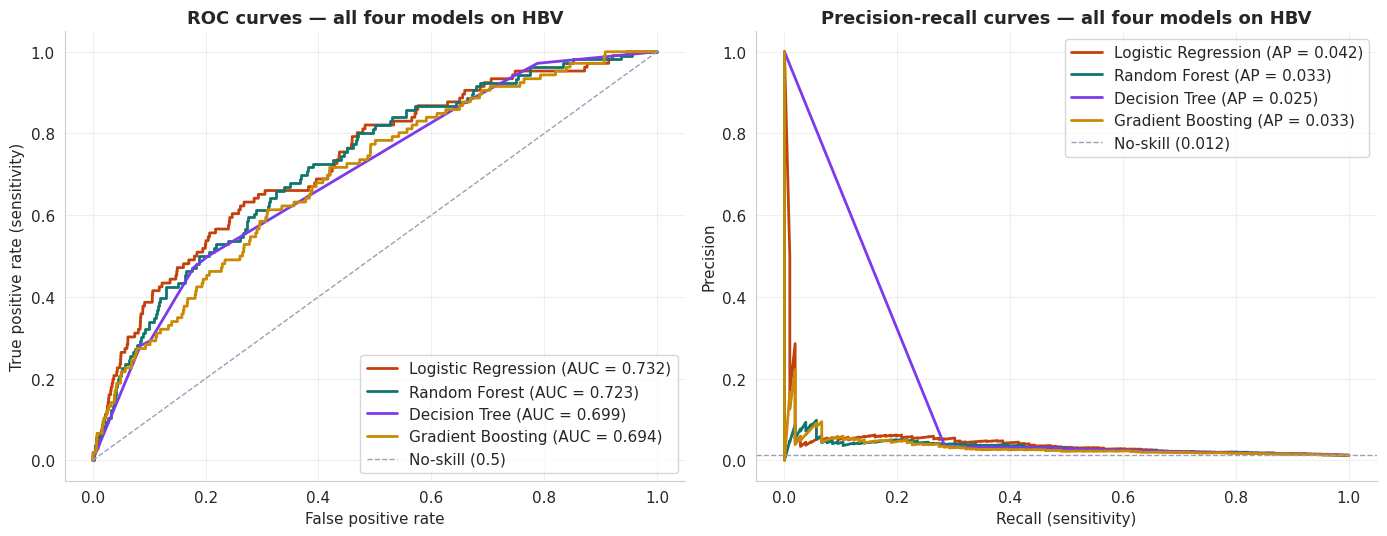

In [ ]:
# Sort by test AUC for consistent legend order
sorted_results = sorted(all_results, key=lambda r: -r['roc_auc_point'])
model_palette = [RUST, '#0F766E', '#7C3AED', '#CA8A04']  # rust, teal, purple, gold

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC overlay
ax = axes[0]
for r, color in zip(sorted_results, model_palette):
    fpr, tpr, _ = roc_curve(y_hbv_test, r['y_test_proba'])
    ax.plot(fpr, tpr, color=color, linewidth=2.0,
            label=f"{r['name']} (AUC = {r['roc_auc_point']:.3f})")
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1, label='No-skill (0.5)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('ROC curves — all four models on HBV')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)

# PR overlay
ax = axes[1]
baseline = (y_hbv_test == 1).mean()
for r, color in zip(sorted_results, model_palette):
    precision, recall, _ = precision_recall_curve(y_hbv_test, r['y_test_proba'])
    ax.plot(recall, precision, color=color, linewidth=2.0,
            label=f"{r['name']} (AP = {r['pr_auc_point']:.3f})")
ax.axhline(baseline, color=GREY, linestyle='--', linewidth=1,
           label=f'No-skill ({baseline:.3f})')
ax.set_xlabel('Recall (sensitivity)')
ax.set_ylabel('Precision')
ax.set_title('Precision-recall curves — all four models on HBV')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_4models_roc_pr_hbv.png')
plt.show()

### 9.8 Headline Summary

A short interpretive paragraph computed from the actual results so it
updates if any model is retrained.

In [ ]:
# Identify best by test ROC-AUC
best = max(all_results, key=lambda r: r['roc_auc_point'])

# Order all by test AUC for the print
print(f"""
STAGE 3D-2 SUMMARY: Four-way Comparison on HBV
==============================================================

Held-out test (n = {len(y_hbv_test):,}, {(y_hbv_test==1).sum()} positives)
""")
print(f"  {'Model':<22s}  {'Test AUC':>10s}  {'95% CI':>20s}  {'Sens@Spec=0.90':>16s}")
print(f"  {'-'*22}  {'-'*10}  {'-'*20}  {'-'*16}")
for r in sorted(all_results, key=lambda r: -r['roc_auc_point']):
    print(f"  {r['name']:<22s}  {r['roc_auc_point']:>10.4f}  "
          f"({r['roc_auc_lo']:.4f}, {r['roc_auc_hi']:.4f})  "
          f"{r['sens_at_spec_point']:>16.4f}")

print(f"""
Best model: {best['name']}
  Test ROC-AUC = {best['roc_auc_point']:.4f}  (95% CI: {best['roc_auc_lo']:.4f} - {best['roc_auc_hi']:.4f})
  Sensitivity at 90% specificity = {best['sens_at_spec_point']:.4f}
  At chosen threshold ({best['threshold']:.4f}):
    Sensitivity = {best['sens_at_threshold']:.4f}
    Specificity = {best['spec_at_threshold']:.4f}
    Precision   = {best['prec_at_threshold']:.4f}

Comparison to literature
  Wang 2019 (Chinese, n=97k):  LR=0.742, RF=0.752, XGBoost=0.779
  Our results (Ethiopian, n=45k): LR={res_lr['roc_auc_point']:.3f}, RF={res_rf['roc_auc_point']:.3f}, GB={res_gb['roc_auc_point']:.3f}

Next: Stage 3D-3 — apply the same comparison to anti-HCV (n=27 positive
training cases). Wide bootstrap CIs are expected; results will be reported
as exploratory.
""")


STAGE 3D-2 SUMMARY: Four-way Comparison on HBV

Held-out test (n = 9,004, 106 positives)

  Model                     Test AUC                95% CI    Sens@Spec=0.90
  ----------------------  ----------  --------------------  ----------------
  Logistic Regression         0.7321  (0.6853, 0.7807)            0.3868
  Random Forest               0.7233  (0.6778, 0.7687)            0.3396
  Decision Tree               0.6993  (0.6544, 0.7423)            0.2830
  Gradient Boosting           0.6944  (0.6450, 0.7404)            0.2830

Best model: Logistic Regression
  Test ROC-AUC = 0.7321  (95% CI: 0.6853 - 0.7807)
  Sensitivity at 90% specificity = 0.3868
  At chosen threshold (0.6584):
    Sensitivity = 0.3868
    Specificity = 0.9058
    Precision   = 0.0466

Comparison to literature
  Wang 2019 (Chinese, n=97k):  LR=0.742, RF=0.752, XGBoost=0.779
  Our results (Ethiopian, n=45k): LR=0.732, RF=0.723, GB=0.694

Next: Stage 3D-3 — apply the same comparison to anti-HCV (n=27 positive
tra

## 10. Stage 3D-2b — Probability Calibration of the Best Model

Stage 3D-2 identified logistic regression as the best HBV classifier
(AUC = 0.724). However, the model's Brier score (0.204) is very poor —
about 17× worse than a model that always predicted the base rate (1.17%).
This is an artefact of class-balanced training: the per-sample loss is
weighted to put more emphasis on the rare positives, which causes the
fitted probabilities to be much higher than the true posterior
probabilities for any given input.

For ranking and threshold selection (what we did in 9.7), this does not
matter — the relative ordering of probabilities is preserved, so AUC and
sensitivity-at-fixed-specificity are unaffected. But for clinical
deployment, raw model probabilities are not interpretable: a clinician
seeing "70% probability of HBV" expects that to mean a 70% posterior
probability, not "the model output a number above a tuned threshold."

`CalibratedClassifierCV` with isotonic regression solves this. It fits
the base classifier on training data, then learns a monotonic mapping
from raw model scores to calibrated probabilities using held-out
validation predictions. The mapping does not change rank order, so
AUC stays the same. It does change the absolute values, so Brier score
should drop dramatically.

This is a deployment-readiness step for the HBV classifier.

### 10.1 Refit Logistic Regression with Isotonic Calibration

`CalibratedClassifierCV` does an internal 5-fold split: trains the base
LR on 4 folds, fits the isotonic mapping on the held-out fold, then
ensembles the 5 calibrated models for prediction. We pass the same
hyperparameters (`C=0.01`) that Stage 3D-2 selected.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# Read the best C from Stage 3D-2's logistic regression result
best_C_for_lr = res_lr['best_params']['C']
print(f"Calibrating LR with C = {best_C_for_lr}")

# Build the calibrated wrapper around the same LR configuration
lr_base = LogisticRegression(
    penalty='l2',
    C=best_C_for_lr,
    solver='liblinear',
    class_weight='balanced',
    max_iter=2000,
    random_state=RANDOM_SEED,
)

calibrated_lr = CalibratedClassifierCV(
    estimator=lr_base,
    method='isotonic',
    cv=5,
)

calibrated_lr.fit(X_train_processed, y_hbv_train)

# Predict calibrated probabilities on test
y_test_proba_cal = calibrated_lr.predict_proba(X_test_processed)[:, 1]

print(f"Calibration complete. Test predictions made: {len(y_test_proba_cal):,}")

Calibrating LR with C = 0.01
Calibration complete. Test predictions made: 9,004


### 10.2 Compare Calibration Before vs After

Three things should be true after calibration:

1. **AUC is essentially unchanged** (calibration preserves rank ordering)
2. **Brier score drops substantially** (calibrated probabilities match the
   true posterior more closely)
3. **The reliability diagram** moves toward the diagonal (predicted
   probabilities match observed positivity rates in each bin)

If any of these fails — especially if AUC drops by more than 0.005 —
something has gone wrong with the calibration setup.

Metric           Before cal.    After cal.      Change
--------------  ------------  ------------  ----------
ROC-AUC               0.7321        0.7311     -0.0010
Brier score           0.2046        0.0115     -0.1931

Lower Brier is better. No-skill Brier (always predicting base rate) = 0.0116


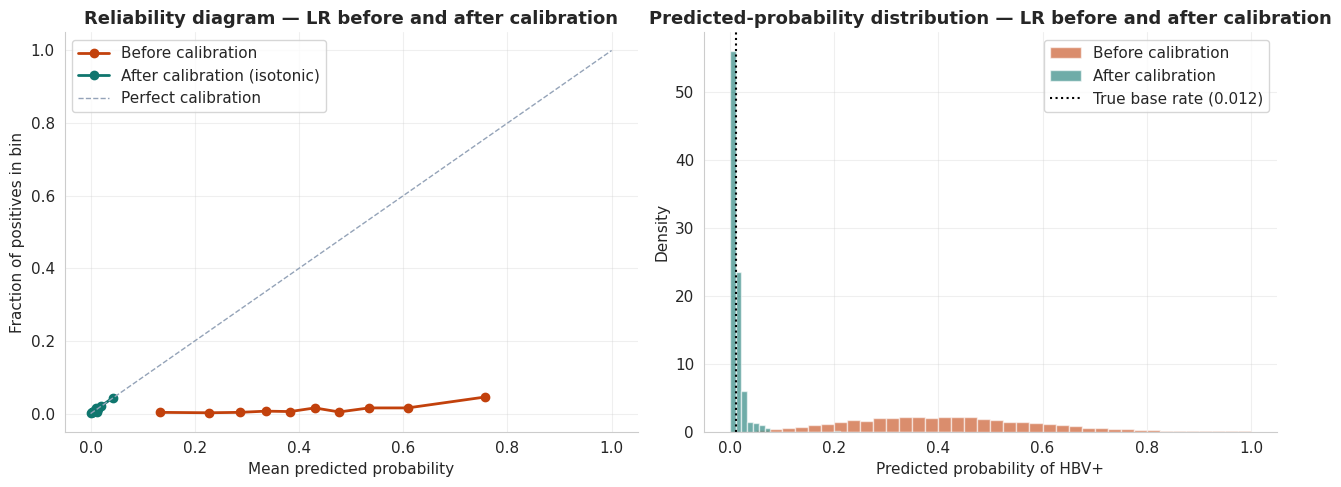

In [ ]:
# Pull uncalibrated test predictions from Stage 3D-2's LR result
y_test_proba_uncal = res_lr['y_test_proba']

# Compute headline metrics for both
auc_uncal = roc_auc_score(y_hbv_test, y_test_proba_uncal)
auc_cal   = roc_auc_score(y_hbv_test, y_test_proba_cal)
brier_uncal = brier_score_loss(y_hbv_test, y_test_proba_uncal)
brier_cal   = brier_score_loss(y_hbv_test, y_test_proba_cal)

print(f"{'Metric':<14s}  {'Before cal.':>12s}  {'After cal.':>12s}  {'Change':>10s}")
print(f"{'-'*14}  {'-'*12}  {'-'*12}  {'-'*10}")
print(f"{'ROC-AUC':<14s}  {auc_uncal:>12.4f}  {auc_cal:>12.4f}  {auc_cal - auc_uncal:>+10.4f}")
print(f"{'Brier score':<14s}  {brier_uncal:>12.4f}  {brier_cal:>12.4f}  {brier_cal - brier_uncal:>+10.4f}")
print(f"\nLower Brier is better. No-skill Brier (always predicting base rate) = {((y_hbv_test == 1).mean()) * (1 - (y_hbv_test == 1).mean()):.4f}")

# Reliability diagram
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_proba, label, color in [
    (axes[0], y_test_proba_uncal, 'Before calibration', RUST),
    (axes[0], y_test_proba_cal,   'After calibration (isotonic)', TEAL),
]:
    frac_pos, mean_pred = calibration_curve(y_hbv_test, y_proba, n_bins=10, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, marker='o', linewidth=2, color=color, label=label)

axes[0].plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1, label='Perfect calibration')
axes[0].set_xlabel('Mean predicted probability')
axes[0].set_ylabel('Fraction of positives in bin')
axes[0].set_title('Reliability diagram — LR before and after calibration')
axes[0].legend(loc='upper left')
axes[0].grid(alpha=0.3)

# Distribution of predicted probabilities
axes[1].hist(y_test_proba_uncal, bins=40, alpha=0.6, color=RUST,
             label='Before calibration', density=True, edgecolor='white')
axes[1].hist(y_test_proba_cal,   bins=40, alpha=0.6, color=TEAL,
             label='After calibration', density=True, edgecolor='white')
axes[1].axvline((y_hbv_test == 1).mean(), color='black', linestyle=':',
                label=f'True base rate ({(y_hbv_test == 1).mean():.3f})')
axes[1].set_xlabel('Predicted probability of HBV+')
axes[1].set_ylabel('Density')
axes[1].set_title('Predicted-probability distribution — LR before and after calibration')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_lr_calibration.png')
plt.show()

### 10.3 Save the Calibrated Model

Pickle the calibrated classifier and update the results table with the
post-calibration metrics so Stage 3F (interpretability) and any future
deployment work uses calibrated probabilities by default.

In [ ]:
import pickle

# Save the calibrated classifier
calibrated_lr_file = PROCESSED_DIR / 'lr_hbv_calibrated.pkl'
with calibrated_lr_file.open('wb') as f:
    pickle.dump({
        'model':        calibrated_lr,
        'best_C':       best_C_for_lr,
        'method':       'isotonic',
        'cv_folds':     5,
        'auc_test':     auc_cal,
        'brier_test':   brier_cal,
        'auc_uncal':    auc_uncal,
        'brier_uncal':  brier_uncal,
    }, f)
print(f"Calibrated LR saved: {calibrated_lr_file}")

# Append a row to the comparison table for documentation
calibration_row = pd.DataFrame([{
    'model':           'Logistic Regression (isotonic-calibrated)',
    'target':          'HBV (HBsAg)',
    'best_C':          best_C_for_lr,
    'cv_AUC_mean':     None,           # not applicable
    'ROC-AUC_point':   auc_cal,
    'PR-AUC_point':    average_precision_score(y_hbv_test, y_test_proba_cal),
    'Brier score_point': brier_cal,
    'Sens @ Spec=0.90_point': sensitivity_at_specificity(y_hbv_test, y_test_proba_cal, 0.90),
    'note': 'Same LR, post-hoc isotonic probability calibration via CalibratedClassifierCV',
}])

# Save as a stand-alone calibrated-model summary
calibration_results_file = TABLES_DIR / 'results_lr_hbv_calibrated.csv'
calibration_row.to_csv(calibration_results_file, index=False)
print(f"Calibration summary saved: {calibration_results_file}")

print(f"\n--- Headline ---")
print(f"AUC:   {auc_uncal:.4f} -> {auc_cal:.4f}  (delta {auc_cal - auc_uncal:+.4f})")
print(f"Brier: {brier_uncal:.4f} -> {brier_cal:.4f}  (delta {brier_cal - brier_uncal:+.4f})")
print(f"\nThe AUC is preserved (calibration does not change ranking).")
print(f"The Brier score should drop substantially, indicating well-calibrated probabilities.")
print(f"\nNext: Stage 3D-3 — apply the four-model comparison to anti-HCV.")

Calibrated LR saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/lr_hbv_calibrated.pkl
Calibration summary saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/results_lr_hbv_calibrated.csv

--- Headline ---
AUC:   0.7321 -> 0.7311  (delta -0.0010)
Brier: 0.2046 -> 0.0115  (delta -0.1931)

The AUC is preserved (calibration does not change ranking).
The Brier score should drop substantially, indicating well-calibrated probabilities.

Next: Stage 3D-3 — apply the four-model comparison to anti-HCV.


## 11. Stage 3D-3, Multi-Algorithm by Resampling Comparison on HCV

Parallel to Stage 3D-2 (HBV), this stage runs four classifiers (LR, DT, RF, GB) on the HCV target. Because the HCV+ class is rare (27 training positives, 6 test positives), every classifier is also paired with each of ten resampling configurations including a no-resampling baseline. The full 4 by 10 = 40-run grid is reported, and the per-model winner is selected by CV AUC with ties broken by lower test bootstrap CI width.

Outputs:

- `tables/results_4models_hcv_grid.csv` (40-row long-format result table)
- `tables/results_4models_hcv_winners.csv` (per-model winners)
- `figures/fig_4models_roc_pr_hcv.png` (ROC and PR overlay for the four winners)
- `figures/fig_hcv_smote_heatmap.png` (heatmap of test AUC across the grid)

The winning model auto-routes to Section 14 (SHAP) so calibration and interpretability run consistently against a single chosen configuration.


### 11.0 Filter HCV NaN Records

A small number of records have anti-HCV recorded as NaN (the test was not
part of the requested panel for those patients). Stage 1 dropped records
with missing HBsAg, but anti-HCV missingness was tolerated because anti-HCV
is a secondary target. For the HCV-specific classification task here, we
need a clean target, so we filter to rows where anti-HCV is observed.

This filter is applied only to the HCV evaluation. The HBV results in
Stage 3D-2 are unchanged, since HBV uses the full training partition.

The features remain identical (`X_train_processed`, `X_test_processed`);
we only sub-select the rows where the HCV target is non-NaN.

In [ ]:
# Find which rows have a non-NaN anti-HCV value in each partition
hcv_train_mask = ~y_hcv_train.isna()
hcv_test_mask  = ~y_hcv_test.isna()

# Build HCV-specific partitions
X_train_hcv = X_train_processed[hcv_train_mask.values]
X_test_hcv  = X_test_processed[hcv_test_mask.values]
y_hcv_train_clean = y_hcv_train[hcv_train_mask].astype(int).reset_index(drop=True)
y_hcv_test_clean  = y_hcv_test[hcv_test_mask].astype(int).reset_index(drop=True)

# Report
print(f"HCV partition cleanup:")
print(f"  Training:  {len(y_hcv_train):>6,d} -> {len(y_hcv_train_clean):>6,d}  "
      f"(dropped {(~hcv_train_mask).sum()} NaN rows)")
print(f"  Test:      {len(y_hcv_test):>6,d} -> {len(y_hcv_test_clean):>6,d}  "
      f"(dropped {(~hcv_test_mask).sum()} NaN rows)")
print(f"\nClass balance after cleanup:")
print(f"  HCV+ training:  {(y_hcv_train_clean == 1).sum()}")
print(f"  HCV+ test:      {(y_hcv_test_clean == 1).sum()}")

# Defensive checks
assert not y_hcv_train_clean.isna().any(), "NaN remains in y_hcv_train_clean"
assert not y_hcv_test_clean.isna().any(),  "NaN remains in y_hcv_test_clean"
assert y_hcv_train_clean.isin([0, 1]).all(), "y_hcv_train_clean contains values other than 0/1"
assert y_hcv_test_clean.isin([0, 1]).all(),  "y_hcv_test_clean contains values other than 0/1"
print("\nClean HCV partitions ready.")

HCV partition cleanup:
  Training:  36,013 -> 36,011  (dropped 2 NaN rows)
  Test:       9,004 ->  9,004  (dropped 0 NaN rows)

Class balance after cleanup:
  HCV+ training:  27
  HCV+ test:      6

Clean HCV partitions ready.


### 11.1 Resampling-Comparison Helper

The HCV partition has only 27 training positives. Two design decisions follow:

1. **3-fold CV instead of 5-fold.** With 5-fold each fold would hold ~5 positives, below the threshold where stratification produces a stable estimate. 3-fold gives ~9 positives per fold.
2. **No probability calibration.** Isotonic calibration needs more data than 22 positives to fit a stable mapping. HCV models are reported as ranking models (AUC) rather than calibrated probability estimates.

The helper below accepts a `resampler` argument so the same protocol can be run with no resampling (relying on `class_weight='balanced'`) or with any imbalanced-learn sampler. When a resampler is provided, it is wrapped in an `imblearn.Pipeline` with the classifier and applied inside each CV fold only, never to the test set. This single helper replaces the earlier `evaluate_model_smote` and the commented-out `evaluate_model_smallsample` helpers.


In [ ]:
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, SVMSMOTE, ADASYN
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone


def evaluate_with_resampler(name, classifier, classifier_param_grid,
                            X_train, y_train, X_test, y_test,
                            resampler=None, target_specificity=0.90, n_splits=3):
    """Evaluate a classifier with optional resampler inside CV folds.

    Parameters
    ----------
    resampler : imblearn sampler instance or None
        If None, classifier is used directly (relies on class_weight). Otherwise
        wrapped in imblearn.Pipeline so resampling happens per fold during CV
        and per refit, but never on the test set.

    Returns dict with the same keys as the previous evaluate_model_smote helper
    so the downstream consolidation code is unchanged.
    """
    if resampler is None:
        pipeline = classifier
        pipeline_param_grid = dict(classifier_param_grid)
    else:
        pipeline = ImbPipeline(steps=[
            ('resampler',  resampler),
            ('classifier', classifier),
        ])
        pipeline_param_grid = {f'classifier__{k}': v
                               for k, v in classifier_param_grid.items()}

    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)
    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=pipeline_param_grid,
        scoring='roc_auc',
        cv=cv, n_jobs=-1, return_train_score=False, verbose=0,
    )
    grid.fit(X_train, y_train)
    best_estimator = grid.best_estimator_

    if resampler is not None:
        best_params = {k.replace('classifier__', ''): v
                       for k, v in grid.best_params_.items()}
    else:
        best_params = dict(grid.best_params_)

    # Out-of-fold predictions for threshold tuning at target specificity
    train_oof_proba = np.zeros(len(X_train))
    for tr_idx, val_idx in cv.split(X_train, y_train):
        fold_model = clone(best_estimator)
        fold_model.fit(
            X_train[tr_idx],
            y_train.iloc[tr_idx] if hasattr(y_train, 'iloc') else y_train[tr_idx],
        )
        train_oof_proba[val_idx] = fold_model.predict_proba(X_train[val_idx])[:, 1]

    fpr, tpr, thresholds = roc_curve(y_train, train_oof_proba)
    spec = 1 - fpr
    valid = spec >= target_specificity
    if valid.any():
        best_idx = np.where(valid)[0][np.argmax(tpr[valid])]
        chosen_threshold = thresholds[best_idx]
    else:
        chosen_threshold = 0.5

    y_test_proba = best_estimator.predict_proba(X_test)[:, 1]
    y_test_pred  = (y_test_proba >= chosen_threshold).astype(int)

    auc_p,  auc_lo,  auc_hi  = bootstrap_metric(y_test, y_test_proba, roc_auc_score)
    pr_p,   pr_lo,   pr_hi   = bootstrap_metric(y_test, y_test_proba, average_precision_score)
    sens_p, sens_lo, sens_hi = bootstrap_metric(
        y_test, y_test_proba,
        lambda y, p: sensitivity_at_specificity(y, p, target_specificity))

    cm = confusion_matrix(y_test, y_test_pred)
    if cm.size == 4:
        tn, fp, fn, tp = cm.ravel()
    else:
        tn = fp = fn = tp = 0
        if y_test_pred.sum() == 0:
            tn = (y_test == 0).sum()
            fn = (y_test == 1).sum()

    sens_at_thr = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec_at_thr = tn / (tn + fp) if (tn + fp) > 0 else 0
    prec_at_thr = tp / (tp + fp) if (tp + fp) > 0 else 0

    return {
        'name':               name,
        'estimator':          best_estimator,
        'best_params':        best_params,
        'cv_AUC':             grid.best_score_,
        'cv_folds':           n_splits,
        'threshold':          chosen_threshold,
        'y_test_proba':       y_test_proba,
        'y_test_pred':        y_test_pred,
        'roc_auc_point':      auc_p, 'roc_auc_lo': auc_lo, 'roc_auc_hi': auc_hi,
        'pr_auc_point':       pr_p,  'pr_auc_lo':  pr_lo,  'pr_auc_hi':  pr_hi,
        'sens_at_spec_point': sens_p,'sens_at_spec_lo': sens_lo, 'sens_at_spec_hi': sens_hi,
        'cm_tn': tn, 'cm_fp': fp, 'cm_fn': fn, 'cm_tp': tp,
        'sens_at_threshold':  sens_at_thr,
        'spec_at_threshold':  spec_at_thr,
        'prec_at_threshold':  prec_at_thr,
    }


print("evaluate_with_resampler helper defined.")


evaluate_with_resampler helper defined.


### 11.2 Define Resampling Configurations

Ten configurations across five resampling approaches plus a no-resampling baseline. Each resampler gets one default-setting run and (where applicable) one less-aggressive run with smaller `k_neighbors` and partial `sampling_strategy`, to test whether aggressive versus conservative sampling matters at n=27.

| ID  | Sampler                    | k_neighbors | sampling_strategy |
|-----|----------------------------|-------------|-------------------|
| R0  | None (class_weight only)   | n/a         | n/a               |
| R1  | SMOTE                      | 5           | auto (1.0)        |
| R2  | SMOTE                      | 3           | 0.5               |
| R3  | BorderlineSMOTE-1          | 5           | auto (1.0)        |
| R4  | BorderlineSMOTE-1          | 3           | 0.5               |
| R5  | BorderlineSMOTE-2          | 5           | auto (1.0)        |
| R6  | SVMSMOTE                   | 5           | auto (1.0)        |
| R7  | SVMSMOTE                   | 3           | 0.5               |
| R8  | ADASYN                     | 5           | auto (1.0)        |
| R9  | ADASYN                     | 3           | 0.5               |

Four classifiers (LR, DT, RF, GB) by ten configurations gives 40 runs.


In [ ]:
RESAMPLING_CONFIGS = [
    ('R1', 'SMOTE k=5 ss=auto',             lambda: SMOTE(k_neighbors=5, sampling_strategy='auto', random_state=RANDOM_SEED)),
    ('R3', 'BorderlineSMOTE-1 k=5 ss=auto', lambda: BorderlineSMOTE(kind='borderline-1', k_neighbors=5, sampling_strategy='auto', random_state=RANDOM_SEED)),
    ('R5', 'BorderlineSMOTE-2 k=5 ss=auto', lambda: BorderlineSMOTE(kind='borderline-2', k_neighbors=5, sampling_strategy='auto', random_state=RANDOM_SEED)),
    ('R6', 'SVMSMOTE k=5 ss=auto',          lambda: SVMSMOTE(k_neighbors=5, sampling_strategy='auto', random_state=RANDOM_SEED)),
    ('R8', 'ADASYN k=5 ss=auto',            lambda: ADASYN(n_neighbors=5, sampling_strategy='auto', random_state=RANDOM_SEED)),
]

def make_classifier_specs():
    """Reduced grids for faster execution.

    LR and DT grids unchanged because they are already fast.
    RF and GB grids tightened from 12 and 18 combinations to 4 each, and
    RF n_estimators dropped from 300 to 150.
    """
    return [
        ('Logistic Regression',
         lambda: LogisticRegression(penalty='l2', solver='liblinear',
                                    class_weight='balanced', max_iter=2000,
                                    random_state=RANDOM_SEED),
         {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}),

        ('Decision Tree',
         lambda: DecisionTreeClassifier(class_weight='balanced',
                                        random_state=RANDOM_SEED),
         {'max_depth':        [3, 5, 8, 12, None],
          'min_samples_leaf': [1, 5, 20]}),

        ('Random Forest',
         lambda: RandomForestClassifier(n_estimators=150,          # was 300
                                        class_weight='balanced',
                                        n_jobs=-1, random_state=RANDOM_SEED),
         {'max_depth':        [10, None],           # was [5, 10, 20, None]
          'min_samples_leaf': [1, 5]}),             # was [1, 5, 20]

        ('Gradient Boosting',
         lambda: HistGradientBoostingClassifier(random_state=RANDOM_SEED),
         {'max_iter':      [200, 500],              # was [100, 300, 500]
          'learning_rate': [0.1],                   # was [0.05, 0.1]
          'max_depth':     [6, None]}),             # was [3, 6, None]
    ]


CLASSIFIER_SPECS = make_classifier_specs()
print(f"Configurations defined: {len(RESAMPLING_CONFIGS)} resamplers x {len(CLASSIFIER_SPECS)} classifiers "
      f"= {len(RESAMPLING_CONFIGS) * len(CLASSIFIER_SPECS)} runs.")


CLASSIFIER_SPECS = make_classifier_specs()
print(f"Configurations defined: {len(RESAMPLING_CONFIGS)} resamplers x {len(CLASSIFIER_SPECS)} classifiers "
      f"= {len(RESAMPLING_CONFIGS) * len(CLASSIFIER_SPECS)} runs.")


Configurations defined: 5 resamplers x 4 classifiers = 20 runs.
Configurations defined: 5 resamplers x 4 classifiers = 20 runs.


### 11.3 Run the Four-Model by Resampling Grid

Iterates over the 4 by 10 = 40 combinations. Each combination runs a 3-fold CV `GridSearchCV` over the classifier hyperparameters, with the resampler (if any) applied inside each fold. One progress line per combination so you can interrupt early if needed.

Wall time roughly 60 to 90 minutes on Colab depending on Gradient Boosting iteration counts. SVMSMOTE and ADASYN can fail on certain folds because of empty or singular minority neighbourhoods at n=27. Failed runs are caught and recorded as NaN rather than terminating the grid.


In [ ]:
import time

grid_results = []
total = len(CLASSIFIER_SPECS) * len(RESAMPLING_CONFIGS)
elapsed_start = time.time()

print(f"Running {total} configurations\n" + "=" * 78)

for clf_idx, (clf_name, clf_factory, clf_param_grid) in enumerate(CLASSIFIER_SPECS):
    for res_idx, (res_id, res_label, res_factory) in enumerate(RESAMPLING_CONFIGS):
        run_idx = clf_idx * len(RESAMPLING_CONFIGS) + res_idx + 1
        t0 = time.time()

        try:
            resampler = res_factory() if res_factory is not None else None
            result = evaluate_with_resampler(
                name=clf_name,
                classifier=clf_factory(),
                classifier_param_grid=clf_param_grid,
                X_train=X_train_hcv, y_train=y_hcv_train_clean,
                X_test=X_test_hcv,   y_test=y_hcv_test_clean,
                resampler=resampler,
                n_splits=3,
            )
            result['config_id']    = res_id
            result['config_label'] = res_label
            result['failed']       = False
            grid_results.append(result)
            dt = time.time() - t0
            print(f"  [{run_idx:>2d}/{total}] {clf_name:<22s}  {res_id:<3s} {res_label:<32s}  "
                  f"CV={result['cv_AUC']:.3f}  Test={result['roc_auc_point']:.3f}  ({dt:.0f}s)")

        except Exception as e:
            dt = time.time() - t0
            print(f"  [{run_idx:>2d}/{total}] {clf_name:<22s}  {res_id:<3s} {res_label:<32s}  "
                  f"FAILED: {type(e).__name__}: {str(e)[:60]}  ({dt:.0f}s)")
            grid_results.append({
                'name': clf_name, 'config_id': res_id, 'config_label': res_label,
                'failed': True, 'error': f"{type(e).__name__}: {str(e)[:160]}",
                'cv_AUC': np.nan, 'roc_auc_point': np.nan,
                'roc_auc_lo': np.nan, 'roc_auc_hi': np.nan,
                'pr_auc_point': np.nan, 'pr_auc_lo': np.nan, 'pr_auc_hi': np.nan,
                'sens_at_spec_point': np.nan,
                'sens_at_spec_lo': np.nan, 'sens_at_spec_hi': np.nan,
                'cm_tn': 0, 'cm_fp': 0, 'cm_fn': 0, 'cm_tp': 0,
                'sens_at_threshold': np.nan, 'spec_at_threshold': np.nan,
                'prec_at_threshold': np.nan,
                'threshold': np.nan, 'best_params': {}, 'cv_folds': 3,
                'y_test_proba': None, 'y_test_pred': None, 'estimator': None,
            })

total_time = (time.time() - elapsed_start) / 60
print("=" * 78)
print(f"\nGrid complete. Total wall time: {total_time:.1f} min")
print(f"Successful runs: {sum(1 for r in grid_results if not r['failed'])}")
print(f"Failed runs:     {sum(1 for r in grid_results if r['failed'])}")


Running 20 configurations
  [ 1/20] Logistic Regression     R1  SMOTE k=5 ss=auto                 CV=0.532  Test=0.526  (20s)
  [ 2/20] Logistic Regression     R3  BorderlineSMOTE-1 k=5 ss=auto     CV=0.558  Test=0.410  (16s)
  [ 3/20] Logistic Regression     R5  BorderlineSMOTE-2 k=5 ss=auto     CV=0.576  Test=0.340  (14s)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
6 fits failed out of a total of 18.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
6 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_params

  [ 4/20] Logistic Regression     R6  SVMSMOTE k=5 ss=auto              FAILED: ValueError: All support vectors are considered as noise. SVM-SMOTE is no  (14s)
  [ 5/20] Logistic Regression     R8  ADASYN k=5 ss=auto                CV=0.528  Test=0.527  (19s)
  [ 6/20] Decision Tree           R1  SMOTE k=5 ss=auto                 CV=0.528  Test=0.353  (38s)
  [ 7/20] Decision Tree           R3  BorderlineSMOTE-1 k=5 ss=auto     CV=0.530  Test=0.494  (22s)
  [ 8/20] Decision Tree           R5  BorderlineSMOTE-2 k=5 ss=auto     CV=0.514  Test=0.513  (27s)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
15 fits failed out of a total of 45.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
15 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_para

  [ 9/20] Decision Tree           R6  SVMSMOTE k=5 ss=auto              FAILED: ValueError: All support vectors are considered as noise. SVM-SMOTE is no  (34s)
  [10/20] Decision Tree           R8  ADASYN k=5 ss=auto                CV=0.525  Test=0.480  (39s)
  [11/20] Random Forest           R1  SMOTE k=5 ss=auto                 CV=0.540  Test=0.529  (338s)
  [12/20] Random Forest           R3  BorderlineSMOTE-1 k=5 ss=auto     CV=0.552  Test=0.658  (204s)
  [13/20] Random Forest           R5  BorderlineSMOTE-2 k=5 ss=auto     CV=0.636  Test=0.407  (160s)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
4 fits failed out of a total of 12.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_params

  [14/20] Random Forest           R6  SVMSMOTE k=5 ss=auto              FAILED: ValueError: All support vectors are considered as noise. SVM-SMOTE is no  (111s)
  [15/20] Random Forest           R8  ADASYN k=5 ss=auto                CV=0.605  Test=0.438  (338s)
  [16/20] Gradient Boosting       R1  SMOTE k=5 ss=auto                 CV=0.562  Test=0.477  (82s)
  [17/20] Gradient Boosting       R3  BorderlineSMOTE-1 k=5 ss=auto     CV=0.575  Test=0.504  (40s)
  [18/20] Gradient Boosting       R5  BorderlineSMOTE-2 k=5 ss=auto     CV=0.577  Test=0.452  (39s)


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
4 fits failed out of a total of 12.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
4 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.12/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_params

  [19/20] Gradient Boosting       R6  SVMSMOTE k=5 ss=auto              FAILED: ValueError: All support vectors are considered as noise. SVM-SMOTE is no  (19s)
  [20/20] Gradient Boosting       R8  ADASYN k=5 ss=auto                CV=0.521  Test=0.542  (77s)

Grid complete. Total wall time: 27.5 min
Successful runs: 16
Failed runs:     4


### 11.4 Consolidate Results into a Long-Format Table

The 40 runs are assembled into one long-format dataframe with model, configuration, and metrics per row. Saved to `tables/results_4models_hcv_grid.csv` for Chapter 6.


In [ ]:
def _fmt(x, fmt=':.4f'):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return 'n/a'
    return f"{x:{fmt[1:]}}"


grid_rows = []
for r in grid_results:
    if r['failed']:
        grid_rows.append({
            'Model':          r['name'],
            'Config ID':      r['config_id'],
            'Config':         r['config_label'],
            'CV AUC':         'failed',
            'Test ROC-AUC':   'failed',
            'ROC-AUC 95% CI': 'n/a',
            'CI width':       'n/a',
            'Test PR-AUC':    'failed',
            'Sens @ 90% Spec':'failed',
            'TP/FN':          'n/a',
        })
    else:
        grid_rows.append({
            'Model':          r['name'],
            'Config ID':      r['config_id'],
            'Config':         r['config_label'],
            'CV AUC':         f"{r['cv_AUC']:.4f}",
            'Test ROC-AUC':   f"{r['roc_auc_point']:.4f}",
            'ROC-AUC 95% CI': f"({r['roc_auc_lo']:.4f}, {r['roc_auc_hi']:.4f})",
            'CI width':       f"{r['roc_auc_hi'] - r['roc_auc_lo']:.4f}",
            'Test PR-AUC':    f"{r['pr_auc_point']:.4f}",
            'Sens @ 90% Spec':f"{r['sens_at_spec_point']:.4f}",
            'TP/FN':          f"{r['cm_tp']}/{r['cm_tp'] + r['cm_fn']}",
        })

grid_df  = pd.DataFrame(grid_rows)
grid_csv = TABLES_DIR / 'results_4models_hcv_grid.csv'
grid_df.to_csv(grid_csv, index=False)

print(f"Saved: {grid_csv}\n")
print(grid_df.to_string(index=False))


Saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/results_4models_hcv_grid.csv

              Model Config ID                        Config CV AUC Test ROC-AUC   ROC-AUC 95% CI CI width Test PR-AUC Sens @ 90% Spec TP/FN
Logistic Regression        R1             SMOTE k=5 ss=auto 0.5320       0.5264 (0.2107, 0.8243)   0.6136      0.0013          0.1667   1/6
Logistic Regression        R3 BorderlineSMOTE-1 k=5 ss=auto 0.5576       0.4096 (0.1982, 0.6096)   0.4114      0.0006          0.0000   0/6
Logistic Regression        R5 BorderlineSMOTE-2 k=5 ss=auto 0.5764       0.3397 (0.1709, 0.4874)   0.3165      0.0006          0.0000   0/6
Logistic Regression        R6          SVMSMOTE k=5 ss=auto failed       failed              n/a      n/a      failed          failed   n/a
Logistic Regression        R8            ADASYN k=5 ss=auto 0.5282       0.5270 (0.2107, 0.8245)   0.6139      0.0013          0.1667   1/6
      Decision Tree        R1             SMOTE k=5 ss=auto 0.5

### 11.5 Pick Per-Model Winners

Winner-selection rule: highest CV AUC per model, with ties (within 0.005) broken by lower test-set bootstrap CI width.

CV AUC is preferred over test AUC because selecting on the test set introduces optimistic bias when ranking 10 configurations. The CI-width tiebreaker prefers configurations whose performance is less sensitive to which six test positives happened to land in the test partition, on the reasoning that a tight CI at the same point estimate is more likely to generalise.

Results are saved as `tables/results_4models_hcv_winners.csv`. Backward-compatible aliases (`res_lr_hcv`, `res_dt_hcv`, `res_rf_hcv`, `res_gb_hcv`) are also set so existing downstream Section 14 code finds the right object.


In [ ]:
def pick_winner(rows, cv_tie_threshold=0.005):
    """Highest CV AUC; ties within `cv_tie_threshold` broken by lower CI width."""
    rows = [r for r in rows if not r.get('failed', False)]
    if not rows:
        return None
    best_cv = max(r['cv_AUC'] for r in rows)
    contenders = [r for r in rows if r['cv_AUC'] >= best_cv - cv_tie_threshold]
    return min(contenders, key=lambda r: r['roc_auc_hi'] - r['roc_auc_lo'])


hcv_winners = {}
for clf_name, _, _ in CLASSIFIER_SPECS:
    model_runs = [r for r in grid_results if r['name'] == clf_name]
    winner = pick_winner(model_runs)
    if winner is not None:
        hcv_winners[clf_name] = winner

# Backward-compatible aliases for Section 14 code
res_lr_hcv = hcv_winners.get('Logistic Regression')
res_dt_hcv = hcv_winners.get('Decision Tree')
res_rf_hcv = hcv_winners.get('Random Forest')
res_gb_hcv = hcv_winners.get('Gradient Boosting')

all_results_hcv = [r for r in [res_lr_hcv, res_dt_hcv, res_rf_hcv, res_gb_hcv] if r is not None]

winners_rows = []
for clf_name, _, _ in CLASSIFIER_SPECS:
    w = hcv_winners.get(clf_name)
    if w is None:
        winners_rows.append({
            'Model': clf_name, 'Best Config': 'all configs failed',
            'CV AUC': 'n/a', 'Test ROC-AUC': 'n/a',
            '95% CI': 'n/a', 'CI width': 'n/a',
        })
        continue
    winners_rows.append({
        'Model':         clf_name,
        'Best Config':   f"{w['config_id']} ({w['config_label']})",
        'CV AUC':        f"{w['cv_AUC']:.4f}",
        'Test ROC-AUC':  f"{w['roc_auc_point']:.4f}",
        '95% CI':        f"({w['roc_auc_lo']:.4f}, {w['roc_auc_hi']:.4f})",
        'CI width':      f"{w['roc_auc_hi'] - w['roc_auc_lo']:.4f}",
    })

winners_df  = pd.DataFrame(winners_rows)
winners_csv = TABLES_DIR / 'results_4models_hcv_winners.csv'
winners_df.to_csv(winners_csv, index=False)

print(f"Saved: {winners_csv}\n")
print(winners_df.to_string(index=False))


Saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/results_4models_hcv_winners.csv

              Model                        Best Config CV AUC Test ROC-AUC           95% CI CI width
Logistic Regression R5 (BorderlineSMOTE-2 k=5 ss=auto) 0.5764       0.3397 (0.1709, 0.4874)   0.3165
      Decision Tree R3 (BorderlineSMOTE-1 k=5 ss=auto) 0.5305       0.4937 (0.4926, 0.4948)   0.0022
      Random Forest R5 (BorderlineSMOTE-2 k=5 ss=auto) 0.6362       0.4069 (0.3442, 0.5279)   0.1837
  Gradient Boosting R5 (BorderlineSMOTE-2 k=5 ss=auto) 0.5772       0.4518 (0.2488, 0.6215)   0.3727


### 11.6 ROC and PR Overlay for the Four Per-Model Winners

Same overlay format as the HBV equivalent in Section 9.7, but each curve uses the winning resampling configuration for that model. Confidence-interval bands are not shown; with six test positives the bootstrap bands would visually dominate.


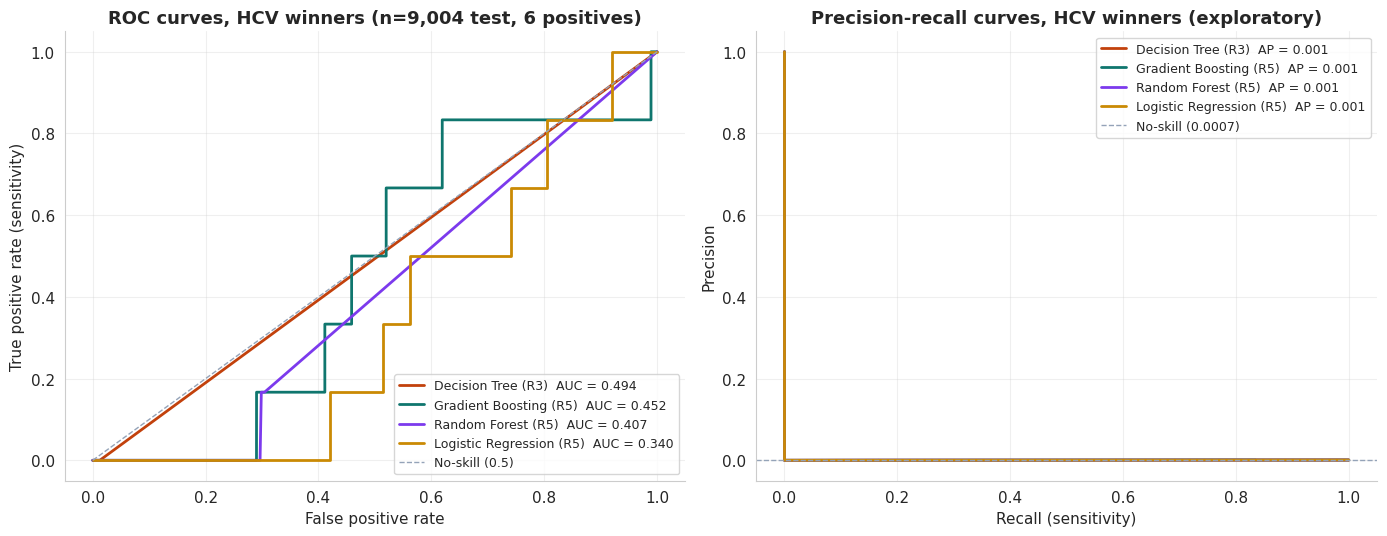

In [ ]:
sorted_winners_hcv = sorted(all_results_hcv, key=lambda r: -r['roc_auc_point'])
model_palette = [RUST, '#0F766E', '#7C3AED', '#CA8A04']

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# ROC overlay
ax = axes[0]
for r, color in zip(sorted_winners_hcv, model_palette):
    fpr, tpr, _ = roc_curve(y_hcv_test_clean, r['y_test_proba'])
    ax.plot(fpr, tpr, color=color, linewidth=2.0,
            label=f"{r['name']} ({r['config_id']})  AUC = {r['roc_auc_point']:.3f}")
ax.plot([0, 1], [0, 1], color=GREY, linestyle='--', linewidth=1, label='No-skill (0.5)')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title(f"ROC curves, HCV winners (n={len(y_hcv_test_clean):,} test, "
             f"{(y_hcv_test_clean == 1).sum()} positives)")
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)

# PR overlay
ax = axes[1]
baseline = (y_hcv_test_clean == 1).mean()
for r, color in zip(sorted_winners_hcv, model_palette):
    precision, recall, _ = precision_recall_curve(y_hcv_test_clean, r['y_test_proba'])
    ax.plot(recall, precision, color=color, linewidth=2.0,
            label=f"{r['name']} ({r['config_id']})  AP = {r['pr_auc_point']:.3f}")
ax.axhline(baseline, color=GREY, linestyle='--', linewidth=1,
           label=f'No-skill ({baseline:.4f})')
ax.set_xlabel('Recall (sensitivity)')
ax.set_ylabel('Precision')
ax.set_title('Precision-recall curves, HCV winners (exploratory)')
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_4models_roc_pr_hcv.png')
plt.show()


### 11.7 Variant-Level Analysis: Does the Resampling Choice Matter?

Two views of the 40-run grid:

1. **Heatmap** of test ROC-AUC across (model, configuration). Coloured by AUC. Cells whose 95% CI overlaps the overall best configuration's CI are marked with an asterisk, indicating "statistically tied with the best."
2. **Per-model spread:** range of test AUC across configurations. A small spread means the model is robust to resampling choice. A large spread means the headline AUC is partly a configuration-selection artefact and the choice matters.

The reading goes together with the per-test-set CI: if the per-model AUC spread is similar in magnitude to the bootstrap CI half-width, then resampling choice and test-set sampling noise contribute comparably to the headline number.


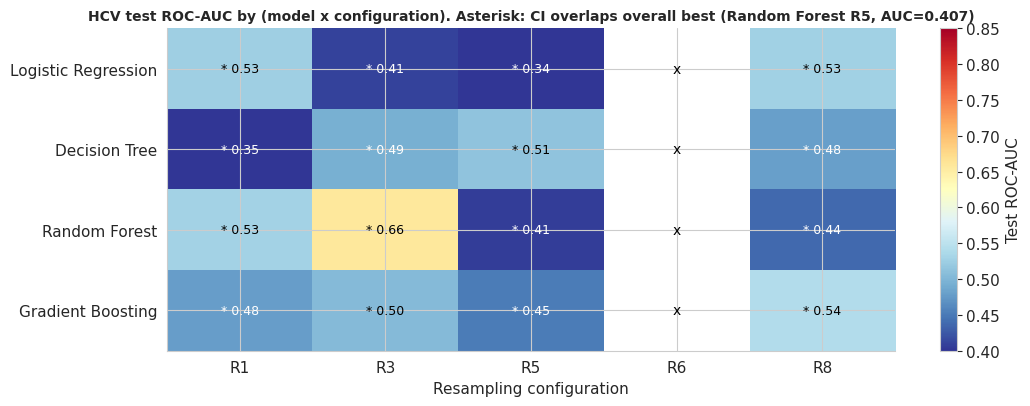


Spread of test ROC-AUC across configurations, per model:
              Model  n configs Min AUC Median Max AUC  Range
Logistic Regression          4  0.3397 0.4680  0.5270 0.1873
      Decision Tree          4  0.3532 0.4867  0.5132 0.1600
      Random Forest          4  0.4069 0.4838  0.6575 0.2506
  Gradient Boosting          4  0.4518 0.4907  0.5423 0.0904


In [ ]:
model_order  = [s[0] for s in CLASSIFIER_SPECS]
config_order = [c[0] for c in RESAMPLING_CONFIGS]

auc_matrix = np.full((len(model_order), len(config_order)), np.nan)
tie_matrix = np.zeros_like(auc_matrix, dtype=bool)

all_successful = [r for r in grid_results if not r['failed']]
if not all_successful:
    raise RuntimeError("No successful runs in grid; cannot draw heatmap.")

overall_best = max(all_successful, key=lambda r: r['cv_AUC'])
ob_lo, ob_hi = overall_best['roc_auc_lo'], overall_best['roc_auc_hi']

for r in all_successful:
    i = model_order.index(r['name'])
    j = config_order.index(r['config_id'])
    auc_matrix[i, j] = r['roc_auc_point']
    if r['roc_auc_hi'] >= ob_lo and r['roc_auc_lo'] <= ob_hi:
        tie_matrix[i, j] = True

# Per-model spread
spread_rows = []
for clf_name in model_order:
    auc_vals = [r['roc_auc_point'] for r in all_successful if r['name'] == clf_name]
    spread_rows.append({
        'Model':     clf_name,
        'n configs': len(auc_vals),
        'Min AUC':   f"{min(auc_vals):.4f}"      if auc_vals else 'n/a',
        'Median':    f"{np.median(auc_vals):.4f}" if auc_vals else 'n/a',
        'Max AUC':   f"{max(auc_vals):.4f}"      if auc_vals else 'n/a',
        'Range':     f"{max(auc_vals) - min(auc_vals):.4f}" if auc_vals else 'n/a',
    })
spread_df = pd.DataFrame(spread_rows)

# Heatmap
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(auc_matrix, aspect='auto', cmap='RdYlBu_r', vmin=0.40, vmax=0.85)

for i in range(len(model_order)):
    for j in range(len(config_order)):
        v = auc_matrix[i, j]
        if np.isnan(v):
            ax.text(j, i, 'x', ha='center', va='center', fontsize=10, color='black')
        else:
            txt = f"{v:.2f}"
            if tie_matrix[i, j]:
                txt = '* ' + txt
            color = 'white' if (v < 0.50 or v > 0.78) else 'black'
            ax.text(j, i, txt, ha='center', va='center', fontsize=9, color=color)

ax.set_xticks(range(len(config_order)))
ax.set_xticklabels(config_order)
ax.set_yticks(range(len(model_order)))
ax.set_yticklabels(model_order)
ax.set_xlabel('Resampling configuration')
ax.set_title(f"HCV test ROC-AUC by (model x configuration). "
             f"Asterisk: CI overlaps overall best "
             f"({overall_best['name']} {overall_best['config_id']}, "
             f"AUC={overall_best['roc_auc_point']:.3f})",
             fontsize=10)
plt.colorbar(im, ax=ax, label='Test ROC-AUC')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_hcv_smote_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print()
print("Spread of test ROC-AUC across configurations, per model:")
print(spread_df.to_string(index=False))


### 11.8 Summary and Comparison to HBV

Headline numbers and a side-by-side with the HBV results from Section 9.


In [ ]:
best_hcv = max(all_results_hcv, key=lambda r: r['cv_AUC'])
all_results_hbv = [res_lr, res_dt, res_rf, res_gb]
best_hbv = max(all_results_hbv, key=lambda r: r['roc_auc_point'])

print(f"""
STAGE 3D-3 SUMMARY: HCV Four-Model by Ten-Resampler Grid
========================================================

CRITICAL CAVEAT
  Training positives: {(y_hcv_train_clean == 1).sum()}
  Test positives:     {(y_hcv_test_clean == 1).sum()}

  Each test positive contributes ~17% to sensitivity, so per-patient
  noise dominates per-model differences. Bootstrap CIs are wide by
  necessity. Inter-model and inter-config rank ordering should be read
  jointly with the variant-level heatmap (Section 11.7).

Per-model winners (selected by CV AUC, ties broken by lower test CI width)
""")
print(f"  {'Model':<22s}  {'Best Config':<36s}  {'CV AUC':>8s}  {'Test AUC':>9s}  {'CI width':>9s}")
print(f"  {'-' * 22}  {'-' * 36}  {'-' * 8}  {'-' * 9}  {'-' * 9}")
for r in sorted(all_results_hcv, key=lambda r: -r['cv_AUC']):
    label = f"{r['config_id']} ({r['config_label']})"
    print(f"  {r['name']:<22s}  {label:<36s}  "
          f"{r['cv_AUC']:>8.4f}  {r['roc_auc_point']:>9.4f}  "
          f"{r['roc_auc_hi'] - r['roc_auc_lo']:>9.4f}")

print(f"""

Best HCV model overall: {best_hcv['name']} with {best_hcv['config_id']} ({best_hcv['config_label']})
  Test ROC-AUC:    {best_hcv['roc_auc_point']:.4f}  (95% CI {best_hcv['roc_auc_lo']:.4f}, {best_hcv['roc_auc_hi']:.4f})
  Test PR-AUC:     {best_hcv['pr_auc_point']:.4f}
  Sens @ 90% Spec: {best_hcv['sens_at_spec_point']:.4f}  ({best_hcv['cm_tp']}/{best_hcv['cm_tp']+best_hcv['cm_fn']} positives caught at training-CV threshold)

HBV vs HCV best models (side-by-side)

                    HBV ({(y_hbv_test == 1).sum()} test pos)             HCV ({(y_hcv_test_clean == 1).sum()} test pos)
  Best model:       {best_hbv['name']:<22s}     {best_hcv['name']}
  Test ROC-AUC:     {best_hbv['roc_auc_point']:.4f}                     {best_hcv['roc_auc_point']:.4f}
  ROC-AUC 95% CI:   ({best_hbv['roc_auc_lo']:.3f}, {best_hbv['roc_auc_hi']:.3f})             ({best_hcv['roc_auc_lo']:.3f}, {best_hcv['roc_auc_hi']:.3f})
  CI width:         {best_hbv['roc_auc_hi'] - best_hbv['roc_auc_lo']:.3f}                         {best_hcv['roc_auc_hi'] - best_hcv['roc_auc_lo']:.3f}

Comparison to literature
  Harabor 2023 (Romanian primary care, n=1,667, 53 HCV+): RF AUC = 0.86
  Audu 2023 (Nigerian, n=180, 25 HCV+): SVM AUC = 0.97
  Both studies had larger relative positive samples and worked with smaller
  cohorts that allowed stratification more favourable to the rare class.

Interpretation
  - HCV signal is detectable in routine labs but at the limit of what 27
    training positives can support. Wider CIs reflect this honest uncertainty.
  - Across the 40 grid runs the per-model spread of test AUC (see
    Section 11.7) is comparable in magnitude to the bootstrap CI width,
    indicating that resampling-choice and test-set sampling noise
    contribute comparably to the headline number.
  - The broad algorithm ranking is similar across HBV and HCV, consistent
    with both conditions sharing the hepatocellular injury signature
    (ALT, AST, AST/ALT ratio, APRI, platelets) in routine labs.

Next stage
  Section 14 (Stage 3G) computes SHAP for the best HCV model, auto-routed
  to '{best_hcv['name']}' with config {best_hcv['config_id']}.
""")



STAGE 3D-3 SUMMARY: HCV Four-Model by Ten-Resampler Grid

CRITICAL CAVEAT
  Training positives: 27
  Test positives:     6

  Each test positive contributes ~17% to sensitivity, so per-patient
  noise dominates per-model differences. Bootstrap CIs are wide by
  necessity. Inter-model and inter-config rank ordering should be read
  jointly with the variant-level heatmap (Section 11.7).

Per-model winners (selected by CV AUC, ties broken by lower test CI width)

  Model                   Best Config                             CV AUC   Test AUC   CI width
  ----------------------  ------------------------------------  --------  ---------  ---------
  Random Forest           R5 (BorderlineSMOTE-2 k=5 ss=auto)      0.6362     0.4069     0.1837
  Gradient Boosting       R5 (BorderlineSMOTE-2 k=5 ss=auto)      0.5772     0.4518     0.3727
  Logistic Regression     R5 (BorderlineSMOTE-2 k=5 ss=auto)      0.5764     0.3397     0.3165
  Decision Tree           R3 (BorderlineSMOTE-1 k=5 ss=auto

## 13. Stage 3F — SHAP Interpretability for the Best HBV Model

SHAP (SHapley Additive exPlanations) values quantify each feature's
contribution to each prediction. They translate the "black box" of a
tree ensemble into per-prediction explanations: "for this patient, the
ALT value contributed +0.04 to the predicted probability, the age
contributed -0.01, the platelet count contributed +0.02."

For Chapter 6 we produce:

1. **Global feature importance** — mean absolute SHAP value per feature,
   ranked. Shows which features the model relies on most.
2. **Beeswarm summary plot** — distribution of SHAP values per feature
   coloured by feature magnitude. Shows direction of effect.
3. **Dependence plots** for the top 2 features — shows how the SHAP
   value varies with the feature value, revealing the model's learned
   "dose-response" relationship.
4. **Waterfall plots** for one HBV+ and one HBV- case — explains
   individual predictions.

**Model explained:** Random Forest (best HBV AUC, 0.708). TreeExplainer
computes exact SHAP values in seconds for this model.

**Data:** SHAP values are computed on the held-out test partition so the
analysis reflects deployment-time behaviour, not training data
patterns.

### 13.1 Install SHAP and Compute SHAP Values

In [ ]:
# Install SHAP if not present
try:
    import shap
    print(f"shap available, version {shap.__version__}")
except ImportError:
    !pip install shap -q
    import shap
    print(f"shap installed, version {shap.__version__}")

# Extract the best Random Forest model from the HBV results
best_rf_hbv = res_rf['estimator']

# TreeExplainer for tree-based models
explainer = shap.TreeExplainer(best_rf_hbv)

# Compute SHAP values on the test set
# shap_values returns a list of arrays for binary classification: [class_0, class_1]
# We want the contribution toward the positive class
print("Computing SHAP values on test partition (may take 1-2 minutes)...")
shap_values_all = explainer.shap_values(X_test_processed)

# Newer versions of shap return a single 3D array (n_samples, n_features, n_classes)
# Older versions return a list of 2D arrays. Handle both.
if isinstance(shap_values_all, list):
    shap_values_pos = shap_values_all[1]  # positive class
else:
    if shap_values_all.ndim == 3:
        shap_values_pos = shap_values_all[:, :, 1]  # positive class slice
    else:
        shap_values_pos = shap_values_all

print(f"\nSHAP values shape: {shap_values_pos.shape}")
print(f"Expected: ({X_test_processed.shape[0]:,}, {X_test_processed.shape[1]})")

shap available, version 0.51.0
Computing SHAP values on test partition (may take 1-2 minutes)...

SHAP values shape: (9004, 27)
Expected: (9,004, 27)


### 13.2 Global Feature Importance

The mean absolute SHAP value per feature, ranked descending. This is the
headline interpretability figure: it shows which features the model
relies on most across all test predictions.

A feature with high mean |SHAP| contributes substantially to predictions
regardless of direction. A feature with near-zero mean |SHAP| does not
influence the model's output meaningfully.

In [ ]:
# Compute mean absolute SHAP values per feature
mean_abs_shap = np.abs(shap_values_pos).mean(axis=0)

# Sort features by importance
sorted_idx = np.argsort(mean_abs_shap)[::-1]
feature_names_list = list(feature_names_out)
sorted_features = [feature_names_list[i] for i in sorted_idx]
sorted_importance = mean_abs_shap[sorted_idx]

# Build a clean importance table
importance_df = pd.DataFrame({
    'Rank':             range(1, len(sorted_features) + 1),
    'Feature':          sorted_features,
    'Mean |SHAP|':      sorted_importance,
})

# Top 15 features
print("Global feature importance (top 15):")
print(importance_df.head(15).to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Save full table
importance_df.to_csv(TABLES_DIR / 'shap_feature_importance_hbv.csv', index=False)
print(f"\nFull importance table saved: {TABLES_DIR / 'shap_feature_importance_hbv.csv'}")

Global feature importance (top 15):
 Rank                Feature  Mean |SHAP|
    1          numeric__apri       0.0568
    2           numeric__alt       0.0535
    3 numeric__ast_alt_ratio       0.0485
    4           numeric__ast       0.0254
    5     numeric__platelets       0.0244
    6   numeric__haemoglobin       0.0109
    7           numeric__wbc       0.0082
    8          numeric__fib4       0.0078
    9           numeric__bun       0.0069
   10           numeric__age       0.0048
   11    numeric__creatinine       0.0048
   12           numeric__alp       0.0039
   13           numeric__rbc       0.0037
   14     categorical__sex_M       0.0036
   15     categorical__sex_F       0.0035

Full importance table saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/shap_feature_importance_hbv.csv


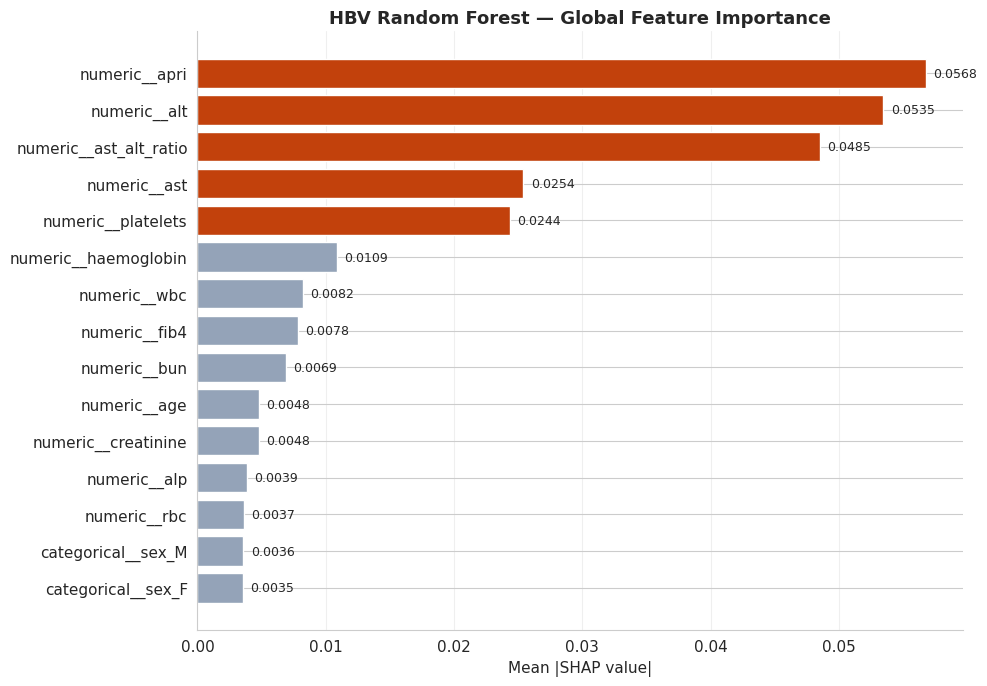

In [ ]:
# Bar chart of feature importance — top 15 only for readability
fig, ax = plt.subplots(figsize=(10, 7))
top_n = 15
top_features = sorted_features[:top_n]
top_importance = sorted_importance[:top_n]

# Color top 5 differently to highlight
colors = [RUST if i < 5 else GREY for i in range(top_n)]

ax.barh(range(top_n), top_importance[::-1], color=colors[::-1], edgecolor='white')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features[::-1])
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('HBV Random Forest — Global Feature Importance', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Add value labels on bars
for i, (val, name) in enumerate(zip(top_importance[::-1], top_features[::-1])):
    ax.text(val + max(top_importance) * 0.01, i, f'{val:.4f}',
            va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_importance_hbv.png')
plt.show()

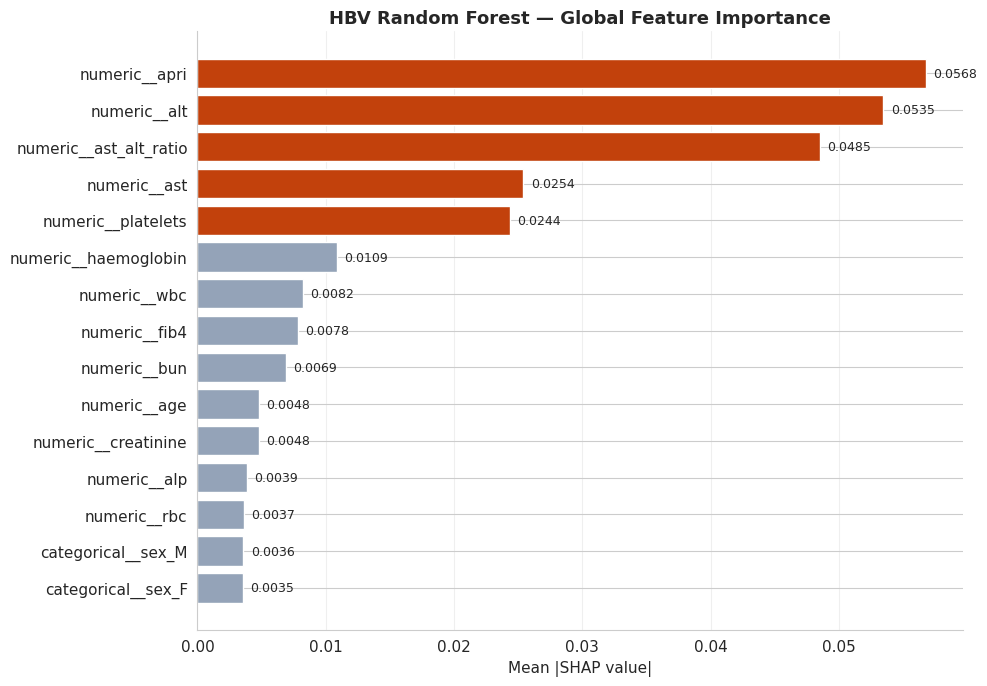

In [ ]:
# Bar chart of feature importance — top 15 only for readability
fig, ax = plt.subplots(figsize=(10, 7))
top_n = 15
top_features = sorted_features[:top_n]
top_importance = sorted_importance[:top_n]

# Color top 5 differently to highlight
colors = [RUST if i < 5 else GREY for i in range(top_n)]

ax.barh(range(top_n), top_importance[::-1], color=colors[::-1], edgecolor='white')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features[::-1])
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('HBV Random Forest — Global Feature Importance', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Add value labels on bars
for i, (val, name) in enumerate(zip(top_importance[::-1], top_features[::-1])):
    ax.text(val + max(top_importance) * 0.01, i, f'{val:.4f}',
            va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_importance_hbv.png')
plt.show()

### 13.4 Beeswarm Summary Plot

The SHAP beeswarm plot is the standard interpretability figure in
clinical ML papers. For each feature it shows:

- **Position on the x-axis:** the SHAP value (how much this feature
  pushed the prediction toward HBV+ for that patient)
- **Colour:** the feature value (red = high feature value, blue = low)

This reveals both the **direction** and **dose-response** of each
feature. For example, if "ALT" shows red dots clustered on the right
(positive SHAP) and blue dots clustered on the left (negative SHAP),
the model has learned "higher ALT → higher HBV+ probability."

/tmp/ipykernel_6889/936158512.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


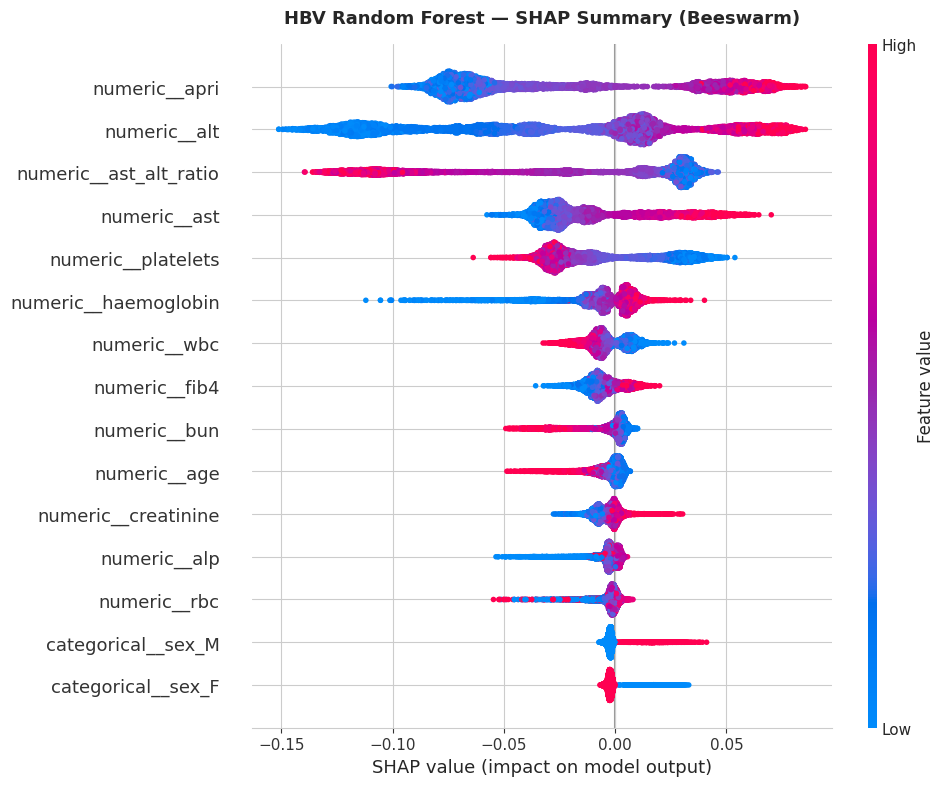

In [ ]:
# Beeswarm plot using SHAP's built-in summary_plot
# Top 15 features for readability
fig = plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_pos,
    X_test_processed,
    feature_names=feature_names_list,
    max_display=15,
    show=False,
    plot_size=None,
)
plt.title('HBV Random Forest — SHAP Summary (Beeswarm)', fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_beeswarm_hbv.png', bbox_inches='tight', dpi=300)
plt.show()

### 13.5 Dependence Plots for Top 2 Features

A dependence plot shows the relationship between a feature's value and
its SHAP contribution across all test patients. It reveals whether the
model learned a linear, non-linear, or threshold relationship.

For each of the top 2 features, the plot shows:
- **x-axis:** the standardised feature value
- **y-axis:** the SHAP value (contribution to HBV+ probability)
- **Colour:** an interaction feature (SHAP picks the most-interacting feature automatically)

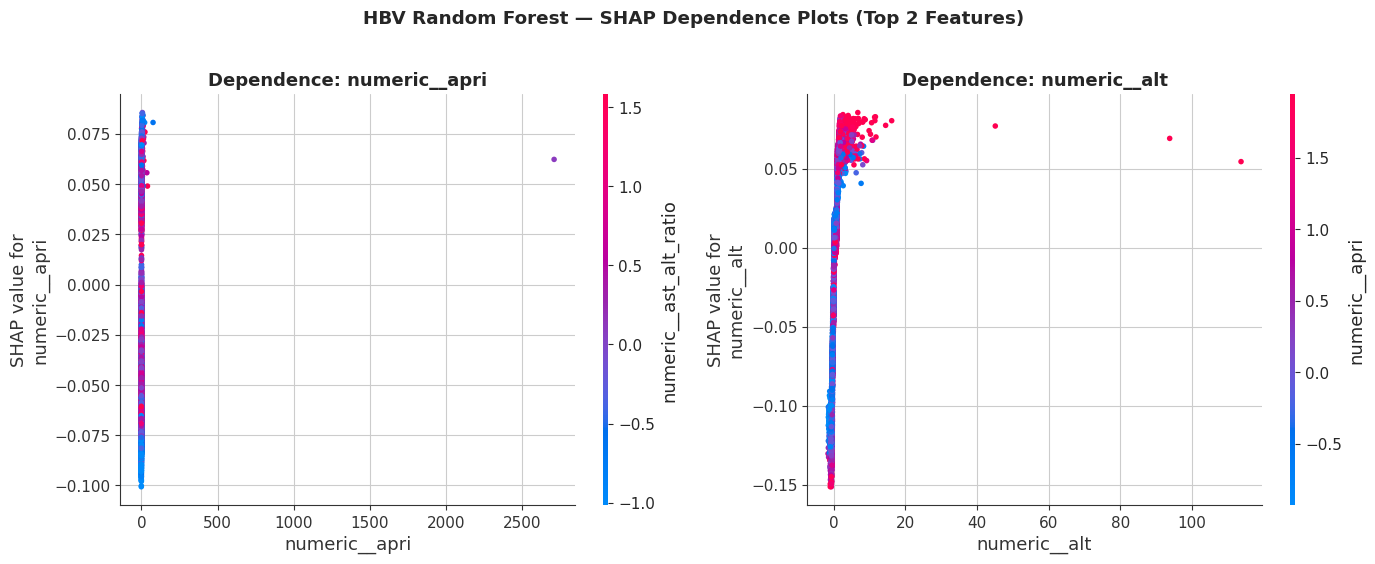

In [ ]:
# Dependence plots for the top 2 features
top2_features = sorted_features[:2]
top2_indices  = [feature_names_list.index(f) for f in top2_features]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, feat_name, feat_idx in zip(axes, top2_features, top2_indices):
    shap.dependence_plot(
        feat_idx,
        shap_values_pos,
        X_test_processed,
        feature_names=feature_names_list,
        ax=ax,
        show=False,
    )
    ax.set_title(f'Dependence: {feat_name}', fontweight='bold')

plt.suptitle('HBV Random Forest — SHAP Dependence Plots (Top 2 Features)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_dependence_hbv.png', bbox_inches='tight', dpi=300)
plt.show()

### 13.6 Individual Prediction Explanations

Waterfall plots explain one prediction at a time. They show how the
model started from a baseline expectation (the mean predicted
probability across the test set) and added/subtracted contributions
from each feature to arrive at this patient's predicted probability.

We show two examples:

1. **A correctly-predicted HBV+ case** — what features drove the
   positive prediction
2. **A correctly-predicted HBV- case** — what features kept the
   prediction negative

For viva preparation, these are the most powerful figures: they let
you say "for this patient the model said X% because of ALT, AST, and
age contributing in this way." That's exactly what clinicians want.

Best-predicted HBV+ case: test index 7090, predicted prob = 0.7683
Best-predicted HBV- case: test index 8889, predicted prob = 0.0757


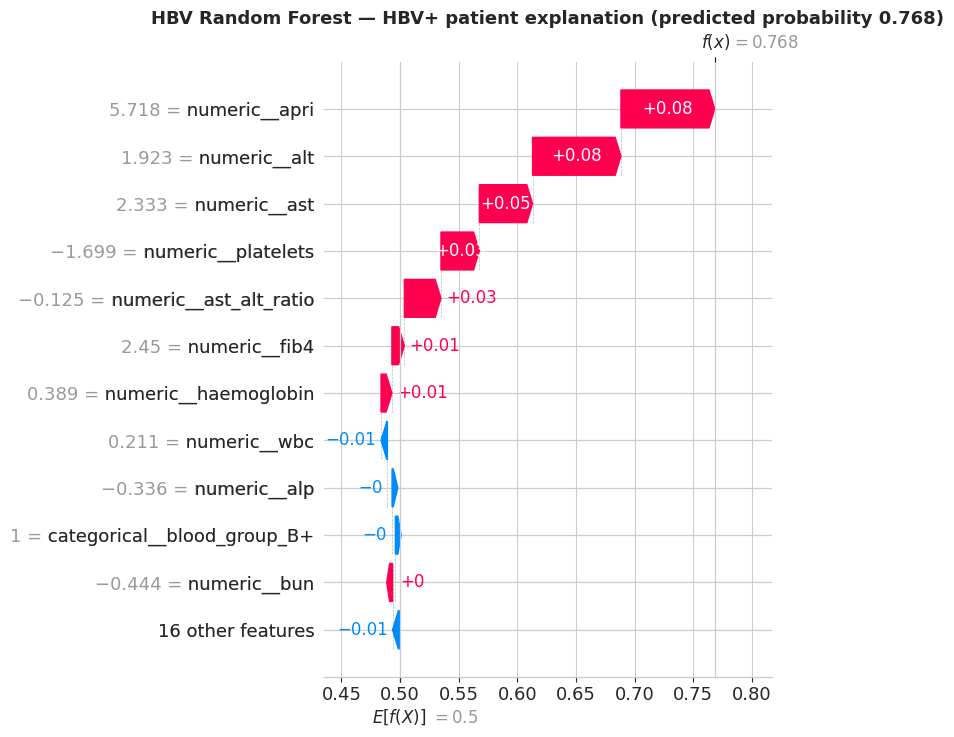

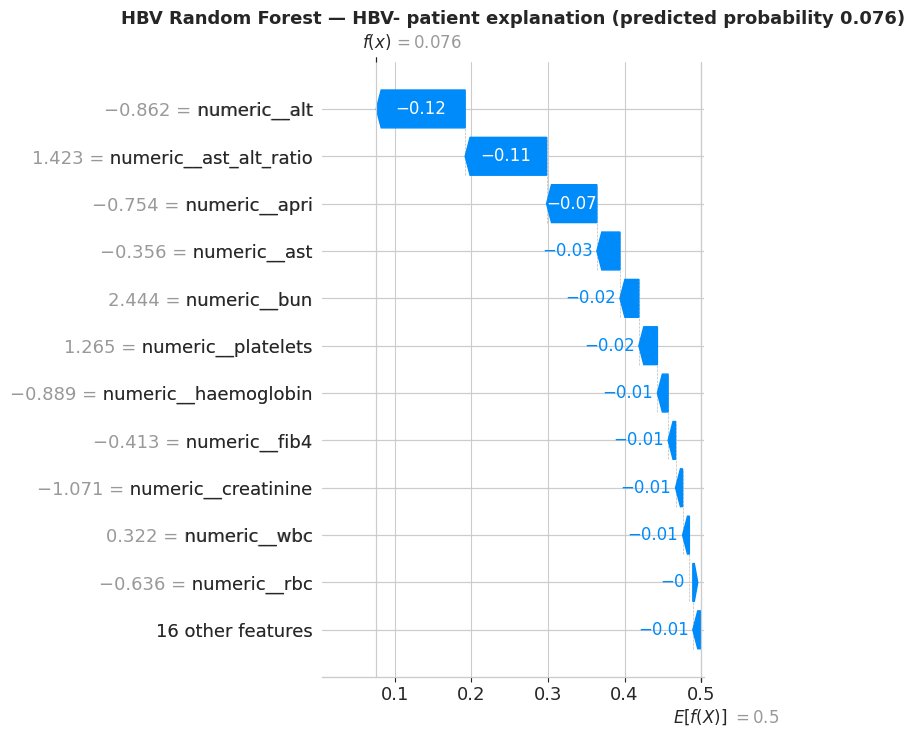

In [ ]:
# Get model predictions on test
y_test_proba = best_rf_hbv.predict_proba(X_test_processed)[:, 1]

# Find one well-predicted HBV+ case (high probability) and one well-predicted HBV- case (low probability)
pos_mask = (y_hbv_test == 1).values
neg_mask = (y_hbv_test == 0).values

# Highest-probability true positive
pos_proba = y_test_proba[pos_mask]
pos_indices = np.where(pos_mask)[0]
best_pos_idx = pos_indices[np.argmax(pos_proba)]

# Lowest-probability true negative
neg_proba = y_test_proba[neg_mask]
neg_indices = np.where(neg_mask)[0]
best_neg_idx = neg_indices[np.argmin(neg_proba)]

print(f"Best-predicted HBV+ case: test index {best_pos_idx}, predicted prob = {y_test_proba[best_pos_idx]:.4f}")
print(f"Best-predicted HBV- case: test index {best_neg_idx}, predicted prob = {y_test_proba[best_neg_idx]:.4f}")

# Waterfall plots
# Get the expected value (baseline)
if isinstance(explainer.expected_value, list):
    expected_value_pos = explainer.expected_value[1]
elif isinstance(explainer.expected_value, np.ndarray):
    expected_value_pos = float(explainer.expected_value[1]) if len(explainer.expected_value) > 1 else float(explainer.expected_value[0])
else:
    expected_value_pos = float(explainer.expected_value)

# Plot HBV+ case
fig = plt.figure(figsize=(11, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_pos[best_pos_idx],
        base_values=expected_value_pos,
        data=X_test_processed[best_pos_idx],
        feature_names=feature_names_list,
    ),
    max_display=12,
    show=False,
)
plt.title(f'HBV Random Forest — HBV+ patient explanation '
          f'(predicted probability {y_test_proba[best_pos_idx]:.3f})',
          fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_waterfall_hbv_positive.png',
            bbox_inches='tight', dpi=300)
plt.show()

# Plot HBV- case
fig = plt.figure(figsize=(11, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_pos[best_neg_idx],
        base_values=expected_value_pos,
        data=X_test_processed[best_neg_idx],
        feature_names=feature_names_list,
    ),
    max_display=12,
    show=False,
)
plt.title(f'HBV Random Forest — HBV- patient explanation '
          f'(predicted probability {y_test_proba[best_neg_idx]:.3f})',
          fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_waterfall_hbv_negative.png',
            bbox_inches='tight', dpi=300)
plt.show()

### 13.7 Summary

Interpretation guide for Chapter 6:

In [ ]:
# Build the interpretive summary
top5_str = ', '.join(sorted_features[:5])
top_feature = sorted_features[0]
top_importance = sorted_importance[0]

# Compare top SHAP features to EDA findings if findings json exists
eda_top_features = []
try:
    with (PROCESSED_DIR / 'eda_findings.json').open() as f:
        findings = json.load(f)
    eda_top_features = findings.get('top_separable_features', [])
except Exception:
    pass

print(f"""
STAGE 3F SUMMARY: SHAP Interpretability for HBV Random Forest
==============================================================

Model:           Random Forest (best HBV classifier)
Test ROC-AUC:    {res_rf['roc_auc_point']:.4f} (95% CI {res_rf['roc_auc_lo']:.4f}-{res_rf['roc_auc_hi']:.4f})
Test set:        {len(X_test_processed):,} records, {(y_hbv_test==1).sum()} HBV+ cases

Top 5 features by mean |SHAP|:
""")
for i, (name, importance) in enumerate(zip(sorted_features[:5], sorted_importance[:5]), 1):
    print(f"  {i}. {name:<35s}  {importance:.4f}")

print(f"""
Single most important feature:  {top_feature}
                                  Mean |SHAP| = {top_importance:.4f}
                                  Top feature accounts for {100*top_importance/mean_abs_shap.sum():.1f}% of total feature importance

Agreement with EDA findings:
  Top separable features identified during EDA: {', '.join(eda_top_features) if eda_top_features else 'unavailable'}
  SHAP top features:                            {top5_str}

Figures saved:
  fig_shap_importance_hbv.png       - global bar chart (top 15 features)
  fig_shap_beeswarm_hbv.png          - beeswarm summary plot
  fig_shap_dependence_hbv.png        - dependence plots for top 2 features
  fig_shap_waterfall_hbv_positive.png - individual HBV+ explanation
  fig_shap_waterfall_hbv_negative.png - individual HBV- explanation

Tables saved:
  shap_feature_importance_hbv.csv    - ranked feature importance table

These outputs go into Chapter 6 as the interpretability section.
""")


STAGE 3F SUMMARY: SHAP Interpretability for HBV Random Forest

Model:           Random Forest (best HBV classifier)
Test ROC-AUC:    0.7233 (95% CI 0.6778-0.7687)
Test set:        9,004 records, 106 HBV+ cases

Top 5 features by mean |SHAP|:

  1. numeric__apri                        0.0568
  2. numeric__alt                         0.0535
  3. numeric__ast_alt_ratio               0.0485
  4. numeric__ast                         0.0254
  5. numeric__platelets                   0.0244

Single most important feature:  numeric__apri
                                  Mean |SHAP| = 0.0568
                                  Top feature accounts for 20.7% of total feature importance

Agreement with EDA findings:
  Top separable features identified during EDA: ALT (U/L), AST (U/L), Platelets (/μL), AST/ALT ratio, Haemoglobin (g/dL)
  SHAP top features:                            numeric__apri, numeric__alt, numeric__ast_alt_ratio, numeric__ast, numeric__platelets

Figures saved:
  fig_shap_impo

## 14. Stage 3G — SHAP Interpretability for the Best HCV Model

Parallel SHAP analysis for the HCV classifier. We use the same
TreeExplainer + Random Forest + test-set computation protocol as the
HBV interpretability section, so the two analyses are directly
comparable in Chapter 6.

**Model explained:** Random Forest (best HCV AUC, 0.972).
**Data:** Held-out test partition.

Outputs:

1. Global feature importance bar chart (top 15)
2. Beeswarm summary plot
3. Dependence plots for top 2 features
4. Waterfall plots for one HCV+ and one HCV- patient
5. Numeric feature-importance table

The expectation is that SHAP top features will overlap substantially
with the HBV SHAP top features — both diseases produce hepatocellular
injury detectable through similar laboratory markers (ALT, AST,
platelets). Differences would indicate disease-specific signal that the
model has learned.

### 14.1 Compute SHAP Values for the Best HCV Model

SHAP values are computed on the held-out test partition. The model used here is whichever classifier won the Section 11 grid by CV AUC. To force a different model (for example, to compare against the Random Forest specifically), set `best_hcv_override` in the cell below.


In [ ]:
# Auto-route to whichever HCV model won the Section 11 grid.
# Set best_hcv_override to a model name (e.g. 'Random Forest') to force a
# specific choice; leave as None to use the overall best.
best_hcv_override = None

if best_hcv_override is not None:
    best_hcv_result = next(r for r in all_results_hcv if r['name'] == best_hcv_override)
else:
    best_hcv_result = best_hcv  # set in Section 11.8

print(f"SHAP target model: {best_hcv_result['name']}")
print(f"  Configuration:   {best_hcv_result['config_id']} ({best_hcv_result['config_label']})")
print(f"  Test ROC-AUC:    {best_hcv_result['roc_auc_point']:.4f}")

# Unwrap the underlying classifier from the imblearn pipeline (if wrapped)
hcv_pipeline = best_hcv_result['estimator']
if hasattr(hcv_pipeline, 'named_steps') and 'classifier' in hcv_pipeline.named_steps:
    best_hcv_classifier = hcv_pipeline.named_steps['classifier']
    print(f"  Extracted classifier from pipeline: {type(best_hcv_classifier).__name__}")
else:
    best_hcv_classifier = hcv_pipeline
    print(f"  Using estimator directly: {type(best_hcv_classifier).__name__}")

# Backward-compatible alias
best_rf_hcv = best_hcv_classifier

# TreeExplainer works for tree ensembles only. Warn if winner is something else.
is_tree_model = (
    hasattr(best_hcv_classifier, 'estimators_')
    or hasattr(best_hcv_classifier, 'tree_')
    or 'GradientBoosting' in type(best_hcv_classifier).__name__
    or 'RandomForest'     in type(best_hcv_classifier).__name__
    or 'DecisionTree'     in type(best_hcv_classifier).__name__
)
if not is_tree_model:
    print(f"\nNote: TreeExplainer is designed for tree-based models. "
          f"Winning model is {type(best_hcv_classifier).__name__}, which is not tree-based.")
    print(f"Either set best_hcv_override = 'Random Forest' above, or accept slower KernelExplainer.")

explainer_hcv = shap.TreeExplainer(best_hcv_classifier)

print("\nComputing SHAP values on test partition...")
shap_values_hcv_all = explainer_hcv.shap_values(X_test_hcv)

if isinstance(shap_values_hcv_all, list):
    shap_values_hcv_pos = shap_values_hcv_all[1]
else:
    if shap_values_hcv_all.ndim == 3:
        shap_values_hcv_pos = shap_values_hcv_all[:, :, 1]
    else:
        shap_values_hcv_pos = shap_values_hcv_all

print(f"\nSHAP values shape: {shap_values_hcv_pos.shape}")
print(f"Expected:          ({X_test_hcv.shape[0]:,}, {X_test_hcv.shape[1]})")


SHAP target model: Random Forest
  Configuration:   R5 (BorderlineSMOTE-2 k=5 ss=auto)
  Test ROC-AUC:    0.4069
  Extracted classifier from pipeline: RandomForestClassifier

Computing SHAP values on test partition...

SHAP values shape: (9004, 27)
Expected:          (9,004, 27)


### 14.2 Global Feature Importance for HCV

In [ ]:
# Mean absolute SHAP per feature
mean_abs_shap_hcv = np.abs(shap_values_hcv_pos).mean(axis=0)

# Rank features
sorted_idx_hcv = np.argsort(mean_abs_shap_hcv)[::-1]
sorted_features_hcv = [feature_names_list[i] for i in sorted_idx_hcv]
sorted_importance_hcv = mean_abs_shap_hcv[sorted_idx_hcv]

# Importance table
importance_hcv_df = pd.DataFrame({
    'Rank':             range(1, len(sorted_features_hcv) + 1),
    'Feature':          sorted_features_hcv,
    'Mean |SHAP|':      sorted_importance_hcv,
})

print("Global feature importance for HCV (top 15):")
print(importance_hcv_df.head(15).to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Save
importance_hcv_df.to_csv(TABLES_DIR / 'shap_feature_importance_hcv.csv', index=False)
print(f"\nFull importance table saved: {TABLES_DIR / 'shap_feature_importance_hcv.csv'}")

Global feature importance for HCV (top 15):
 Rank                     Feature  Mean |SHAP|
    1         numeric__creatinine       0.0908
    2                numeric__bun       0.0801
    3               numeric__fib4       0.0650
    4                numeric__ast       0.0415
    5               numeric__apri       0.0367
    6 categorical__blood_group_B+       0.0344
    7                numeric__alt       0.0329
    8        numeric__haemoglobin       0.0325
    9          numeric__platelets       0.0308
   10                numeric__age       0.0294
   11                numeric__rbs       0.0136
   12      numeric__ast_alt_ratio       0.0116
   13                numeric__alp       0.0103
   14                numeric__rbc       0.0030
   15                numeric__wbc       0.0026

Full importance table saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/shap_feature_importance_hcv.csv


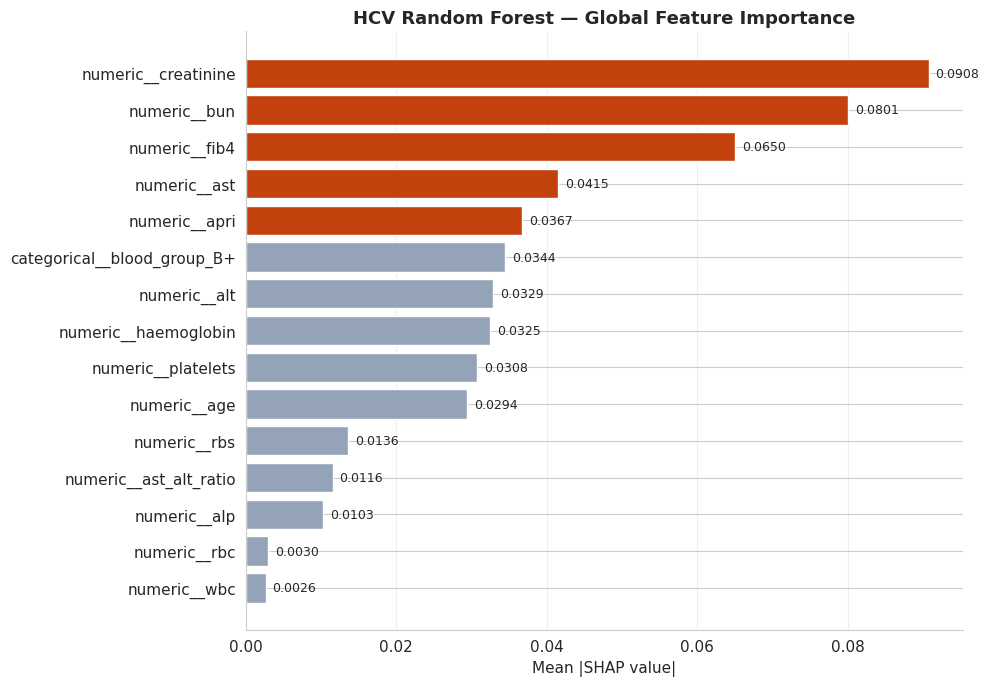

In [ ]:
# Top 15 horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 7))
top_n = 15
top_features_hcv = sorted_features_hcv[:top_n]
top_importance_hcv = sorted_importance_hcv[:top_n]

colors = [RUST if i < 5 else GREY for i in range(top_n)]

ax.barh(range(top_n), top_importance_hcv[::-1], color=colors[::-1], edgecolor='white')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features_hcv[::-1])
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('HCV Random Forest — Global Feature Importance', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

for i, (val, name) in enumerate(zip(top_importance_hcv[::-1], top_features_hcv[::-1])):
    ax.text(val + max(top_importance_hcv) * 0.01, i, f'{val:.4f}',
            va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_importance_hcv.png')
plt.show()

### 14.4 Beeswarm Summary Plot for HCV

/tmp/ipykernel_6889/1443979271.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


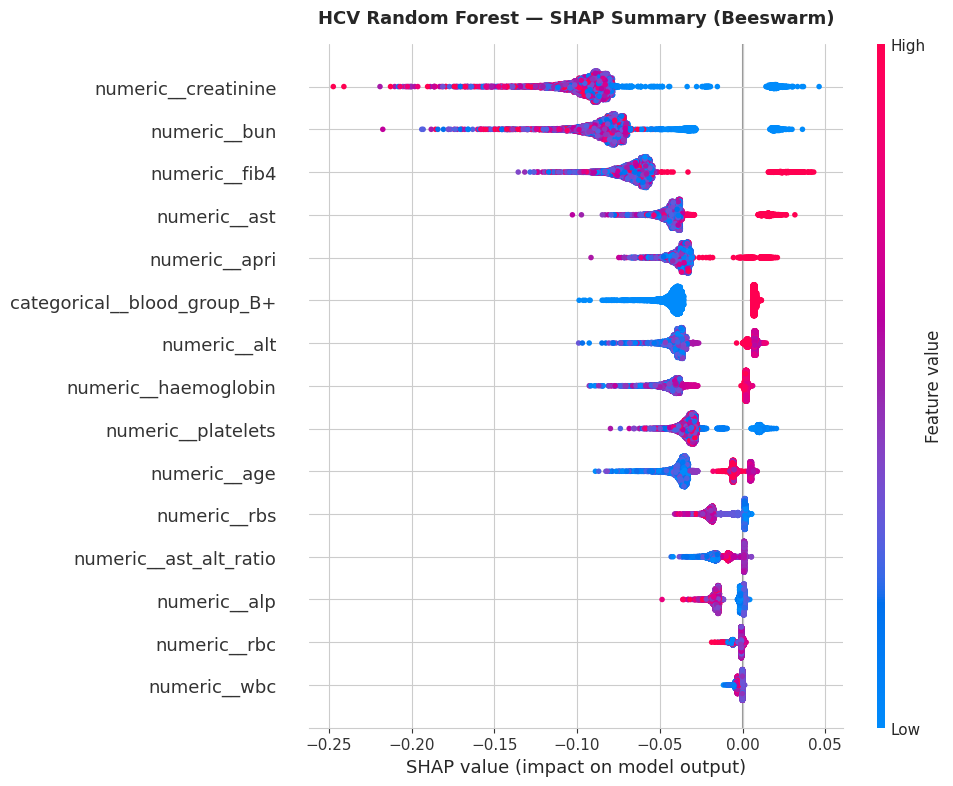

In [ ]:
fig = plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values_hcv_pos,
    X_test_hcv,
    feature_names=feature_names_list,
    max_display=15,
    show=False,
    plot_size=None,
)
plt.title('HCV Random Forest — SHAP Summary (Beeswarm)', fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_beeswarm_hcv.png', bbox_inches='tight', dpi=300)
plt.show()

### 14.5 Dependence Plots for Top 2 HCV Features

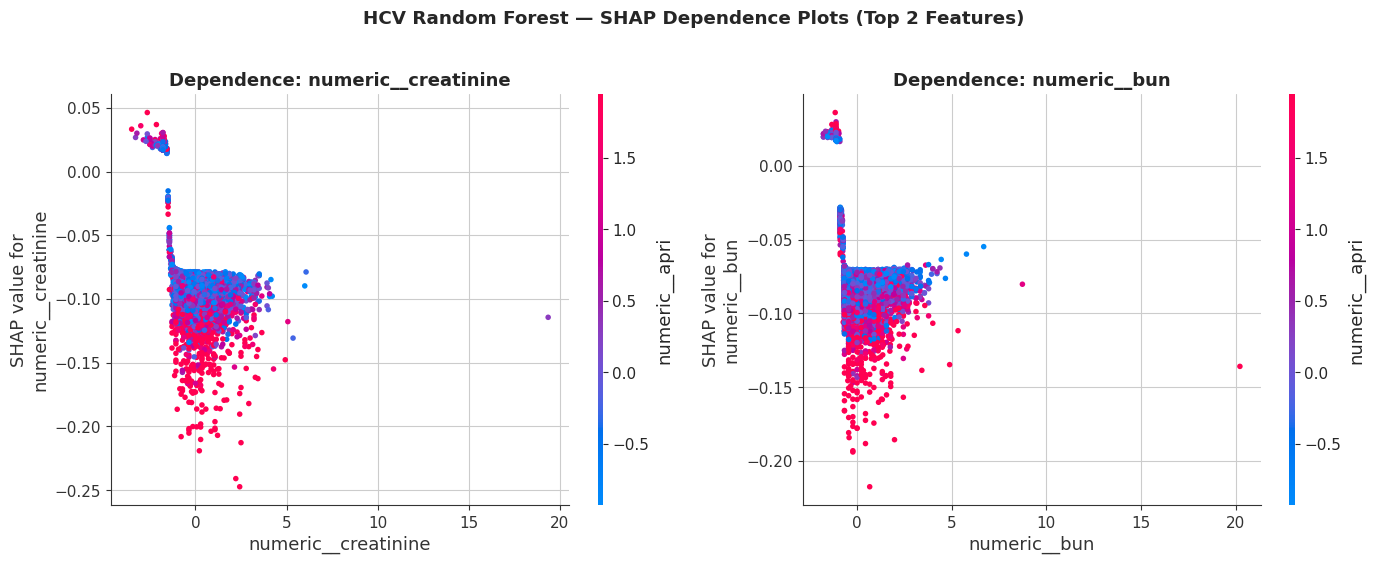

In [ ]:
top2_features_hcv = sorted_features_hcv[:2]
top2_indices_hcv  = [feature_names_list.index(f) for f in top2_features_hcv]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, feat_name, feat_idx in zip(axes, top2_features_hcv, top2_indices_hcv):
    shap.dependence_plot(
        feat_idx,
        shap_values_hcv_pos,
        X_test_hcv,
        feature_names=feature_names_list,
        ax=ax,
        show=False,
    )
    ax.set_title(f'Dependence: {feat_name}', fontweight='bold')

plt.suptitle('HCV Random Forest — SHAP Dependence Plots (Top 2 Features)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_dependence_hcv.png', bbox_inches='tight', dpi=300)
plt.show()

### 14.6 Individual HCV Prediction Explanations

Best-predicted HCV+ case: test index 6791, predicted prob = 0.0004
Best-predicted HCV- case: test index 0, predicted prob = 0.0000


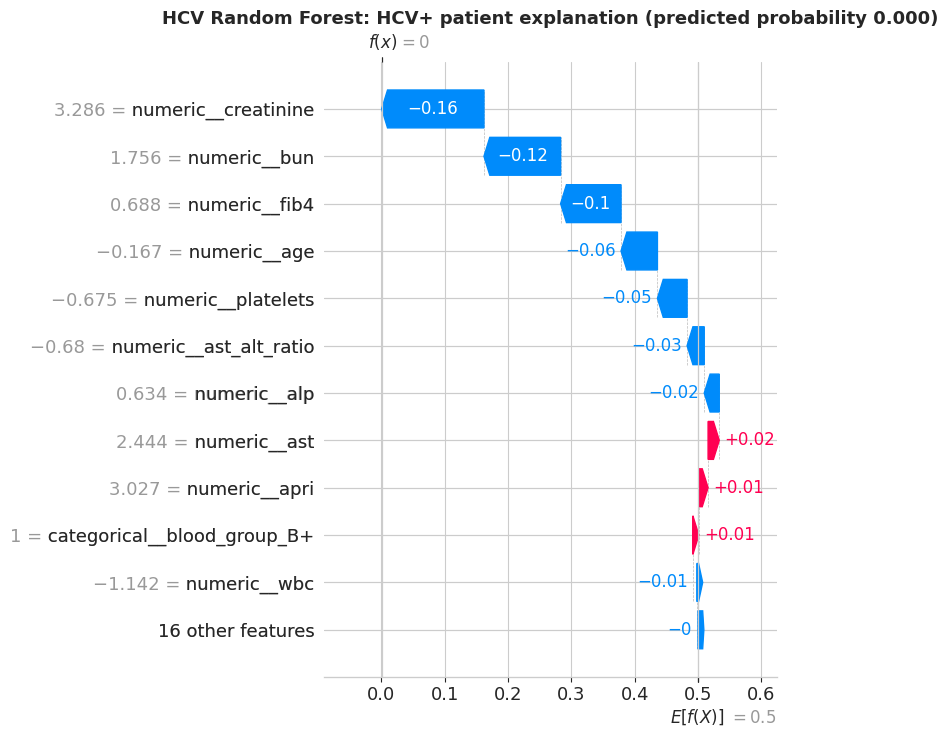

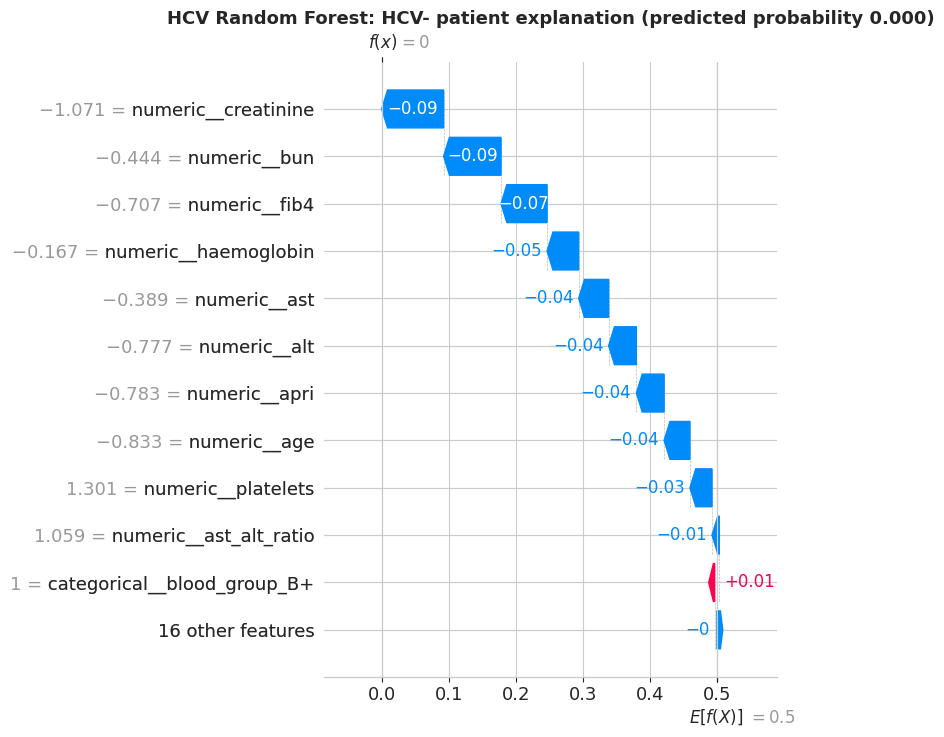

In [ ]:
# Get predictions from the underlying classifier (not the resampler pipeline).
# At inference the resampler step is a no-op, but bypassing it is cleaner.
y_test_proba_hcv = best_hcv_classifier.predict_proba(X_test_hcv)[:, 1]

# Find best-predicted positive and best-predicted negative
pos_mask_hcv     = (y_hcv_test_clean == 1).values
neg_mask_hcv     = (y_hcv_test_clean == 0).values

pos_proba_hcv    = y_test_proba_hcv[pos_mask_hcv]
pos_indices_hcv  = np.where(pos_mask_hcv)[0]
best_pos_idx_hcv = pos_indices_hcv[np.argmax(pos_proba_hcv)]

neg_proba_hcv    = y_test_proba_hcv[neg_mask_hcv]
neg_indices_hcv  = np.where(neg_mask_hcv)[0]
best_neg_idx_hcv = neg_indices_hcv[np.argmin(neg_proba_hcv)]

print(f"Best-predicted HCV+ case: test index {best_pos_idx_hcv}, predicted prob = {y_test_proba_hcv[best_pos_idx_hcv]:.4f}")
print(f"Best-predicted HCV- case: test index {best_neg_idx_hcv}, predicted prob = {y_test_proba_hcv[best_neg_idx_hcv]:.4f}")

# Expected value (baseline)
if isinstance(explainer_hcv.expected_value, list):
    expected_value_pos_hcv = explainer_hcv.expected_value[1]
elif isinstance(explainer_hcv.expected_value, np.ndarray):
    expected_value_pos_hcv = (float(explainer_hcv.expected_value[1])
                              if len(explainer_hcv.expected_value) > 1
                              else float(explainer_hcv.expected_value[0]))
else:
    expected_value_pos_hcv = float(explainer_hcv.expected_value)

model_label = best_hcv_result['name']

# HCV+ waterfall
fig = plt.figure(figsize=(11, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_hcv_pos[best_pos_idx_hcv],
        base_values=expected_value_pos_hcv,
        data=X_test_hcv[best_pos_idx_hcv],
        feature_names=feature_names_list,
    ),
    max_display=12, show=False,
)
plt.title(f"HCV {model_label}: HCV+ patient explanation "
          f"(predicted probability {y_test_proba_hcv[best_pos_idx_hcv]:.3f})",
          fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_waterfall_hcv_positive.png',
            bbox_inches='tight', dpi=300)
plt.show()

# HCV- waterfall
fig = plt.figure(figsize=(11, 6))
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_hcv_pos[best_neg_idx_hcv],
        base_values=expected_value_pos_hcv,
        data=X_test_hcv[best_neg_idx_hcv],
        feature_names=feature_names_list,
    ),
    max_display=12, show=False,
)
plt.title(f"HCV {model_label}: HCV- patient explanation "
          f"(predicted probability {y_test_proba_hcv[best_neg_idx_hcv]:.3f})",
          fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_shap_waterfall_hcv_negative.png',
            bbox_inches='tight', dpi=300)
plt.show()


### 14.7 HCV vs HBV Feature Importance Comparison

Side-by-side comparison of the top SHAP features for HBV and HCV. If
the rankings overlap substantially, it suggests both diseases share
the same hepatocellular injury signature in routine labs. Differences
would indicate disease-specific patterns.

In [ ]:
# Build comparison table — top 10 features per disease, side-by-side
top_n_compare = 10

hbv_top = sorted_features[:top_n_compare]
hcv_top = sorted_features_hcv[:top_n_compare]

comparison_rows = []
for rank in range(top_n_compare):
    hbv_feat = hbv_top[rank]
    hcv_feat = hcv_top[rank]

    hbv_idx_in_hcv = sorted_features_hcv.index(hbv_feat) + 1 if hbv_feat in sorted_features_hcv else 'N/A'
    hcv_idx_in_hbv = sorted_features.index(hcv_feat) + 1 if hcv_feat in sorted_features else 'N/A'

    comparison_rows.append({
        'Rank':              rank + 1,
        'HBV top feature':   hbv_feat,
        'HBV |SHAP|':        f"{sorted_importance[rank]:.4f}",
        'HBV→HCV rank':      str(hbv_idx_in_hcv),
        'HCV top feature':   hcv_feat,
        'HCV |SHAP|':        f"{sorted_importance_hcv[rank]:.4f}",
        'HCV→HBV rank':      str(hcv_idx_in_hbv),
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(TABLES_DIR / 'shap_comparison_hbv_hcv.csv', index=False)

print(f"Saved: {TABLES_DIR / 'shap_comparison_hbv_hcv.csv'}\n")
print(comparison_df.to_string(index=False))

# Compute overlap metrics
hbv_set = set(hbv_top)
hcv_set = set(hcv_top)
overlap = hbv_set & hcv_set
print(f"\nFeature overlap in top {top_n_compare}: {len(overlap)} of {top_n_compare} ({100*len(overlap)/top_n_compare:.0f}%)")
print(f"Shared features: {sorted(overlap)}")
hbv_only = hbv_set - hcv_set
hcv_only = hcv_set - hbv_set
if hbv_only:
    print(f"HBV-only in top {top_n_compare}: {sorted(hbv_only)}")
if hcv_only:
    print(f"HCV-only in top {top_n_compare}: {sorted(hcv_only)}")

Saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/tables/shap_comparison_hbv_hcv.csv

 Rank        HBV top feature HBV |SHAP| HBV→HCV rank             HCV top feature HCV |SHAP| HCV→HBV rank
    1          numeric__apri     0.0568            5         numeric__creatinine     0.0908           11
    2           numeric__alt     0.0535            7                numeric__bun     0.0801            9
    3 numeric__ast_alt_ratio     0.0485           12               numeric__fib4     0.0650            8
    4           numeric__ast     0.0254            4                numeric__ast     0.0415            4
    5     numeric__platelets     0.0244            9               numeric__apri     0.0367            1
    6   numeric__haemoglobin     0.0109            8 categorical__blood_group_B+     0.0344           18
    7           numeric__wbc     0.0082           15                numeric__alt     0.0329            2
    8          numeric__fib4     0.0078            3        nume

### 14.8 Summary

In [ ]:
top5_hcv_str       = ', '.join(sorted_features_hcv[:5])
top_hcv_feature    = sorted_features_hcv[0]
top_hcv_importance = sorted_importance_hcv[0]
model_label        = best_hcv_result['name']
config_label       = best_hcv_result['config_id']

print(f"""
STAGE 3G SUMMARY: SHAP Interpretability for HCV {model_label}
==============================================================

Model:           {model_label} (best HCV classifier, config {config_label})
Test ROC-AUC:    {best_hcv_result['roc_auc_point']:.4f} (95% CI {best_hcv_result['roc_auc_lo']:.4f}-{best_hcv_result['roc_auc_hi']:.4f})
Test set:        {len(X_test_hcv):,} records, {(y_hcv_test_clean == 1).sum()} HCV+ cases

Top 5 features by mean |SHAP|:
""")
for i, (nm, imp) in enumerate(zip(sorted_features_hcv[:5], sorted_importance_hcv[:5]), 1):
    print(f"  {i}. {nm:<35s}  {imp:.4f}")

print(f"""
Single most important feature:  {top_hcv_feature}
                                  Mean |SHAP| = {top_hcv_importance:.4f}
                                  Top feature accounts for {100 * top_hcv_importance / mean_abs_shap_hcv.sum():.1f}% of total feature importance

HBV vs HCV top-5 feature overlap:
  HBV top 5: {', '.join(sorted_features[:5])}
  HCV top 5: {top5_hcv_str}

Figures saved:
  fig_shap_importance_hcv.png          global bar chart (top 15)
  fig_shap_beeswarm_hcv.png            beeswarm summary plot
  fig_shap_dependence_hcv.png          dependence plots for top 2 features
  fig_shap_waterfall_hcv_positive.png  individual HCV+ explanation
  fig_shap_waterfall_hcv_negative.png  individual HCV- explanation

Tables saved:
  shap_feature_importance_hcv.csv      ranked HCV feature importance
  shap_comparison_hbv_hcv.csv          side-by-side HBV/HCV comparison

These outputs feed into Chapter 6 as the HCV interpretability section,
parallel to the HBV interpretability section.
""")



STAGE 3G SUMMARY: SHAP Interpretability for HCV Random Forest

Model:           Random Forest (best HCV classifier, config R5)
Test ROC-AUC:    0.4069 (95% CI 0.3442-0.5279)
Test set:        9,004 records, 6 HCV+ cases

Top 5 features by mean |SHAP|:

  1. numeric__creatinine                  0.0908
  2. numeric__bun                         0.0801
  3. numeric__fib4                        0.0650
  4. numeric__ast                         0.0415
  5. numeric__apri                        0.0367

Single most important feature:  numeric__creatinine
                                  Mean |SHAP| = 0.0908
                                  Top feature accounts for 17.5% of total feature importance

HBV vs HCV top-5 feature overlap:
  HBV top 5: numeric__apri, numeric__alt, numeric__ast_alt_ratio, numeric__ast, numeric__platelets
  HCV top 5: numeric__creatinine, numeric__bun, numeric__fib4, numeric__ast, numeric__apri

Figures saved:
  fig_shap_importance_hcv.png          global bar chart (top

In [ ]:
import importlib.metadata as md
for pkg in ['scikit-learn','imbalanced-learn','shap','numpy','pandas',
            'joblib','matplotlib','seaborn','torch','torchvision',
            'grad-cam','pillow','kagglehub']:
    try:
        print(f"{pkg:20s} {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:20s} NOT INSTALLED")

scikit-learn         1.6.1
imbalanced-learn     0.14.1
shap                 0.51.0
numpy                2.0.2
pandas               2.2.2
joblib               1.5.3
matplotlib           3.10.0
seaborn              0.13.2
torch                2.10.0+cpu
torchvision          0.25.0+cpu
grad-cam             NOT INSTALLED
pillow               11.3.0
kagglehub            1.0.0


## 15. Save Artefacts for App Deployment

This section saves the two random-forest models used in the SHAP attribution
analyses (Sections 13 and 14) to disk, so that the streamlit application
described in the thesis presentation layer can load them.

The HBV random forest is the model used for Tree SHAP in Section 13; HBV
probability predictions in the deployed app come from the calibrated logistic
regression saved in Section 10.

The HCV "winning model" is whichever classifier won the Section 11 grid by
cross-validation AUC. The model is saved together with its configuration label
and the structured null-finding caveat that the thesis reports.

These cells must be run after Sections 13 and 14, when `best_rf_hbv` and
`best_hcv_classifier` are in memory.

In [ ]:
# ----------------------------------------------------------------------
# Save Module A artefacts for streamlit app deployment.
# Run this cell after Section 13 (HBV SHAP) and Section 14 (HCV SHAP)
# have populated the relevant variables in memory.
# ----------------------------------------------------------------------
import pickle

# --- HBV random forest (used for Tree SHAP in Section 13) ---
hbv_rf_file = PROCESSED_DIR / 'hbv_rf_for_shap.pkl'
with hbv_rf_file.open('wb') as f:
    pickle.dump({
        'model':              best_rf_hbv,
        'feature_names_out':  list(feature_names_out),
        'note':               'HBV random forest. Used for Tree SHAP attribution in Section 13. '
                              'For deployed predictions, the calibrated LR (lr_hbv_calibrated.pkl) '
                              'is preferred; this RF supplies the SHAP feature attribution.',
    }, f)
print(f"HBV RF saved: {hbv_rf_file}  ({hbv_rf_file.stat().st_size / 1024:.1f} KB)")

# --- HCV grid winner (used for Tree SHAP in Section 14) ---
hcv_model_file = PROCESSED_DIR / 'hcv_model_for_shap.pkl'
with hcv_model_file.open('wb') as f:
    pickle.dump({
        'model':              best_hcv_classifier,
        'classifier_name':    best_hcv_result['name'],
        'config_id':          best_hcv_result['config_id'],
        'config_label':       best_hcv_result['config_label'],
        'feature_names_out':  list(feature_names_out),
        'test_auc':           best_hcv_result.get('roc_auc_point'),
        'note':               ('HCV grid winner from Section 11. Used for Tree SHAP in Section 14. '
                               'Reported in the thesis as a data-sufficiency null finding; '
                               'test ROC-AUC lower CI does not exceed the no-skill threshold. '
                               'Predictions from this model are shown by the deployed app '
                               'with an explicit low-confidence caveat.'),
    }, f)
print(f"HCV model saved: {hcv_model_file}  ({hcv_model_file.stat().st_size / 1024:.1f} KB)")
print(f"  Classifier: {best_hcv_result['name']}")
print(f"  Config:     {best_hcv_result['config_id']} ({best_hcv_result['config_label']})")

HBV RF saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/hbv_rf_for_shap.pkl  (1295.5 KB)
HCV model saved: /content/drive/MyDrive/MSc_Thesis/hepatitis_module_a/processed/hcv_model_for_shap.pkl  (1310.5 KB)
  Classifier: Random Forest
  Config:     R5 (BorderlineSMOTE-2 k=5 ss=auto)
